# Annex 96 Common Exercise 1 – Quick Start Notebook

This notebook provides a minimal end-to-end setup for:


1. Cloning the CE1 GitHub repository
2. Understanding the TX & VT datasets
3. Visualizing the daily reference district load
4. Running a simple baseline battery RBC controller
5. Evaluating KPIs

If you run into issues, please reach out on the Annex 96 Slack (Common Exercise channel).


# 1. Install Required Dependencies

This Common Exercise uses a **specific version of CityLearn included inside this repository**.

👉 **Do NOT install CityLearn using `pip install citylearn`.**  
This will install a different version that is **not compatible** with the Common Exercise and will cause errors.

Instead, please install all dependencies directly from the repository’s `requirements.txt` file.





### Clone the Common Exercise repository


In [1]:
!git clone https://github.com/kkaspar10/annex96_common_exercise_1.git

Cloning into 'annex96_common_exercise_1'...
remote: Enumerating objects: 9377, done.
remote: Counting objects: 100% (307/307), done.
remote: Compressing objects: 100% (262/262), done.
remote: Total 9377 (delta 93), reused 188 (delta 31), pack-reused 9070 (from 1)
Receiving objects: 100% (9377/9377), 317.29 MiB | 2.15 MiB/s, done.
Resolving deltas: 100% (5248/5248), done.
Updating files: 100% (1311/1311), done.


### Install required Python packages

In [2]:
!pip install -r annex96_common_exercise_1/requirements.txt

ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'annex96_common_exercise_1/requirements.txt'


## 2. Dataset Overview (TX vs VT)

The Common Exercise uses two scenarios:

### 🔵 Texas (TX) – cooling dominated  
- Training: **August**  
- Testing: **September**  
- Higher solar generation, strong cooling loads.

### 🔵 Vermont (VT) – heating dominated  
- Training: **January**  
- Testing: **February**  
- High heating loads, low PV in winter.

Each climate folder contains:

- `schema.json`  
- 25 ResStock buildings  
- Pre-computed district reference load  
- All data handled automatically by CityLearn




In [13]:
import os
import sys
from pathlib import Path

# Where the notebook actually lives
NOTEBOOK_DIR = Path(os.getcwd())

# Repo root = parent of notebooks
REPO_DIR = NOTEBOOK_DIR.parent

print("Notebook directory:", NOTEBOOK_DIR)
print("Repo directory:", REPO_DIR)

# Force CityLearn from cloned repo (optional, see note below)
sys.path.insert(0, str(REPO_DIR))

import citylearn
print("✅ citylearn loaded from:", citylearn.__file__)

# Choose climate: TX or VT
CLIMATE = "VT"  # or "VT"

DATASET_DIR = REPO_DIR / "data" / "datasets" / f"annex96_ce1_{CLIMATE.lower()}_neighborhood"
SCHEMA_PATH = DATASET_DIR / "schema.json"

print("\nClimate:", CLIMATE)
print("Dataset directory:", DATASET_DIR, "| exists:", DATASET_DIR.exists())
print("Schema path:", SCHEMA_PATH, "| exists:", SCHEMA_PATH.exists())


Notebook directory: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks
Repo directory: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1
✅ citylearn loaded from: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/__init__.py

Climate: VT
Dataset directory: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/data/datasets/annex96_ce1_vt_neighborhood | exists: True
Schema path: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/data/datasets/annex96_ce1_vt_neighborhood/schema.json | exists: True


## 3. District Load Target

Each day, the Annex 96 CE defines a **constant district load target** equal to the average aggregated demand of all buildings for the each day.

Controllers attempt to track this reference profile.

Below is the reference load plot for the selected climate (TX or VT).

![District Target](../assets/images/district_load_target.png)



In [2]:
import pandas as pd

district_target_df = pd.read_csv(DATASET_DIR / "district_target.csv")
district_target = district_target_df["district_load_target"].values

## 4. Run a Simple Battery RBC Controller

This baseline:

- Uses the built-in `BasicRBC` controller  
- Controls all buildings through a **central agent**  
- Produces reference KPIs to compare against learning-based methods  


In [3]:
from citylearn.citylearn import CityLearnEnv

env = CityLearnEnv(
    schema=str(SCHEMA_PATH),
    root_directory=str(DATASET_DIR),
    central_agent=True,  
)

observations, info = env.reset()
print("Number of buildings:", len(env.buildings))
print("Action names (first 10):", env.action_names[0])
print("Observation names (first 15):", env.observation_names[0])


Couldn't import dot_parser, loading of dot files will not be possible.
Number of buildings: 25
Action names (first 10): ['electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device', 'electrical_storage', 'heating_device',

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [4]:
env.unwrapped.seconds_per_time_step

3600

In [5]:
import numpy as np
from citylearn.agents.rbc import BasicBatteryRBC

obs, info = env.reset()
agent = BasicBatteryRBC(env)

while not env.terminated:
    actions = agent.predict(obs)
    obs, reward, terminated, truncated, info = env.step(actions)

district_load_rbc = np.array(env.net_electricity_consumption)


In [6]:
baseline_district_load = np.array(env.net_electricity_consumption_without_storage)
print(len(baseline_district_load))

744


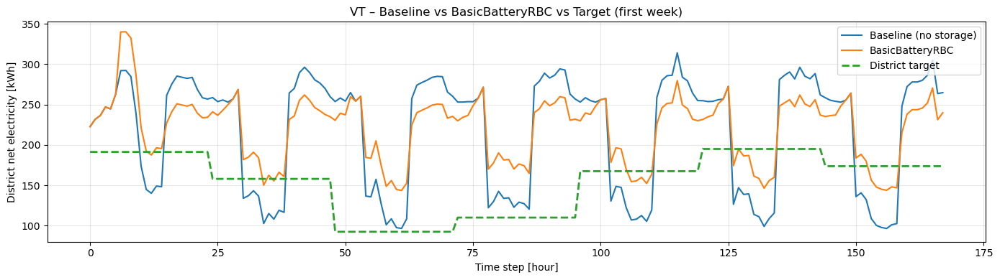

In [7]:
import matplotlib.pyplot as plt

week = 24 * 7
hours = np.arange(week)

plt.figure(figsize=(14,4))
plt.plot(hours, baseline_district_load[:week], label="Baseline (no storage)")
plt.plot(hours, district_load_rbc[:week], label=type(agent).__name__)
plt.plot(hours, district_target[:week], "--", label="District target", linewidth=2)

plt.xlabel("Time step [hour]")
plt.ylabel("District net electricity [kWh]")
plt.title(f"{CLIMATE} – Baseline vs {type(agent).__name__} vs Target (first week)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Evaluate Performance (KPIs)

These KPIs will be used for comparison across all CE1 participants.


## You're all set!

You now have:

- Installed CityLearn requirements 
- Loaded TX or VT scenario  
- Viewed district reference loads  
- Run a baseline RBC  
- Computed comparison KPIs  

If you run into any issue, please reach out in the **Annex 96 Slack**.

Happy experimenting! 🚀


# Dataset Analysis

In [14]:
# system operations
import inspect
import os
import uuid
import warnings

# date and time
import datetime

# type hinting
from typing import Any

# User interaction
from ipywidgets import Button, HTML
from ipywidgets import Text, HBox, VBox

# data visualization
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from tqdm import tqdm

# data manipulation
from bs4 import BeautifulSoup
import math
import numpy as np
import pandas as pd
import random
import re
import requests
import simplejson as json

# cityLearn
from citylearn.agents.base import (
    BaselineAgent,
    Agent as RandomAgent
)
from citylearn.agents.rbc import HourRBC
from citylearn.agents.q_learning import TabularQLearning
from citylearn.citylearn import CityLearnEnv
from citylearn.data import DataSet
from citylearn.reward_function import RewardFunction, ComfortReward
from citylearn.wrappers import (
    NormalizedObservationWrapper,
    StableBaselines3Wrapper,
    TabularQLearningWrapper
)
from citylearn.agents.rbc import TemperatureBasedRBC
from citylearn.agents.rbc import PITemperatureController, PIDTemperatureController

# RL algorithms
from stable_baselines3 import SAC, PPO
import do_mpc

import copy

In [15]:
import importlib, helpers
importlib.reload(helpers)
from helpers import select_buildings, select_simulation_period, get_kpis, plot_building_kpis, plot_district_kpis, plot_building_load_profiles, plot_district_load_profiles, plot_battery_soc_profiles, plot_comfort, plot_comfort_with_lstm_1step, make_env, run_env, plot_simulation_summary





In [16]:
# set all plotted figures without margins
plt.rcParams['axes.xmargin'] = 0
plt.rcParams['axes.ymargin'] = 0
%matplotlib inline

# ignore deprecation warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

In [17]:
import json
import pandas as pd

# Load schema.json
with open(SCHEMA_PATH, "r") as f:
    schema = json.load(f)


In [18]:
schema.keys()


dict_keys(['random_seed', 'root_directory', 'central_agent', 'simulation_start_time_step', 'simulation_end_time_step', 'episode_time_steps', 'rolling_episode_split', 'random_episode_split', 'seconds_per_time_step', 'observations', 'actions', 'agent', 'reward_function', 'buildings'])

In [19]:
root_directory = DATASET_DIR
print("Root directory:", root_directory)


Root directory: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/data/datasets/annex96_ce1_vt_neighborhood


In [20]:
# List available buildings
schema["buildings"].keys()


dict_keys(['resstock-amy2018-2021-release-1-112208', 'resstock-amy2018-2021-release-1-147002', 'resstock-amy2018-2021-release-1-179247', 'resstock-amy2018-2021-release-1-199613', 'resstock-amy2018-2021-release-1-20199', 'resstock-amy2018-2021-release-1-216895', 'resstock-amy2018-2021-release-1-223581', 'resstock-amy2018-2021-release-1-245723', 'resstock-amy2018-2021-release-1-247942', 'resstock-amy2018-2021-release-1-319918', 'resstock-amy2018-2021-release-1-376570', 'resstock-amy2018-2021-release-1-408344', 'resstock-amy2018-2021-release-1-409896', 'resstock-amy2018-2021-release-1-411001', 'resstock-amy2018-2021-release-1-425540', 'resstock-amy2018-2021-release-1-4421', 'resstock-amy2018-2021-release-1-460412', 'resstock-amy2018-2021-release-1-467125', 'resstock-amy2018-2021-release-1-481052', 'resstock-amy2018-2021-release-1-485614', 'resstock-amy2018-2021-release-1-498771', 'resstock-amy2018-2021-release-1-525859', 'resstock-amy2018-2021-release-1-538628', 'resstock-amy2018-2021-rel

In [21]:
building_name = 'resstock-amy2018-2021-release-1-247942'
# building_name = 'resstock-amy2018-2021-release-1-112208'

In [22]:
filename = schema["buildings"][building_name]["energy_simulation"]
filepath = root_directory / filename

print("CSV file:", filepath, "| exists:", filepath.exists())


CSV file: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/data/datasets/annex96_ce1_vt_neighborhood/resstock-amy2018-2021-release-1-247942.csv | exists: True


In [23]:
building_data = pd.read_csv(filepath)
building_data


,month,hour,day_type,daylight_savings_status,indoor_dry_bulb_temperature,indoor_relative_humidity,non_shiftable_load,dhw_demand,cooling_demand,heating_demand,solar_generation,occupant_count,indoor_dry_bulb_temperature_cooling_set_point,indoor_dry_bulb_temperature_heating_set_point,hvac_mode
0,1,1,1,0,18.855238,7.398510,0.391112,0.0,0.0,6.889532,0.0,3.0,18.888890,18.888890,3
1,1,2,1,0,18.888033,7.434287,0.418400,0.0,0.0,5.557705,0.0,3.0,18.888890,18.888890,3
2,1,3,1,0,18.888868,7.534450,0.385681,0.0,0.0,5.259620,0.0,3.0,18.888890,18.888890,3
3,1,4,1,0,18.888890,7.631483,0.382966,0.0,0.0,5.252684,0.0,3.0,18.888890,18.888890,3
4,1,5,1,0,18.888890,7.652065,0.380250,0.0,0.0,5.203944,0.0,3.0,18.888890,18.888890,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,12,20,1,0,22.186089,27.339083,0.811048,0.0,0.0,8.644821,0.0,2.0,22.222221,22.222221,3
8756,12,21,1,0,22.762030,26.426998,0.732618,0.0,0.0,7.998084,0.0,2.0,22.777779,22.777779,3
8757,12,22,1,0,22.777280,26.420078,0.542295,0.0,0.0,6.619469,0.0,2.0,22.777779,22.777779,3
8758,12,23,1,0,21.676556,28.282140,0.512538,0.0,0.0,3.794984,0.0,3.0,21.666666,21.666666,3


In [24]:
building_data.columns

Index(['month', 'hour', 'day_type', 'daylight_savings_status',
       'indoor_dry_bulb_temperature', 'indoor_relative_humidity',
       'non_shiftable_load', 'dhw_demand', 'cooling_demand', 'heating_demand',
       'solar_generation', 'occupant_count',
       'indoor_dry_bulb_temperature_cooling_set_point',
       'indoor_dry_bulb_temperature_heating_set_point', 'hvac_mode'],
      dtype='object')

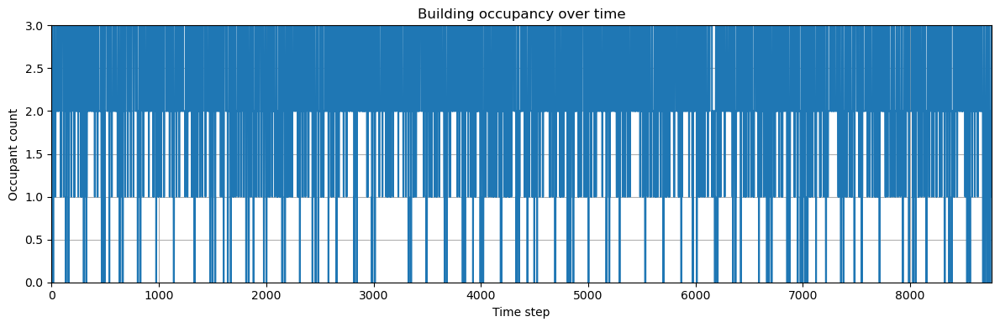

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(building_data["occupant_count"])
plt.xlabel("Time step")
plt.ylabel("Occupant count")
plt.title("Building occupancy over time")
plt.grid(True)
plt.tight_layout()
plt.show()

In [26]:
import pandas as pd

occ_heatmap = (
    building_data
    .groupby(["month", "hour"])["occupant_count"]
    .mean()
    .unstack(level="hour")
)


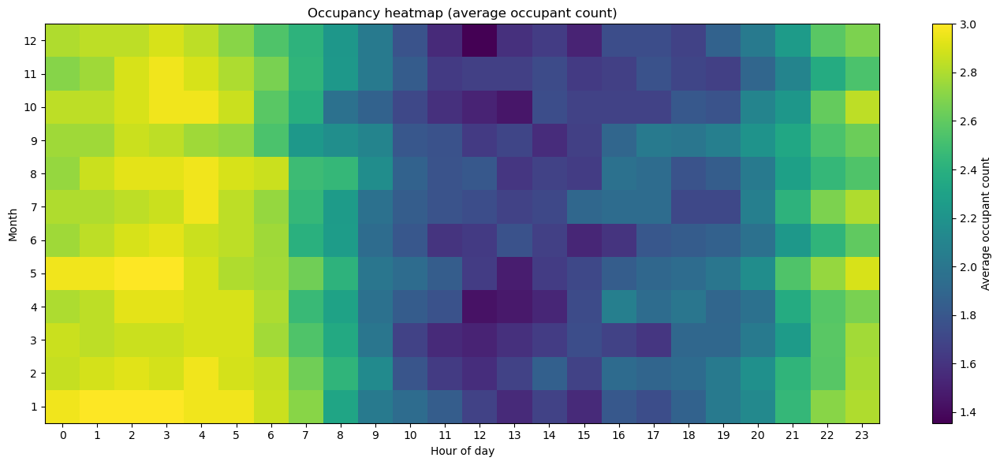

In [27]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(14, 6))
im = plt.imshow(
    occ_heatmap,
    aspect="auto",
    origin="lower",
    cmap="viridis"
)

plt.colorbar(im, label="Average occupant count")

plt.xticks(
    ticks=np.arange(0, 24),
    labels=np.arange(0, 24)
)
plt.yticks(
    ticks=np.arange(len(occ_heatmap.index)),
    labels=occ_heatmap.index
)

plt.xlabel("Hour of day")
plt.ylabel("Month")
plt.title("Occupancy heatmap (average occupant count)")
plt.tight_layout()
plt.show()


In [28]:
building_data["occupant_count"].value_counts().sort_index()


occupant_count
0.0     294
1.0    1065
2.0    3598
3.0    3803
Name: count, dtype: int64

In [29]:
occupant_count_rows = []

for current_building_name, building_info in schema["buildings"].items():
    current_filepath = root_directory / building_info["energy_simulation"]
    current_building_data = pd.read_csv(current_filepath)
    current_counts = current_building_data["occupant_count"].value_counts().sort_index()

    row = {"building_name": current_building_name}
    row.update({int(occupant_count): int(count) for occupant_count, count in current_counts.items()})
    occupant_count_rows.append(row)

occupant_count_table = (
    pd.DataFrame(occupant_count_rows)
    .fillna(0)
    .set_index("building_name")
)

occupant_count_table.columns = [f"occupants_{int(col)}" for col in occupant_count_table.columns]
occupant_count_table = occupant_count_table.astype(int)

print(f"Occupant-count frequency table for all Vermont buildings ({len(occupant_count_table)} buildings)")
display(occupant_count_table)


Occupant-count frequency table for all Vermont buildings (25 buildings)


,occupants_0,occupants_1,occupants_2,occupants_3,occupants_4
building_name,,,,,
resstock-amy2018-2021-release-1-112208,768,3822,4170,0,0
resstock-amy2018-2021-release-1-147002,328,3021,5411,0,0
resstock-amy2018-2021-release-1-179247,360,2939,5461,0,0
resstock-amy2018-2021-release-1-199613,386,1473,6901,0,0
resstock-amy2018-2021-release-1-20199,51,655,2120,2661,3273
resstock-amy2018-2021-release-1-216895,2679,6081,0,0,0
resstock-amy2018-2021-release-1-223581,1087,7673,0,0,0
resstock-amy2018-2021-release-1-245723,1186,7574,0,0,0
resstock-amy2018-2021-release-1-247942,294,1065,3598,3803,0


In [30]:
import pandas as pd
import numpy as np
from pathlib import Path

def load_building_occupancy_series(schema, root_directory, building_name):
    filepath = Path(root_directory) / schema["buildings"][building_name]["energy_simulation"]
    df = pd.read_csv(filepath)
    return df["occupant_count"].astype(int).to_numpy()

In [ ]:
import numpy as np
from sklearn.preprocessing import SplineTransformer
from sklearn.linear_model import LogisticRegression

class BSplineOccupancyPredictor:
    def __init__(
        self,
        n_knots=6,
        degree=3,
        period=24,
        reg_strength=1.0,
        min_samples_per_state=20
    ):
        self.n_knots = n_knots
        self.degree = degree
        self.period = period
        self.reg_strength = reg_strength
        self.min_samples_per_state = min_samples_per_state

        self.states_ = None
        self.state_to_idx_ = None
        self.spline_ = None
        self.models_ = {}
        self.fallback_rows_ = {}

    def _time_feature(self, t_idx):
        return (np.asarray(t_idx) % self.period).reshape(-1, 1)

    def fit(self, occupancy_series):
        y = np.asarray(occupancy_series).astype(int)
        assert len(y) >= 2, "Need at least 2 timesteps."

        current_states = y[:-1]
        next_states = y[1:]
        t_idx = np.arange(len(y) - 1)

        self.states_ = np.sort(np.unique(y))
        self.state_to_idx_ = {state: i for i, state in enumerate(self.states_)}

        # B-spline basis over time-of-day / periodic slot
        X_time = self._time_feature(t_idx)
        self.spline_ = SplineTransformer(
            n_knots=self.n_knots,
            degree=self.degree,
            include_bias=True
        )
        X_bs = self.spline_.fit_transform(X_time)

        s = len(self.states_)

        for state in self.states_:
            mask = current_states == state
            X_state = X_bs[mask]
            y_state = next_states[mask]

            if len(y_state) == 0:
                self.fallback_rows_[state] = np.ones(s) / s
                self.models_[state] = None
                continue

            counts = np.array([(y_state == st).sum() for st in self.states_], dtype=float)
            empirical = counts / counts.sum()

            # If too few samples or only one observed next-state, use fallback
            if len(y_state) < self.min_samples_per_state or np.unique(y_state).size < 2:
                self.fallback_rows_[state] = empirical
                self.models_[state] = None
                continue

            model = LogisticRegression(
                
                multi_class="multinomial",
                solver="lbfgs",
                C=self.reg_strength,
                max_iter=1000
            )
            model.fit(X_state, y_state)

            self.models_[state] = model
            self.fallback_rows_[state] = empirical

        return self

    def transition_matrix(self, t):
        """
        Build P_t of shape (s, s), where rows sum to 1.
        """
        s = len(self.states_)
        P = np.zeros((s, s), dtype=float)

        X_t = self.spline_.transform(self._time_feature([t]))

        for i, state in enumerate(self.states_):
            model = self.models_[state]

            if model is None:
                P[i, :] = self.fallback_rows_[state]
            else:
                proba = np.zeros(s, dtype=float)
                pred = model.predict_proba(X_t)[0]

                # map model.classes_ back to full state list
                for cls, p in zip(model.classes_, pred):
                    j = self.state_to_idx_[cls]
                    proba[j] = p

                # safety normalization
                if proba.sum() == 0:
                    proba = self.fallback_rows_[state]
                else:
                    proba = proba / proba.sum()

                P[i, :] = proba

        return P

    def predict_distribution(self, current_state, start_t, horizon):
        """
        Returns distributions pi_{t+1}, ..., pi_{t+horizon}
        """
        s = len(self.states_)
        pi = np.zeros(s, dtype=float)
        pi[self.state_to_idx_[current_state]] = 1.0

        distributions = []

        for k in range(horizon):
            P = self.transition_matrix(start_t + k)
            pi = pi @ P
            distributions.append(pi.copy())

        return np.array(distributions)

    def predict_expected_occupancy(self, current_state, start_t, horizon):
        distributions = self.predict_distribution(current_state, start_t, horizon)
        expected_occ = distributions @ self.states_
        return expected_occ, distributions

In [32]:
building_name = "resstock-amy2018-2021-release-1-20199"

occupancy_series = load_building_occupancy_series(schema, root_directory, building_name)

model = BSplineOccupancyPredictor(
    n_knots=8,
    degree=3,
    period=24,              # hourly daily pattern
    reg_strength=1.0,
    min_samples_per_state=30
)

model.fit(occupancy_series)

# Example: predict next 24 hours from time t
t = 1000
current_state = occupancy_series[t]

expected_occ, distributions = model.predict_expected_occupancy(
    current_state=current_state,
    start_t=t,
    horizon=24
)

print("Current state:", current_state)
print("Predicted expected occupancy:", expected_occ)
print("Possible states:", model.states_)

Current state: 3
Predicted expected occupancy: [2.62826297 2.61618484 2.80407179 3.05167082 3.29376306 3.51570261
 3.68853972 3.79402477 3.81989253 3.84739735 3.86338675 3.84437522
 3.76014941 3.5804123  3.29304243 2.93669423 2.58627736 2.29706479
 2.10089913 2.01537639 2.02189337 2.07821944 2.13513673 2.18260939]
Possible states: [0 1 2 3 4]


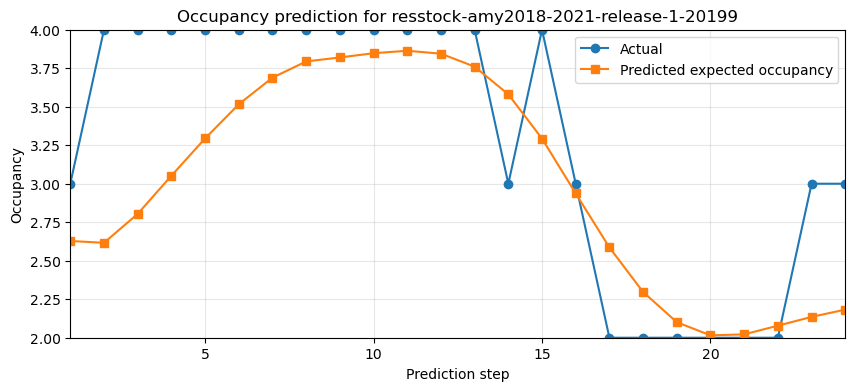

In [ ]:
import matplotlib.pyplot as plt

t = 1000
horizon = 24
current_state = occupancy_series[t]

expected_occ, distributions = model.predict_expected_occupancy(
    current_state=current_state,
    start_t=t,
    horizon=horizon
)

actual_future = occupancy_series[t+1:t+1+horizon]

plt.figure(figsize=(10, 4))
plt.plot(range(1, horizon+1), actual_future, marker='o', label='Actual')
plt.plot(range(1, horizon+1), expected_occ, marker='s', label='Predicted expected occupancy')
plt.xlabel("Prediction step")
plt.ylabel("Occupancy")
plt.title(f"Occupancy prediction for {building_name}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [34]:
import numpy as np
import pandas as pd
from pathlib import Path

from scipy.interpolate import BSpline
from scipy.optimize import minimize
from scipy.special import expit


class AdaptiveBSplineIMC:
    """
    Explicit adaptive B-spline IMC occupancy predictor.

    Paper-inspired model:
        psi_{t,ij} = sum_r phi_{r,ij} * B_{r,D}(t)
        p_{t,ij}   = expit(psi_{t,ij}) / sum_j expit(psi_{t,ij})

    Notes:
    - Uses cubic B-splines via scipy degree=3.
      This corresponds to paper's "cubic" spline. Paper writes D=4
      because that is usually spline order, not scipy degree.
    - Adaptive knots are learned through positive knot increments.
    - One transition row model is fitted per current state i.
    """

    def __init__(
        self,
        period=24,
        spline_degree=3,          # cubic spline in scipy
        n_internal_knots=4,
        l2_phi=1e-3,
        l2_knot=1e-4,
        min_samples_per_state=25,
        maxiter=300,
        random_state=0,
        verbose=False,
    ):
        self.period = period
        self.spline_degree = spline_degree
        self.n_internal_knots = n_internal_knots
        self.l2_phi = l2_phi
        self.l2_knot = l2_knot
        self.min_samples_per_state = min_samples_per_state
        self.maxiter = maxiter
        self.random_state = random_state
        self.verbose = verbose

        self.states_ = None
        self.state_to_idx_ = None

        # per current-state i
        self.row_models_ = {}

    # ------------------------------------------------------------------
    # Utilities
    # ------------------------------------------------------------------
    @staticmethod
    def _softplus(x):
        # numerically stable softplus
        return np.log1p(np.exp(-np.abs(x))) + np.maximum(x, 0)

    def _time_in_period(self, t_idx):
        t_idx = np.asarray(t_idx, dtype=float)
        return np.mod(t_idx, self.period)

    def _build_knot_vector_from_raw(self, raw_deltas):
        """
        Build adaptive interior knots using positive increments.

        raw_deltas shape: (n_internal_knots + 1,)
        These define segment lengths across [0, period]:
            0 --- k1 --- k2 --- ... --- km --- period

        Interior knots are cumulative normalized increments.
        """
        m = self.n_internal_knots
        k = self.spline_degree

        positive = self._softplus(raw_deltas) + 1e-8
        positive = positive / positive.sum()

        segment_lengths = self.period * positive
        boundaries = np.cumsum(segment_lengths)

        # boundaries[-1] == period
        # interior knots exclude first point 0 and final point period
        interior_knots = boundaries[:-1]

        # open clamped knot vector
        knot_vector = np.concatenate([
            np.repeat(0.0, k + 1),
            interior_knots,
            np.repeat(self.period, k + 1)
        ])

        return knot_vector, interior_knots

    def _basis_matrix(self, t_values, raw_deltas):
        """
        Evaluate all B-spline basis functions at t_values.

        Returns:
            B : shape (n_samples, n_basis)
            knot_vector
            interior_knots
        """
        t_values = np.asarray(t_values, dtype=float)
        k = self.spline_degree

        knot_vector, interior_knots = self._build_knot_vector_from_raw(raw_deltas)
        n_basis = len(knot_vector) - k - 1

        B = np.zeros((len(t_values), n_basis), dtype=float)

        for r in range(n_basis):
            coeff = np.zeros(n_basis)
            coeff[r] = 1.0
            spline = BSpline(knot_vector, coeff, k, extrapolate=False)
            B[:, r] = spline(t_values)

        # Guard against tiny negatives from floating point
        B[B < 0] = 0.0

        # Optional normalization per row if needed numerically
        row_sums = B.sum(axis=1, keepdims=True)
        valid = row_sums.squeeze() > 0
        B[valid] /= row_sums[valid]

        return B, knot_vector, interior_knots

    def _pack_params(self, Phi, raw_deltas):
        return np.concatenate([Phi.ravel(), raw_deltas])

    def _unpack_params(self, params, n_basis, n_next_states):
        phi_size = n_basis * n_next_states
        Phi = params[:phi_size].reshape(n_basis, n_next_states)
        raw_deltas = params[phi_size:]
        return Phi, raw_deltas

    # ------------------------------------------------------------------
    # Probability model
    # ------------------------------------------------------------------
    def _row_probabilities(self, B, Phi):
        """
        B:   (n_samples, n_basis)
        Phi: (n_basis, s)

        psi = B @ Phi
        p   = expit(psi) / sum_j expit(psi)
        """
        psi = B @ Phi
        q = expit(psi)  # exactly as paper writes
        denom = q.sum(axis=1, keepdims=True)
        denom = np.clip(denom, 1e-12, None)
        P = q / denom
        return P, psi

    def _row_objective(self, params, t_values, y_next_idx, n_next_states):
        """
        Negative log-likelihood + regularization for one current-state row i.
        """
        raw_deltas = params[-(self.n_internal_knots + 1):]
        B, _, _ = self._basis_matrix(t_values, raw_deltas)
        n_basis = B.shape[1]

        Phi = params[:n_basis * n_next_states].reshape(n_basis, n_next_states)
        P, _ = self._row_probabilities(B, Phi)

        probs = P[np.arange(len(y_next_idx)), y_next_idx]
        probs = np.clip(probs, 1e-12, 1.0)
        nll = -np.sum(np.log(probs))

        reg_phi = self.l2_phi * np.sum(Phi**2)
        reg_knot = self.l2_knot * np.sum(raw_deltas**2)

        return nll + reg_phi + reg_knot

    # ------------------------------------------------------------------
    # Fitting
    # ------------------------------------------------------------------
    def fit(self, occupancy_series):
        """
        Fit the adaptive B-spline IMC model on one occupancy sequence.
        """
        y = np.asarray(occupancy_series, dtype=int)
        if len(y) < 2:
            raise ValueError("Need at least 2 occupancy observations.")

        self.states_ = np.sort(np.unique(y))
        self.state_to_idx_ = {state: i for i, state in enumerate(self.states_)}

        y_curr = y[:-1]
        y_next = y[1:]
        t_idx = np.arange(len(y) - 1)
        t_period = self._time_in_period(t_idx)

        s = len(self.states_)
        rng = np.random.default_rng(self.random_state)

        # initial raw deltas -> nearly uniform knot spacing
        raw_deltas0 = np.zeros(self.n_internal_knots + 1)

        # infer n_basis from initial knot vector
        B0, knot_vector0, interior_knots0 = self._basis_matrix(t_period[:1], raw_deltas0)
        n_basis = B0.shape[1]

        self.row_models_ = {}

        for state_i in self.states_:
            mask = (y_curr == state_i)
            t_i = t_period[mask]
            y_next_i = y_next[mask]
            y_next_idx = np.array([self.state_to_idx_[v] for v in y_next_i], dtype=int)

            counts = np.bincount(y_next_idx, minlength=s).astype(float)
            empirical = counts / counts.sum() if counts.sum() > 0 else np.ones(s) / s

            if self.verbose:
                print(f"Fitting row for current state {state_i}: {len(y_next_i)} samples")

            # fallback if too sparse
            if len(y_next_i) < self.min_samples_per_state:
                self.row_models_[state_i] = {
                    "fitted": False,
                    "empirical_probs": empirical,
                    "Phi": None,
                    "raw_deltas": raw_deltas0.copy(),
                    "interior_knots": interior_knots0.copy(),
                    "knot_vector": knot_vector0.copy(),
                }
                continue

            # initialize Phi near empirical logits-ish values
            # since p_j = expit(psi_j)/sum expit(psi_j), a rough start is constant columns
            eps = 1e-6
            target_q = np.clip(empirical, eps, 1 - eps)
            psi0 = np.log(target_q / (1 - target_q))  # inverse expit, rough start
            Phi0 = np.tile(psi0, (n_basis, 1)) / n_basis
            Phi0 += 0.01 * rng.standard_normal(Phi0.shape)

            params0 = self._pack_params(Phi0, raw_deltas0)

            result = minimize(
                fun=self._row_objective,
                x0=params0,
                args=(t_i, y_next_idx, s),
                method="L-BFGS-B",
                options={"maxiter": self.maxiter}
            )

            if not result.success and self.verbose:
                print(f"  Warning: optimizer did not fully converge for state {state_i}: {result.message}")

            # unpack with final basis count
            Phi_opt_guess, raw_deltas_opt = self._unpack_params(result.x, n_basis, s)
            _, knot_vector_opt, interior_knots_opt = self._basis_matrix(t_i[:1] if len(t_i) else [0.0], raw_deltas_opt)

            self.row_models_[state_i] = {
                "fitted": True,
                "empirical_probs": empirical,
                "Phi": Phi_opt_guess,
                "raw_deltas": raw_deltas_opt,
                "interior_knots": interior_knots_opt,
                "knot_vector": knot_vector_opt,
                "optimizer_success": result.success,
                "objective_value": result.fun,
                "message": result.message,
            }

        return self

    # ------------------------------------------------------------------
    # Transition matrix and prediction
    # ------------------------------------------------------------------
    def transition_matrix(self, t):
        """
        Build time-varying transition matrix P_t.
        Shape: (s, s)
        """
        if self.states_ is None:
            raise RuntimeError("Model must be fitted first.")

        s = len(self.states_)
        P_t = np.zeros((s, s), dtype=float)
        t_mod = np.array([self._time_in_period([t])[0]])

        for i, state_i in enumerate(self.states_):
            row_model = self.row_models_[state_i]

            if not row_model["fitted"]:
                P_t[i, :] = row_model["empirical_probs"]
                continue

            B, _, _ = self._basis_matrix(t_mod, row_model["raw_deltas"])
            probs, _ = self._row_probabilities(B, row_model["Phi"])
            row = probs[0]

            # safety normalization
            row = np.clip(row, 1e-12, None)
            row /= row.sum()
            P_t[i, :] = row

        return P_t

    def predict_distribution(self, current_state, start_t, horizon):
        """
        Predict pi_{t+1}, ..., pi_{t+horizon}
        from deterministic current state.
        """
        if current_state not in self.state_to_idx_:
            raise ValueError(f"Current state {current_state} was not seen during fit.")

        s = len(self.states_)
        pi = np.zeros(s, dtype=float)
        pi[self.state_to_idx_[current_state]] = 1.0

        distributions = []

        for h in range(horizon):
            P = self.transition_matrix(start_t + h)
            pi = pi @ P
            distributions.append(pi.copy())

        return np.asarray(distributions)

    def predict_expected_occupancy(self, current_state, start_t, horizon):
        """
        Expected occupancy:
            o_hat_{t+n} = sum_j p_{t+n,j} * y_j
        """
        distributions = self.predict_distribution(current_state, start_t, horizon)
        expected = distributions @ self.states_
        return expected, distributions

    def predict_most_likely_state(self, current_state, start_t, horizon):
        distributions = self.predict_distribution(current_state, start_t, horizon)
        idx = np.argmax(distributions, axis=1)
        return self.states_[idx], distributions

    def occupancy_presence(self, current_state, start_t, horizon, alpha=0.5):
        expected, distributions = self.predict_expected_occupancy(current_state, start_t, horizon)
        presence = (expected > alpha).astype(int)
        return presence, expected, distributions

    # ------------------------------------------------------------------
    # Inspection helpers
    # ------------------------------------------------------------------
    def row_coefficients(self, current_state):
        """
        Return Phi for one row i.
        Shape: (n_basis, n_states)
        """
        return self.row_models_[current_state]["Phi"]

    def row_knots(self, current_state):
        """
        Return interior knots for one row i.
        """
        return self.row_models_[current_state]["interior_knots"]

    def describe_row(self, current_state):
        model = self.row_models_[current_state]
        return {
            "current_state": current_state,
            "fitted": model["fitted"],
            "interior_knots": model["interior_knots"],
            "empirical_probs": model["empirical_probs"],
            "optimizer_success": model.get("optimizer_success", None),
            "objective_value": model.get("objective_value", None),
            "message": model.get("message", None),
        }

In [35]:
t = 1000
horizon = 24
current_state = occupancy_series[t]

expected_occ, distributions = model.predict_expected_occupancy(
    current_state=current_state,
    start_t=t,
    horizon=horizon
)

most_likely_states, _ = model.predict_most_likely_state(
    current_state=current_state,
    start_t=t,
    horizon=horizon
)

print("Current state:", current_state)
print("States:", model.states_)
print("Expected occupancy:", expected_occ)
print("Most likely states:", most_likely_states)

AttributeError: 'BSplineOccupancyPredictor' object has no attribute 'predict_most_likely_state'

In [36]:
import matplotlib.pyplot as plt

t = 1000
horizon = 24
current_state = occupancy_series[t]

expected_occ, distributions = model.predict_expected_occupancy(
    current_state=current_state,
    start_t=t,
    horizon=horizon
)

most_likely_states, _ = model.predict_most_likely_state(
    current_state=current_state,
    start_t=t,
    horizon=horizon
)

actual_future = occupancy_series[t+1:t+1+horizon]

plt.figure(figsize=(10, 4))
plt.plot(range(1, horizon+1), actual_future, marker='o', label='Actual')
plt.plot(range(1, horizon+1), expected_occ, marker='s', label='Expected occupancy')
plt.plot(range(1, horizon+1), most_likely_states, marker='^', label='Most likely state')
plt.xlabel("Prediction step")
plt.ylabel("Occupancy")
plt.title(f"Adaptive B-spline IMC prediction for {building_name}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

AttributeError: 'BSplineOccupancyPredictor' object has no attribute 'predict_most_likely_state'

Current state: 3
States: [0 1 2 3 4]
Expected occupancy: [2.691 2.653 2.828 3.089 3.323 3.546 3.729 3.85  3.881 3.901 3.903 3.88
 3.802 3.66  3.278 2.916 2.574 2.286 2.082 1.991 1.985 2.021 2.084 2.159]
Most likely states: [3 3 3 3 3 4 4 4 4 4 4 4 4 4 3 3 2 2 2 2 2 2 2 2]
{'current_state': 0, 'fitted': True, 'interior_knots': array([ 9.14568122,  9.22255786, 11.69517807, 13.02633913]), 'empirical_probs': array([0.21568627, 0.56862745, 0.19607843, 0.01960784, 0.        ]), 'optimizer_success': False, 'objective_value': 43.76721008187839, 'message': 'STOP: TOTAL NO. of f AND g EVALUATIONS EXCEEDS LIMIT'}
{'current_state': 1, 'fitted': True, 'interior_knots': array([ 8.02961046, 14.13932079, 17.3945168 , 17.4526174 ]), 'empirical_probs': array([0.03358779, 0.47022901, 0.38015267, 0.1129771 , 0.00305344]), 'optimizer_success': False, 'objective_value': 680.8459342943329, 'message': 'STOP: TOTAL NO. of f AND g EVALUATIONS EXCEEDS LIMIT'}
{'current_state': 2, 'fitted': True, 'interior_knots'

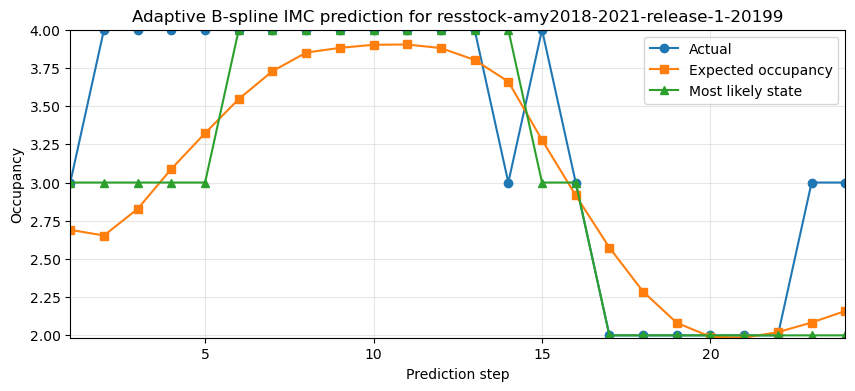

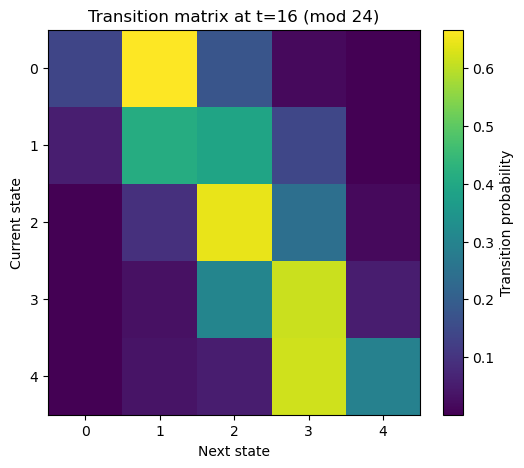

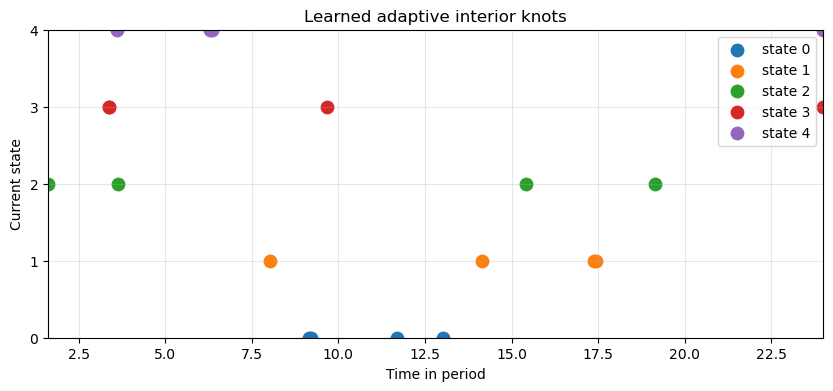

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.interpolate import BSpline
from scipy.optimize import minimize
from scipy.special import expit


def load_building_occupancy_series(schema, root_directory, building_name):
    filepath = Path(root_directory) / schema["buildings"][building_name]["energy_simulation"]
    df = pd.read_csv(filepath)
    return df["occupant_count"].astype(int).to_numpy()


class AdaptiveBSplineOccupancyPredictor:
    """
    Adaptive B-spline IMC-style occupancy predictor.

    Paper-style transition model:
        psi_{t,ij} = sum_r phi_{r,ij} * B_{r,D}(t)
        p_{t,ij}   = expit(psi_{t,ij}) / sum_j expit(psi_{t,ij})

    Notes
    -----
    - scipy's cubic B-spline uses degree=3.
    - Adaptive knots are learned through positive segment lengths.
    - A separate row model is fitted for each current occupancy state.
    """

    def __init__(
        self,
        period=24,
        spline_degree=3,
        n_internal_knots=4,
        l2_phi=1e-3,
        l2_knot=1e-4,
        min_samples_per_state=25,
        maxiter=300,
        random_state=42,
        verbose=False,
    ):
        self.period = period
        self.spline_degree = spline_degree
        self.n_internal_knots = n_internal_knots
        self.l2_phi = l2_phi
        self.l2_knot = l2_knot
        self.min_samples_per_state = min_samples_per_state
        self.maxiter = maxiter
        self.random_state = random_state
        self.verbose = verbose

        self.states_ = None
        self.state_to_idx_ = None
        self.row_models_ = {}

    @staticmethod
    def _softplus(x):
        return np.log1p(np.exp(-np.abs(x))) + np.maximum(x, 0.0)

    def _time_in_period(self, t_idx):
        t_idx = np.asarray(t_idx, dtype=float)
        return np.mod(t_idx, self.period)

    def _build_knot_vector_from_raw(self, raw_deltas):
        k = self.spline_degree

        positive = self._softplus(raw_deltas) + 1e-8
        positive = positive / positive.sum()

        segment_lengths = self.period * positive
        boundaries = np.cumsum(segment_lengths)

        interior_knots = boundaries[:-1]

        knot_vector = np.concatenate([
            np.repeat(0.0, k + 1),
            interior_knots,
            np.repeat(float(self.period), k + 1)
        ])

        return knot_vector, interior_knots

    def _basis_matrix(self, t_values, raw_deltas):
        t_values = np.asarray(t_values, dtype=float)
        k = self.spline_degree

        knot_vector, interior_knots = self._build_knot_vector_from_raw(raw_deltas)
        n_basis = len(knot_vector) - k - 1

        B = np.zeros((len(t_values), n_basis), dtype=float)

        for r in range(n_basis):
            coeff = np.zeros(n_basis, dtype=float)
            coeff[r] = 1.0
            spline = BSpline(knot_vector, coeff, k, extrapolate=False)
            values = spline(t_values)
            values = np.nan_to_num(values, nan=0.0, posinf=0.0, neginf=0.0)
            B[:, r] = values

        B[B < 0] = 0.0

        row_sums = B.sum(axis=1, keepdims=True)
        valid = (row_sums[:, 0] > 0)
        B[valid] /= row_sums[valid]

        return B, knot_vector, interior_knots

    def _row_probabilities(self, B, Phi):
        psi = B @ Phi
        q = expit(psi)
        denom = q.sum(axis=1, keepdims=True)
        denom = np.clip(denom, 1e-12, None)
        P = q / denom
        return P, psi

    def _pack_params(self, Phi, raw_deltas):
        return np.concatenate([Phi.ravel(), raw_deltas])

    def _unpack_params(self, params, n_basis, n_states):
        phi_size = n_basis * n_states
        Phi = params[:phi_size].reshape(n_basis, n_states)
        raw_deltas = params[phi_size:]
        return Phi, raw_deltas

    def _row_objective(self, params, t_values, y_next_idx, n_states):
        raw_deltas = params[-(self.n_internal_knots + 1):]
        B, _, _ = self._basis_matrix(t_values, raw_deltas)
        n_basis = B.shape[1]
        Phi = params[:n_basis * n_states].reshape(n_basis, n_states)

        P, _ = self._row_probabilities(B, Phi)
        probs = P[np.arange(len(y_next_idx)), y_next_idx]
        probs = np.clip(probs, 1e-12, 1.0)

        nll = -np.sum(np.log(probs))
        reg_phi = self.l2_phi * np.sum(Phi ** 2)
        reg_knot = self.l2_knot * np.sum(raw_deltas ** 2)

        return nll + reg_phi + reg_knot

    def fit(self, occupancy_series):
        y = np.asarray(occupancy_series, dtype=int)
        if len(y) < 2:
            raise ValueError("Need at least 2 occupancy observations.")

        self.states_ = np.sort(np.unique(y))
        self.state_to_idx_ = {state: i for i, state in enumerate(self.states_)}

        y_curr = y[:-1]
        y_next = y[1:]
        t_idx = np.arange(len(y) - 1)
        t_period = self._time_in_period(t_idx)

        s = len(self.states_)
        rng = np.random.default_rng(self.random_state)

        raw_deltas0 = np.zeros(self.n_internal_knots + 1, dtype=float)
        B0, knot_vector0, interior_knots0 = self._basis_matrix(np.array([0.0]), raw_deltas0)
        n_basis = B0.shape[1]

        self.row_models_ = {}

        for state_i in self.states_:
            mask = (y_curr == state_i)
            t_i = t_period[mask]
            y_next_i = y_next[mask]
            y_next_idx = np.array([self.state_to_idx_[v] for v in y_next_i], dtype=int)

            counts = np.bincount(y_next_idx, minlength=s).astype(float)
            empirical = counts / counts.sum() if counts.sum() > 0 else np.ones(s) / s

            if self.verbose:
                print(f"Fitting state {state_i}: {len(y_next_i)} transitions")

            if len(y_next_i) < self.min_samples_per_state:
                self.row_models_[state_i] = {
                    "fitted": False,
                    "empirical_probs": empirical,
                    "Phi": None,
                    "raw_deltas": raw_deltas0.copy(),
                    "interior_knots": interior_knots0.copy(),
                    "knot_vector": knot_vector0.copy(),
                    "optimizer_success": None,
                    "objective_value": None,
                    "message": "Too few samples, using empirical fallback."
                }
                continue

            eps = 1e-6
            target_q = np.clip(empirical, eps, 1 - eps)
            psi0 = np.log(target_q / (1 - target_q))
            Phi0 = np.tile(psi0, (n_basis, 1)) / n_basis
            Phi0 += 0.01 * rng.standard_normal(Phi0.shape)

            params0 = self._pack_params(Phi0, raw_deltas0)

            result = minimize(
                fun=self._row_objective,
                x0=params0,
                args=(t_i, y_next_idx, s),
                method="L-BFGS-B",
                options={"maxiter": self.maxiter}
            )

            Phi_opt, raw_deltas_opt = self._unpack_params(result.x, n_basis, s)
            _, knot_vector_opt, interior_knots_opt = self._basis_matrix(np.array([0.0]), raw_deltas_opt)

            self.row_models_[state_i] = {
                "fitted": True,
                "empirical_probs": empirical,
                "Phi": Phi_opt,
                "raw_deltas": raw_deltas_opt,
                "interior_knots": interior_knots_opt,
                "knot_vector": knot_vector_opt,
                "optimizer_success": result.success,
                "objective_value": result.fun,
                "message": result.message,
            }

        return self

    def transition_matrix(self, t):
        if self.states_ is None:
            raise RuntimeError("Fit the model first.")

        s = len(self.states_)
        P_t = np.zeros((s, s), dtype=float)
        t_mod = np.array([self._time_in_period([t])[0]])

        for i, state_i in enumerate(self.states_):
            row_model = self.row_models_[state_i]

            if not row_model["fitted"]:
                row = row_model["empirical_probs"].copy()
            else:
                B, _, _ = self._basis_matrix(t_mod, row_model["raw_deltas"])
                row, _ = self._row_probabilities(B, row_model["Phi"])
                row = row[0]

            row = np.clip(row, 1e-12, None)
            row = row / row.sum()
            P_t[i, :] = row

        return P_t

    def predict_distribution(self, current_state, start_t, horizon):
        if self.states_ is None:
            raise RuntimeError("Fit the model first.")
        if current_state not in self.state_to_idx_:
            raise ValueError(f"Current state {current_state} not seen during fitting.")

        s = len(self.states_)
        pi = np.zeros(s, dtype=float)
        pi[self.state_to_idx_[current_state]] = 1.0

        distributions = []
        for h in range(horizon):
            P = self.transition_matrix(start_t + h)
            pi = pi @ P
            distributions.append(pi.copy())

        return np.asarray(distributions)

    def predict_expected_occupancy(self, current_state, start_t, horizon):
        distributions = self.predict_distribution(current_state, start_t, horizon)
        expected = distributions @ self.states_
        return expected, distributions

    def predict_most_likely_state(self, current_state, start_t, horizon):
        distributions = self.predict_distribution(current_state, start_t, horizon)
        idx = np.argmax(distributions, axis=1)
        return self.states_[idx], distributions

    def occupancy_presence(self, current_state, start_t, horizon, alpha=0.5):
        expected, distributions = self.predict_expected_occupancy(current_state, start_t, horizon)
        presence = (expected > alpha).astype(int)
        return presence, expected, distributions

    def row_knots(self, current_state):
        return self.row_models_[current_state]["interior_knots"]

    def describe_row(self, current_state):
        model = self.row_models_[current_state]
        return {
            "current_state": current_state,
            "fitted": model["fitted"],
            "interior_knots": model["interior_knots"],
            "empirical_probs": model["empirical_probs"],
            "optimizer_success": model["optimizer_success"],
            "objective_value": model["objective_value"],
            "message": model["message"],
        }


# =========================
# Example usage
# =========================

building_name = "resstock-amy2018-2021-release-1-20199"
occupancy_series = load_building_occupancy_series(schema, root_directory, building_name)

adaptive_model = AdaptiveBSplineOccupancyPredictor(
    period=24,
    spline_degree=3,
    n_internal_knots=4,
    l2_phi=1e-3,
    l2_knot=1e-4,
    min_samples_per_state=30,
    maxiter=400,
    random_state=42,
    verbose=False
)

adaptive_model.fit(occupancy_series)

t = 1000
horizon = 24
current_state = occupancy_series[t]

expected_occ, distributions = adaptive_model.predict_expected_occupancy(
    current_state=current_state,
    start_t=t,
    horizon=horizon
)

most_likely_states, _ = adaptive_model.predict_most_likely_state(
    current_state=current_state,
    start_t=t,
    horizon=horizon
)

actual_future = occupancy_series[t + 1:t + 1 + horizon]

print("Current state:", current_state)
print("States:", adaptive_model.states_)
print("Expected occupancy:", np.round(expected_occ, 3))
print("Most likely states:", most_likely_states)

for state in adaptive_model.states_:
    print(adaptive_model.describe_row(state))


# =========================
# Plot 1: actual vs expected vs most likely
# =========================

x = np.arange(1, horizon + 1)

plt.figure(figsize=(10, 4))
plt.plot(x, actual_future, marker='o', label='Actual')
plt.plot(x, expected_occ, marker='s', label='Expected occupancy')
plt.plot(x, most_likely_states, marker='^', label='Most likely state')
plt.xlabel("Prediction step")
plt.ylabel("Occupancy")
plt.title(f"Adaptive B-spline IMC prediction for {building_name}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# =========================
# Plot 2: transition matrix at current time
# =========================

P_t = adaptive_model.transition_matrix(t)

plt.figure(figsize=(6, 5))
plt.imshow(P_t, aspect='auto')
plt.colorbar(label='Transition probability')
plt.xticks(np.arange(len(adaptive_model.states_)), adaptive_model.states_)
plt.yticks(np.arange(len(adaptive_model.states_)), adaptive_model.states_)
plt.xlabel("Next state")
plt.ylabel("Current state")
plt.title(f"Transition matrix at t={t % adaptive_model.period} (mod {adaptive_model.period})")
plt.show()


# =========================
# Plot 3: learned adaptive knots per current state
# =========================

plt.figure(figsize=(10, 4))
for idx, state in enumerate(adaptive_model.states_):
    knots = adaptive_model.row_knots(state)
    y_level = np.full_like(knots, fill_value=idx, dtype=float)
    plt.scatter(knots, y_level, s=80, label=f"state {state}")

plt.yticks(np.arange(len(adaptive_model.states_)), adaptive_model.states_)
plt.xlabel("Time in period")
plt.ylabel("Current state")
plt.title("Learned adaptive interior knots")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

Current state: 3
States: [0 1 2 3 4]
Interior knots: [ 4.8  9.6 14.4 19.2]
Expected occupancy: [2.619 2.602 2.799 3.049 3.318 3.573 3.748 3.853 3.883 3.9   3.905 3.897
 3.796 3.642 3.311 2.914 2.544 2.238 2.032 1.957 1.979 2.051 2.128 2.176]
Most likely states: [3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 3 3 2 2 2 2 2 2 2]
{'current_state': 0, 'fitted': True, 'empirical_probs': array([0.21568627, 0.56862745, 0.19607843, 0.01960784, 0.        ]), 'optimizer_success': True, 'objective_value': 45.39758381434503, 'message': 'CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH'}
{'current_state': 1, 'fitted': True, 'empirical_probs': array([0.03358779, 0.47022901, 0.38015267, 0.1129771 , 0.00305344]), 'optimizer_success': True, 'objective_value': 683.1860556573599, 'message': 'CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH'}
{'current_state': 2, 'fitted': True, 'empirical_probs': array([0.00849057, 0.11650943, 0.63207547, 0.22641509, 0.01650943]), 'optimizer_success': False, 'objective_value': 1897.5880850

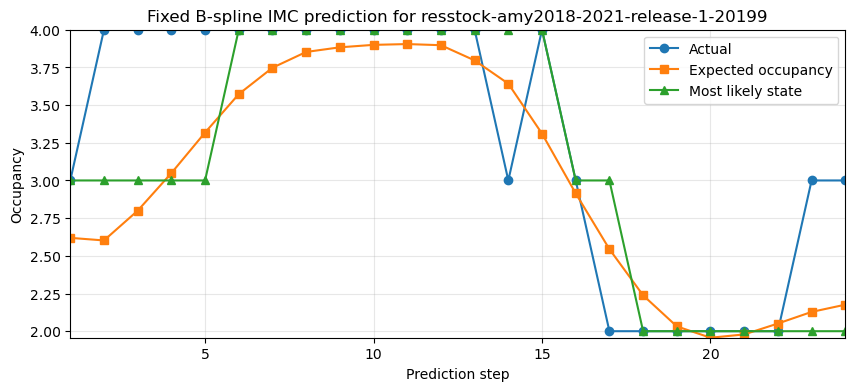

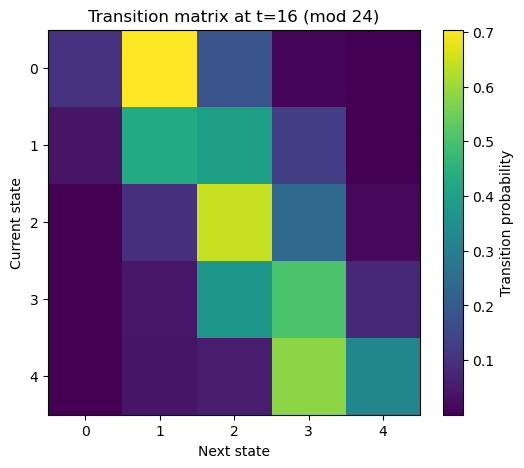

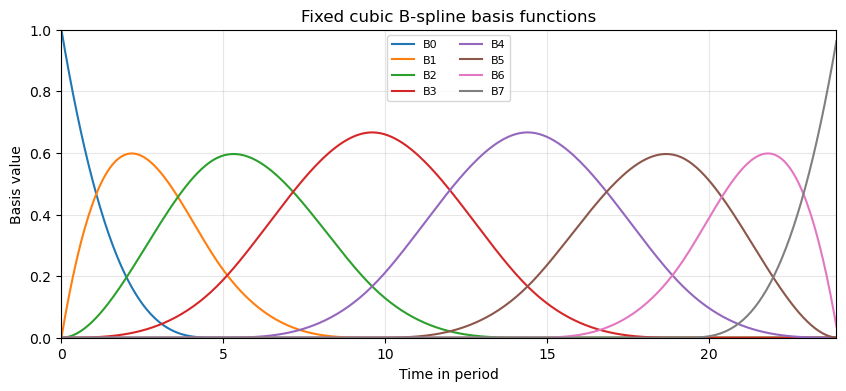

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.interpolate import BSpline
from scipy.optimize import minimize
from scipy.special import expit


def load_building_occupancy_series(schema, root_directory, building_name):
    filepath = Path(root_directory) / schema["buildings"][building_name]["energy_simulation"]
    df = pd.read_csv(filepath)
    return df["occupant_count"].astype(int).to_numpy()


class FixedBSplineIMCOccupancyPredictor:
    """
    Stable explicit IMC-style occupancy predictor with fixed cubic B-splines.

    Model:
        psi_{t,ij} = sum_r phi_{r,ij} B_{r,D}(t)
        p_{t,ij}   = expit(psi_{t,ij}) / sum_j expit(psi_{t,ij})

    Notes
    -----
    - Uses explicit spline basis and explicit Phi coefficients.
    - Uses exact expit-normalization as written in the paper screenshot.
    - Knots are fixed for stability.
    - One row model is fitted per current state.
    """

    def __init__(
        self,
        period=24,
        spline_degree=3,          # cubic spline in scipy
        n_internal_knots=4,
        l2_phi=1e-2,
        min_samples_per_state=25,
        maxiter=2000,
        random_state=42,
        verbose=False
    ):
        self.period = period
        self.spline_degree = spline_degree
        self.n_internal_knots = n_internal_knots
        self.l2_phi = l2_phi
        self.min_samples_per_state = min_samples_per_state
        self.maxiter = maxiter
        self.random_state = random_state
        self.verbose = verbose

        self.states_ = None
        self.state_to_idx_ = None
        self.row_models_ = {}

        self.knot_vector_ = None
        self.interior_knots_ = None
        self.n_basis_ = None

    def _time_in_period(self, t_idx):
        t_idx = np.asarray(t_idx, dtype=float)
        return np.mod(t_idx, self.period)

    def _build_fixed_knot_vector(self):
        k = self.spline_degree

        if self.n_internal_knots > 0:
            interior_knots = np.linspace(
                0.0,
                float(self.period),
                self.n_internal_knots + 2
            )[1:-1]
        else:
            interior_knots = np.array([], dtype=float)

        knot_vector = np.concatenate([
            np.repeat(0.0, k + 1),
            interior_knots,
            np.repeat(float(self.period), k + 1)
        ])

        return knot_vector, interior_knots

    def _basis_matrix(self, t_values):
        t_values = np.asarray(t_values, dtype=float)
        k = self.spline_degree
        knot_vector = self.knot_vector_
        n_basis = len(knot_vector) - k - 1

        B = np.zeros((len(t_values), n_basis), dtype=float)

        for r in range(n_basis):
            coeff = np.zeros(n_basis, dtype=float)
            coeff[r] = 1.0
            spline = BSpline(knot_vector, coeff, k, extrapolate=False)
            vals = spline(t_values)
            vals = np.nan_to_num(vals, nan=0.0, posinf=0.0, neginf=0.0)
            B[:, r] = vals

        B[B < 0] = 0.0

        row_sums = B.sum(axis=1, keepdims=True)
        valid = row_sums[:, 0] > 0
        B[valid] /= row_sums[valid]

        return B

    def _row_probabilities(self, B, Phi):
        psi = B @ Phi
        q = expit(psi)
        denom = np.clip(q.sum(axis=1, keepdims=True), 1e-12, None)
        P = q / denom
        return P, psi

    def _row_objective(self, phi_flat, B, y_next_idx, n_states):
        Phi = phi_flat.reshape(self.n_basis_, n_states)
        P, _ = self._row_probabilities(B, Phi)

        probs = P[np.arange(len(y_next_idx)), y_next_idx]
        probs = np.clip(probs, 1e-12, 1.0)

        nll = -np.sum(np.log(probs))
        reg_phi = self.l2_phi * np.sum(Phi ** 2)

        return nll + reg_phi

    def fit(self, occupancy_series):
        y = np.asarray(occupancy_series, dtype=int)
        if len(y) < 2:
            raise ValueError("Need at least 2 occupancy observations.")

        self.states_ = np.sort(np.unique(y))
        self.state_to_idx_ = {state: i for i, state in enumerate(self.states_)}

        self.knot_vector_, self.interior_knots_ = self._build_fixed_knot_vector()
        self.n_basis_ = len(self.knot_vector_) - self.spline_degree - 1

        y_curr = y[:-1]
        y_next = y[1:]
        t_idx = np.arange(len(y) - 1)
        t_period = self._time_in_period(t_idx)

        s = len(self.states_)
        rng = np.random.default_rng(self.random_state)

        self.row_models_ = {}

        for state_i in self.states_:
            mask = (y_curr == state_i)
            t_i = t_period[mask]
            y_next_i = y_next[mask]
            y_next_idx = np.array([self.state_to_idx_[v] for v in y_next_i], dtype=int)

            counts = np.bincount(y_next_idx, minlength=s).astype(float)
            empirical = counts / counts.sum() if counts.sum() > 0 else np.ones(s) / s

            if self.verbose:
                print(f"Fitting state {state_i}: {len(y_next_i)} transitions")

            if len(y_next_i) < self.min_samples_per_state:
                self.row_models_[state_i] = {
                    "fitted": False,
                    "empirical_probs": empirical,
                    "Phi": None,
                    "optimizer_success": None,
                    "objective_value": None,
                    "message": "Too few samples, using empirical fallback."
                }
                continue

            B_i = self._basis_matrix(t_i)

            eps = 1e-6
            target_q = np.clip(empirical, eps, 1 - eps)
            psi0 = np.log(target_q / (1 - target_q))
            Phi0 = np.tile(psi0, (self.n_basis_, 1)) / self.n_basis_
            Phi0 += 0.01 * rng.standard_normal(Phi0.shape)

            result = minimize(
                fun=self._row_objective,
                x0=Phi0.ravel(),
                args=(B_i, y_next_idx, s),
                method="L-BFGS-B",
                options={"maxiter": self.maxiter}
            )

            Phi_opt = result.x.reshape(self.n_basis_, s)

            self.row_models_[state_i] = {
                "fitted": True,
                "empirical_probs": empirical,
                "Phi": Phi_opt,
                "optimizer_success": result.success,
                "objective_value": result.fun,
                "message": result.message
            }

        return self

    def transition_matrix(self, t):
        if self.states_ is None:
            raise RuntimeError("Fit the model first.")

        s = len(self.states_)
        P_t = np.zeros((s, s), dtype=float)
        t_mod = np.array([self._time_in_period([t])[0]])
        B_t = self._basis_matrix(t_mod)

        for i, state_i in enumerate(self.states_):
            row_model = self.row_models_[state_i]

            if not row_model["fitted"]:
                row = row_model["empirical_probs"].copy()
            else:
                row, _ = self._row_probabilities(B_t, row_model["Phi"])
                row = row[0]

            row = np.clip(row, 1e-12, None)
            row /= row.sum()
            P_t[i, :] = row

        return P_t

    def predict_distribution(self, current_state, start_t, horizon):
        if self.states_ is None:
            raise RuntimeError("Fit the model first.")
        if current_state not in self.state_to_idx_:
            raise ValueError(f"Current state {current_state} not seen during fitting.")

        s = len(self.states_)
        pi = np.zeros(s, dtype=float)
        pi[self.state_to_idx_[current_state]] = 1.0

        distributions = []
        for h in range(horizon):
            P = self.transition_matrix(start_t + h)
            pi = pi @ P
            distributions.append(pi.copy())

        return np.asarray(distributions)

    def predict_expected_occupancy(self, current_state, start_t, horizon):
        distributions = self.predict_distribution(current_state, start_t, horizon)
        expected = distributions @ self.states_
        return expected, distributions

    def predict_most_likely_state(self, current_state, start_t, horizon):
        distributions = self.predict_distribution(current_state, start_t, horizon)
        idx = np.argmax(distributions, axis=1)
        return self.states_[idx], distributions

    def occupancy_presence(self, current_state, start_t, horizon, alpha=0.5):
        expected, distributions = self.predict_expected_occupancy(current_state, start_t, horizon)
        presence = (expected > alpha).astype(int)
        return presence, expected, distributions

    def describe_row(self, current_state):
        model = self.row_models_[current_state]
        return {
            "current_state": current_state,
            "fitted": model["fitted"],
            "empirical_probs": model["empirical_probs"],
            "optimizer_success": model["optimizer_success"],
            "objective_value": model["objective_value"],
            "message": model["message"]
        }


def evaluate_fixed_imc(model, occupancy_series, horizon=24, start_index=24, end_index=None, alpha=0.5):
    y = np.asarray(occupancy_series, dtype=int)

    if end_index is None:
        end_index = len(y) - horizon - 1

    exp_preds = []
    map_preds = []
    actuals = []

    for t in range(start_index, end_index):
        current_state = y[t]

        expected_occ, dist = model.predict_expected_occupancy(
            current_state=current_state,
            start_t=t,
            horizon=horizon
        )
        most_likely = model.states_[np.argmax(dist, axis=1)]
        actual = y[t+1:t+1+horizon]

        exp_preds.append(expected_occ)
        map_preds.append(most_likely)
        actuals.append(actual)

    exp_preds = np.asarray(exp_preds)
    map_preds = np.asarray(map_preds)
    actuals = np.asarray(actuals)

    mae_expected = np.mean(np.abs(exp_preds - actuals))
    rmse_expected = np.sqrt(np.mean((exp_preds - actuals) ** 2))
    acc_map = np.mean(map_preds == actuals)

    actual_presence = (actuals > alpha).astype(int)
    pred_presence = (exp_preds > alpha).astype(int)
    presence_acc = np.mean(pred_presence == actual_presence)

    return {
        "mae_expected": mae_expected,
        "rmse_expected": rmse_expected,
        "accuracy_most_likely_state": acc_map,
        "presence_accuracy": presence_acc
    }


# ============================================================
# EXAMPLE USAGE
# ============================================================

building_name = "resstock-amy2018-2021-release-1-20199"
occupancy_series = load_building_occupancy_series(schema, root_directory, building_name)

fixed_model = FixedBSplineIMCOccupancyPredictor(
    period=24,
    spline_degree=3,
    n_internal_knots=4,
    l2_phi=1e-3,
    min_samples_per_state=30,
    maxiter=1000,
    random_state=42,
    verbose=False
)

fixed_model.fit(occupancy_series)

t = 1000
horizon = 24
current_state = occupancy_series[t]

expected_occ, distributions = fixed_model.predict_expected_occupancy(
    current_state=current_state,
    start_t=t,
    horizon=horizon
)

most_likely_states, _ = fixed_model.predict_most_likely_state(
    current_state=current_state,
    start_t=t,
    horizon=horizon
)

actual_future = occupancy_series[t+1:t+1+horizon]

print("Current state:", current_state)
print("States:", fixed_model.states_)
print("Interior knots:", fixed_model.interior_knots_)
print("Expected occupancy:", np.round(expected_occ, 3))
print("Most likely states:", most_likely_states)

for state in fixed_model.states_:
    print(fixed_model.describe_row(state))

metrics = evaluate_fixed_imc(fixed_model, occupancy_series, horizon=24)
print("Metrics:", metrics)


# ============================================================
# PLOT 1: actual vs expected vs most likely
# ============================================================

x = np.arange(1, horizon + 1)

plt.figure(figsize=(10, 4))
plt.plot(x, actual_future, marker='o', label='Actual')
plt.plot(x, expected_occ, marker='s', label='Expected occupancy')
plt.plot(x, most_likely_states, marker='^', label='Most likely state')
plt.xlabel("Prediction step")
plt.ylabel("Occupancy")
plt.title(f"Fixed B-spline IMC prediction for {building_name}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# ============================================================
# PLOT 2: transition matrix at current time
# ============================================================

P_t = fixed_model.transition_matrix(t)

plt.figure(figsize=(6, 5))
plt.imshow(P_t, aspect='auto')
plt.colorbar(label='Transition probability')
plt.xticks(np.arange(len(fixed_model.states_)), fixed_model.states_)
plt.yticks(np.arange(len(fixed_model.states_)), fixed_model.states_)
plt.xlabel("Next state")
plt.ylabel("Current state")
plt.title(f"Transition matrix at t={t % fixed_model.period} (mod {fixed_model.period})")
plt.show()


# ============================================================
# PLOT 3: basis functions over one day
# ============================================================

time_grid = np.linspace(0, fixed_model.period, 400, endpoint=False)
B_grid = fixed_model._basis_matrix(time_grid)

plt.figure(figsize=(10, 4))
for r in range(B_grid.shape[1]):
    plt.plot(time_grid, B_grid[:, r], label=f"B{r}")
plt.xlabel("Time in period")
plt.ylabel("Basis value")
plt.title("Fixed cubic B-spline basis functions")
plt.grid(True, alpha=0.3)
plt.legend(ncol=2, fontsize=8)
plt.show()

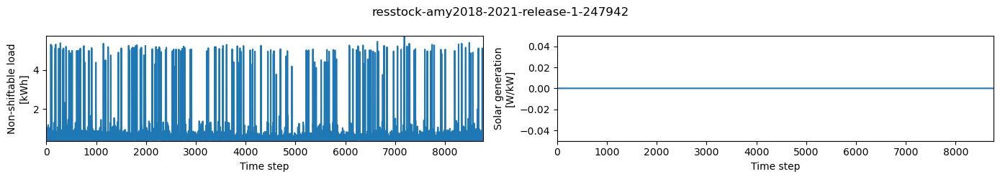

In [25]:
fig, axs = plt.subplots(1, 2, figsize=(14, 2.5))
x = building_data.index
y1 = building_data['non_shiftable_load']
y2 = building_data['solar_generation']
axs[0].plot(x, y1)
axs[0].set_xlabel('Time step')
axs[0].set_ylabel('Non-shiftable load\n[kWh]')
axs[1].plot(x, y2)
axs[1].set_xlabel('Time step')
axs[1].set_ylabel('Solar generation\n[W/kW]')
fig.suptitle(building_name)
plt.tight_layout()
plt.show()

In [26]:
(building_data["daylight_savings_status"] == 0).all()




True

In [27]:
(building_data["solar_generation"] == 0).all()

True

In [28]:
filename = schema['buildings'][building_name]['weather']
filepath = os.path.join(root_directory, filename)
weather_data = pd.read_csv(filepath)
display(weather_data.head())

,outdoor_dry_bulb_temperature,outdoor_relative_humidity,diffuse_solar_irradiance,direct_solar_irradiance,outdoor_dry_bulb_temperature_predicted_1,outdoor_dry_bulb_temperature_predicted_2,outdoor_dry_bulb_temperature_predicted_3,outdoor_relative_humidity_predicted_1,outdoor_relative_humidity_predicted_2,outdoor_relative_humidity_predicted_3,diffuse_solar_irradiance_predicted_1,diffuse_solar_irradiance_predicted_2,diffuse_solar_irradiance_predicted_3,direct_solar_irradiance_predicted_1,direct_solar_irradiance_predicted_2,direct_solar_irradiance_predicted_3
0,-21.333334,72.239760,0.0,0.0,-24.826778,-15.724686,-21.420500,72.642670,48.672695,75.549576,0.000000,63.275528,0.0,0.00000,903.86260,0.0
1,-21.225000,66.637695,0.0,0.0,-24.973806,-16.243246,-22.632126,69.618675,53.450380,71.941440,0.000000,64.781586,0.0,0.00000,747.24810,0.0
2,-21.700000,60.890247,0.0,0.0,-23.852222,-16.396480,-23.085000,72.107330,50.593742,72.346160,33.633380,70.053430,0.0,363.94330,549.33984,0.0
3,-22.800000,67.796640,0.0,0.0,-20.824516,-16.053118,-22.060320,65.655730,52.182840,73.906120,55.751160,46.543180,0.0,633.72186,442.94460,0.0
4,-22.450000,67.860160,0.0,0.0,-19.571860,-17.764027,-24.698364,59.219920,50.297867,68.624130,57.411015,0.000000,0.0,847.80230,0.00000,0.0


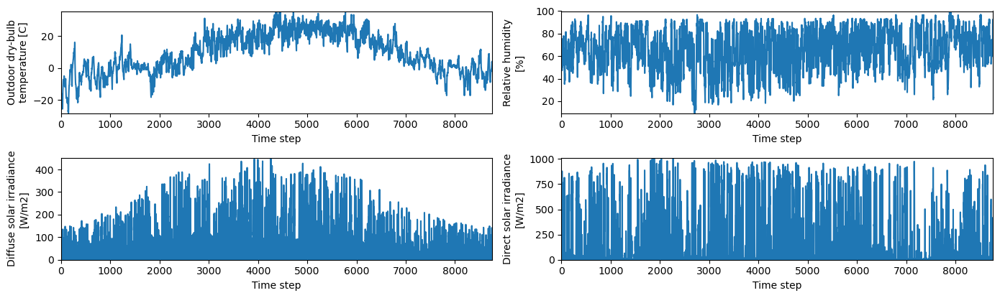

In [29]:
columns = [
    'outdoor_dry_bulb_temperature', 'outdoor_relative_humidity',
    'diffuse_solar_irradiance', 'direct_solar_irradiance'
]
titles = [
    'Outdoor dry-bulb\ntemperature [C]', 'Relative humidity\n[%]',
    'Diffuse solar irradiance\n[W/m2]', 'Direct solar irradiance\n[W/m2]'
]
fig, axs = plt.subplots(2, 2, figsize=(14, 4.25))
x = weather_data.index

for ax, c, t in zip(fig.axes, columns, titles):
    y = weather_data[c]
    ax.plot(x, y)
    ax.set_xlabel('Time step')
    ax.set_ylabel(t)

fig.align_ylabels()
plt.tight_layout()
plt.show()

In [30]:
root_directory = schema['root_directory']

In [31]:
import pandas as pd

district_target_df = pd.read_csv(DATASET_DIR / "district_target.csv")
district_target = district_target_df["district_load_target"].values

In [32]:
district_target_df.head

<bound method NDFrame.head of       district_load_target
0               191.279188
1               191.279188
2               191.279188
3               191.279188
4               191.279188
...                    ...
8755              0.000000
8756              0.000000
8757              0.000000
8758              0.000000
8759              0.000000

[8760 rows x 1 columns]>

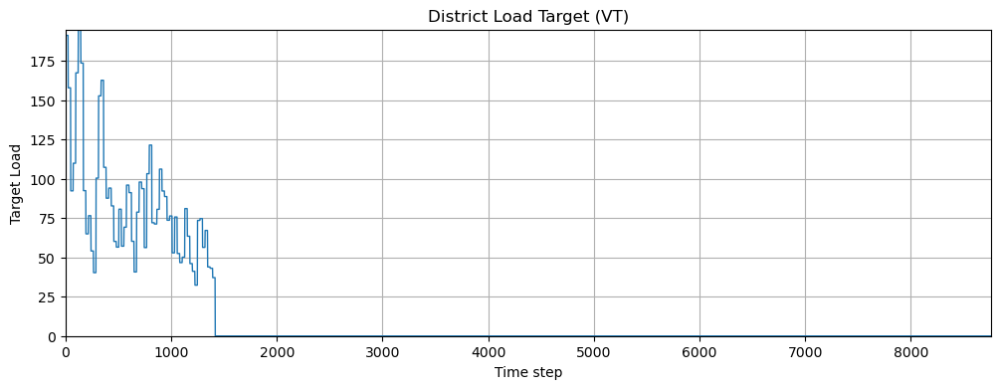

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))
plt.plot(district_target, linewidth=1)
plt.title("District Load Target (VT)")
plt.xlabel("Time step")
plt.ylabel("Target Load")
plt.grid(True)
plt.show()


In [34]:
district_target_df.describe()


,district_load_target
count,8760.000000
mean,13.607239
std,34.609555
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,194.970147


In [35]:
dynamics_error_df = pd.read_csv(DATASET_DIR / "dynamics_error_summary.csv")
dynamics_error_df.head()

,building_name,month,rmse,mape
0,resstock-amy2018-2021-release-1-112208,12,0.548652,2.203952
1,resstock-amy2018-2021-release-1-112208,10,0.532974,2.041352
2,resstock-amy2018-2021-release-1-112208,9,0.539806,2.205957
3,resstock-amy2018-2021-release-1-112208,8,0.707809,2.637470
4,resstock-amy2018-2021-release-1-112208,11,0.654865,2.591323


In [36]:
import importlib, helpers
importlib.reload(helpers)
from helpers import select_buildings, select_simulation_period, get_kpis, plot_building_kpis, plot_district_kpis, plot_building_load_profiles, plot_district_load_profiles, plot_battery_soc_profiles, plot_comfort, plot_comfort_with_lstm_1step, make_env, run_env





In [37]:
import sys, os
print(os.getcwd())
print(sys.path)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks
['/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1', '/home/kostas/anaconda3/lib/python312.zip', '/home/kostas/anaconda3/lib/python3.12', '/home/kostas/anaconda3/lib/python3.12/lib-dynload', '', '/home/kostas/.local/lib/python3.12/site-packages', '/home/kostas/anaconda3/lib/python3.12/site-packages', '/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1', '/home/kostas/anaconda3/lib/python3.12/site-packages/PySAM/']


In [38]:
RANDOM_SEED = 42
BUILDING_COUNT = 1

BUILDINGS = select_buildings(
    schema=schema,
    count=BUILDING_COUNT,
    seed=RANDOM_SEED,
)

print("Selected building(s):", BUILDINGS)


Selected building(s): ['resstock-amy2018-2021-release-1-247942']


In [39]:
RANDOM_SEED = 42
SIM_DAYS = 14  # two weeks

SIMULATION_START_TIME_STEP, SIMULATION_END_TIME_STEP = select_simulation_period(
    schema=schema,
    dataset_dir=DATASET_DIR,
    count=SIM_DAYS,
    seed=RANDOM_SEED
)

print("Simulation start:", SIMULATION_START_TIME_STEP)
print("Simulation end:", SIMULATION_END_TIME_STEP)
print("Duration (hours):", SIMULATION_END_TIME_STEP - SIMULATION_START_TIME_STEP + 1)


Simulation start: 0
Simulation end: 335
Duration (hours): 336


In [40]:
CENTRAL_AGENT = True

In [41]:
env = CityLearnEnv(
    schema=str(SCHEMA_PATH),
    root_directory=str(DATASET_DIR),
    central_agent=CENTRAL_AGENT,
    buildings=BUILDINGS,
    simulation_start_time_step=SIMULATION_START_TIME_STEP,
    simulation_end_time_step=SIMULATION_END_TIME_STEP,
)

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [42]:
print('Current time step:', env.time_step)
print('environment number of time steps:', env.time_steps)
print('environment uses central agent:', env.central_agent)
print('Number of buildings:', len(env.buildings))

Current time step: 0
environment number of time steps: 336
environment uses central agent: True
Number of buildings: 1


In [43]:
# electrical storage
print('Electrical storage capacity:', {
    b.name: b.electrical_storage.capacity for b in env.buildings
})
print('Electrical storage nominal power:', {
    b.name: b.electrical_storage.nominal_power for b in env.buildings
})
print('Electrical storage loss_coefficient:', {
    b.name: b.electrical_storage.loss_coefficient for b in env.buildings
})
print('Electrical storage soc:', {
    b.name: b.electrical_storage.soc[b.time_step] for b in env.buildings
})
print('Electrical storage efficiency:', {
    b.name: b.electrical_storage.efficiency for b in env.buildings
})
print('Electrical storage electricity consumption:', {
    b.name: b.electrical_storage.electricity_consumption[b.time_step]
    for b in env.buildings
})
print('Electrical storage capacity loss coefficient:', {
    b.name: b.electrical_storage.capacity_loss_coefficient for b in env.buildings
})
print()
# pv
print('PV nominal power:', {
    b.name: b.pv.nominal_power for b in env.buildings
})
print()
# active observations
print('Active observations:', {b.name: b.active_observations for b in env.buildings})
# active actions
print('Active actions:', {b.name: b.active_actions for b in env.buildings})

Electrical storage capacity: {'resstock-amy2018-2021-release-1-247942': 13.5}
Electrical storage nominal power: {'resstock-amy2018-2021-release-1-247942': 3.3}
Electrical storage loss_coefficient: {'resstock-amy2018-2021-release-1-247942': 0.003529301675119357}
Electrical storage soc: {'resstock-amy2018-2021-release-1-247942': 0.0}
Electrical storage efficiency: {'resstock-amy2018-2021-release-1-247942': 0.9252930167511936}
Electrical storage electricity consumption: {'resstock-amy2018-2021-release-1-247942': 0.0}
Electrical storage capacity loss coefficient: {'resstock-amy2018-2021-release-1-247942': 3.845464384509277e-05}

PV nominal power: {'resstock-amy2018-2021-release-1-247942': 0.79}

Active observations: {'resstock-amy2018-2021-release-1-247942': ['month', 'hour', 'outdoor_dry_bulb_temperature', 'direct_solar_irradiance', 'outdoor_dry_bulb_temperature_predicted_1', 'outdoor_dry_bulb_temperature_predicted_2', 'outdoor_dry_bulb_temperature_predicted_3', 'direct_solar_irradiance_p

In [44]:

def make_env(**kwargs):
    """
    Create a CityLearn environment.

    Keyword arguments can override any CityLearnEnv parameter,
    e.g. reward_function, active_actions, random_seed, etc.
    """

    base_kwargs = dict(
        schema=str(SCHEMA_PATH),
        root_directory=str(DATASET_DIR),
        central_agent=CENTRAL_AGENT,
        buildings=BUILDINGS,
        simulation_start_time_step=SIMULATION_START_TIME_STEP,
        simulation_end_time_step=SIMULATION_END_TIME_STEP,
        # HVAC ONLY — no batteries
        active_actions=[
            'heating_device',
            # or 'cooling_device'
            # or 'cooling_or_heating_device'α
        ],
    )

    # Override defaults with user-provided arguments
    base_kwargs.update(kwargs)

    return CityLearnEnv(**base_kwargs)

In [45]:
def run_env(env, agent):
    obs, info = env.reset()
    terminated = False
    truncated = False

    while not (terminated or truncated):
        actions = agent.predict(obs)
        obs, reward, terminated, truncated, info = env.step(actions)

    return env

In [46]:
env = CityLearnEnv(
    schema=str(SCHEMA_PATH),
    root_directory=str(DATASET_DIR),
    central_agent=CENTRAL_AGENT,
    buildings=BUILDINGS,
    simulation_start_time_step=SIMULATION_START_TIME_STEP,
    simulation_end_time_step=SIMULATION_END_TIME_STEP,
)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [47]:
env_baseline = make_env()
env_temp_rbc = make_env()
env_pi_rbc = make_env()
sac_env = make_env(reward_function=ComfortReward)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [48]:
sac_env = NormalizedObservationWrapper(sac_env)

In [49]:
sac_env = StableBaselines3Wrapper(sac_env)

In [50]:
sac_model = SAC(policy='MlpPolicy', env=sac_env, seed=RANDOM_SEED, verbose=1)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


In [51]:
baseline_model = BaselineAgent(env_baseline)
temp_rbc = TemperatureBasedRBC(env_temp_rbc)
pi_rbc = PITemperatureController(env_pi_rbc)

/home/kostas/anaconda3/lib/python3.12/site-packages/gymnasium/spaces/box.py:236: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
/home/kostas/anaconda3/lib/python3.12/site-packages/gymnasium/spaces/box.py:306: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


In [52]:
baseline_temp = run_env(env_baseline, baseline_model)

env_temp = run_env(env_temp_rbc, temp_rbc)

env_pi = run_env(env_pi_rbc, pi_rbc)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [62]:
sac_episodes = 15
print('Number of episodes to train:', sac_episodes)
sac_episode_timesteps = sac_env.unwrapped.time_steps - 1
sac_total_timesteps = sac_episodes*sac_episode_timesteps

# ------------------------------- TRAIN MODEL -----------------------------
for i in tqdm(range(sac_episodes)):
    sac_model = sac_model.learn(
        total_timesteps=sac_episode_timesteps,
        reset_num_timesteps=False,
    )

Number of episodes to train: 15


 20%|██        | 3/15 [00:07<00:30,  2.55s/it]

----------------------------------
| rollout/           |           |
|    ep_len_mean     | 335       |
|    ep_rew_mean     | -3.45e+03 |
| time/              |           |
|    episodes        | 4         |
|    fps             | 117       |
|    time_elapsed    | 2         |
|    total_timesteps | 1340      |
| train/             |           |
|    actor_loss      | 64.8      |
|    critic_loss     | 157       |
|    ent_coef        | 0.791     |
|    ent_coef_loss   | -0.0194   |
|    learning_rate   | 0.0003    |
|    n_updates       | 1239      |
----------------------------------


 47%|████▋     | 7/15 [00:19<00:23,  2.97s/it]

----------------------------------
| rollout/           |           |
|    ep_len_mean     | 335       |
|    ep_rew_mean     | -2.03e+03 |
| time/              |           |
|    episodes        | 8         |
|    fps             | 119       |
|    time_elapsed    | 2         |
|    total_timesteps | 2680      |
| train/             |           |
|    actor_loss      | 79.5      |
|    critic_loss     | 75.3      |
|    ent_coef        | 0.732     |
|    ent_coef_loss   | -0.0242   |
|    learning_rate   | 0.0003    |
|    n_updates       | 2579      |
----------------------------------


 73%|███████▎  | 11/15 [00:30<00:10,  2.69s/it]

----------------------------------
| rollout/           |           |
|    ep_len_mean     | 335       |
|    ep_rew_mean     | -1.49e+03 |
| time/              |           |
|    episodes        | 12        |
|    fps             | 123       |
|    time_elapsed    | 2         |
|    total_timesteps | 4020      |
| train/             |           |
|    actor_loss      | 92.4      |
|    critic_loss     | 27.3      |
|    ent_coef        | 0.631     |
|    ent_coef_loss   | -0.0323   |
|    learning_rate   | 0.0003    |
|    n_updates       | 3919      |
----------------------------------


100%|██████████| 15/15 [00:41<00:00,  2.76s/it]


In [63]:
observations, _ = sac_env.reset()
sac_actions_list = []

while not sac_env.unwrapped.terminated:
    actions, _ = sac_model.predict(observations, deterministic=True)
    observations, _, _, _, _ = sac_env.step(actions)
    sac_actions_list.append(actions)

baseline


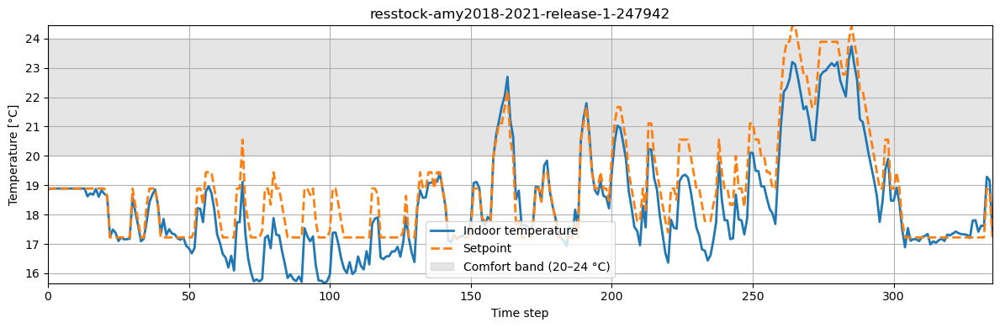

In [53]:
print("baseline")
plot_comfort(baseline_temp)

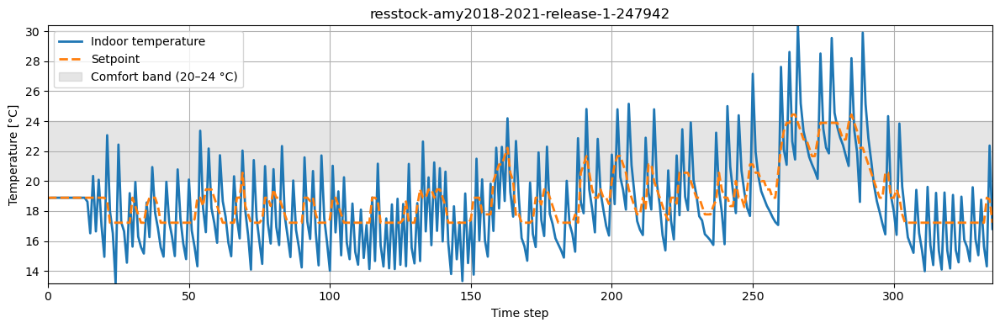

In [54]:
plot_comfort(env_temp)

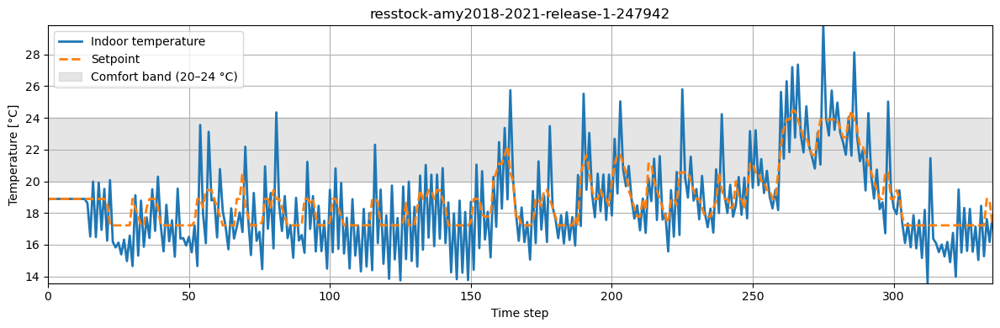

In [55]:
plot_comfort(env_pi)

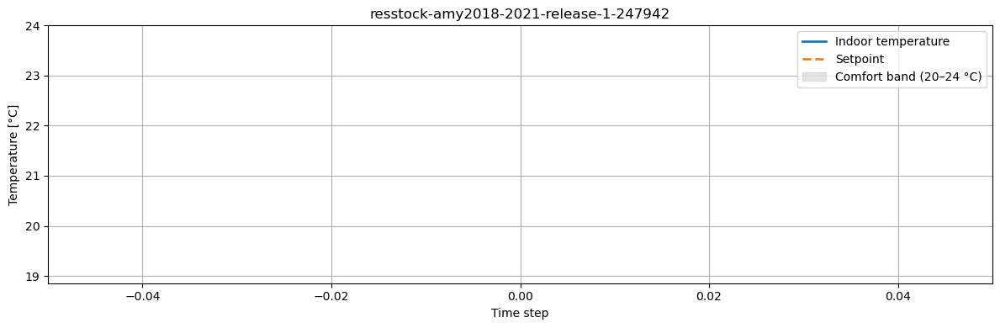

In [56]:
plot_comfort(sac_env)

In [59]:
plot_simulation_summary({
    'Baseline': baseline_temp,
    'Temp_RBC': env_temp,
    'Temp_PI': env_pi,
    'SAC': sac_env,
})

######## BUILDING-LEVEL ########
Building-level KPIs:


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (5,) + inhomogeneous part.

In [69]:
def plot_actions(actions_list: list[list[float]], building_names: list[str], title: str) -> plt.Figure:
    """Plots action time series for different buildings

    Parameters
    ----------
    actions_list: list[list[float]]
        List of actions where each element with index, i,
        in list is a list of the actions for different buildings
        taken at time step i.
    building_names: list[str]:
        List of build names that map to the action lists.
    title: str
        Plot axes title

    Returns
    -------
    fig: plt.Figure
        Figure with plotted axes

    """

    fig, ax = plt.subplots(1, 1, figsize=(6, 1))
    plot_data = pd.DataFrame(actions_list, columns=building_names)
    x = list(range(plot_data.shape[0]))

    for c in plot_data.columns:
        y = plot_data[c].tolist()
        ax.plot(x, y, label=c)

    ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), framealpha=0.0)
    ax.set_xlabel('Time step')
    ax.set_ylabel('HP action')
    ax.xaxis.set_major_locator(ticker.MultipleLocator(24))
    ax.set_title(title)

    return fig

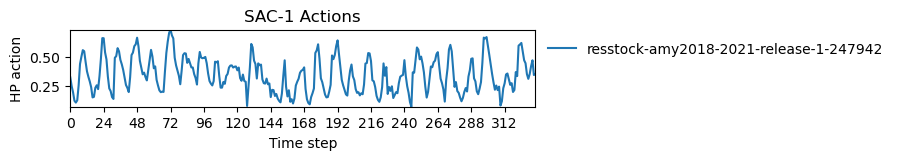

In [70]:
fig = plot_actions(sac_actions_list, BUILDINGS, 'SAC-1 Actions')
plt.show()

# PPO

In [71]:
ppo_env = make_env(reward_function=ComfortReward)
ppo_env = NormalizedObservationWrapper(ppo_env)
ppo_env = StableBaselines3Wrapper(ppo_env)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [72]:
def run_sb3_agent(env, model):
    obs, _ = env.reset()
    terminated = truncated = False

    while not (terminated or truncated):
        action, _ = model.predict(obs, deterministic=True)
        obs, _, terminated, truncated, _ = env.step(action)

    return env


In [104]:
def ppo_objective(trial):
    env = make_rl_env()  # SAME factory every time

    model = PPO(
        "MlpPolicy",
        env,
        learning_rate=trial.suggest_float("lr", 1e-5, 1e-2, log=True),
        n_steps=trial.suggest_categorical("n_steps", [256, 2048]),
        batch_size=trial.suggest_categorical("batch_size", [128, 256]),
        gamma=trial.suggest_float("gamma", 0.85, 0.999),
        gae_lambda=trial.suggest_float("gae_lambda", 0.9, 0.99),
        clip_range=trial.suggest_float("clip_range", 0.1, 0.3),
        ent_coef=trial.suggest_float("ent_coef", 1e-4, 0.2, log=True),
        vf_coef=trial.suggest_float("vf_coef", 0.3, 1.0),
        max_grad_norm=trial.suggest_float("max_grad_norm", 0.3, 1.0),
        verbose=0,
    )

    model.learn(total_timesteps=20_000)

    # evaluate on CLEAN env
    eval_env = make_rl_env()
    obs, _ = eval_env.reset()
    done = False

    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, _, terminated, truncated, _ = eval_env.step(action)
        done = terminated or truncated

    # use comfort violation as objective
    temps = eval_env.unwrapped.buildings[0].energy_simulation.indoor_dry_bulb_temperature
    sp = eval_env.unwrapped.buildings[0].energy_simulation.indoor_dry_bulb_temperature_heating_set_point
    violation = np.mean(np.abs(temps - sp))

    return violation


In [105]:
study = optuna.create_study(direction="minimize")
study.optimize(ppo_objective, n_trials=30)

print(study.best_params)


[I 2026-01-05 19:52:39,404] A new study created in memory with name: no-name-06754796-6f25-4711-bba3-9e502669b224
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an i

{'lr': 0.0024651257450730287, 'n_steps': 256, 'batch_size': 256, 'gamma': 0.850021540791812, 'gae_lambda': 0.9240510052553964, 'clip_range': 0.2080368454455423, 'ent_coef': 0.00011200256959112866, 'vf_coef': 0.33061235039972153, 'max_grad_norm': 0.8432233543237363}


In [ ]:
def make_ppo_from_study(env, study, seed):
    p = study.best_params

    return PPO(
        "MlpPolicy",
        env,
        seed=seed,
        n_epochs=10,

        learning_rate=p["lr"],
        n_steps=p["n_steps"],
        batch_size=p["batch_size"],


        gamma=p["gamma"],
        gae_lambda=p["gae_lambda"],
        clip_range=p["clip_range"],

        ent_coef=p["ent_coef"],
        vf_coef=p["vf_coef"],ppo_env = make_rl_env()
        max_grad_norm=p["max_grad_norm"],

        verbose=1,
    )


In [73]:
from stable_baselines3 import PPO

best_params = {
    "lr": 0.0024651257450730287,
    "n_steps": 256,
    "batch_size": 256,
    "gamma": 0.850021540791812,
    "gae_lambda": 0.9240510052553964,
    "clip_range": 0.2080368454455423,
    "ent_coef": 0.00011200256959112866,
    "vf_coef": 0.33061235039972153,
    "max_grad_norm": 0.8432233543237363,
}

# ppo_env = make_rl_env()

ppo_model = PPO(
    policy="MlpPolicy",
    env=ppo_env,
    learning_rate=best_params["lr"],
    n_steps=best_params["n_steps"],
    batch_size=best_params["batch_size"],
    gamma=best_params["gamma"],
    gae_lambda=best_params["gae_lambda"],
    clip_range=best_params["clip_range"],
    ent_coef=best_params["ent_coef"],
    vf_coef=best_params["vf_coef"],
    max_grad_norm=best_params["max_grad_norm"],
    seed=RANDOM_SEED,
    verbose=1,
)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/home/kostas/anaconda3/lib/python3.12/site-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


In [111]:
ppo_env = make_rl_env()

ppo_model = make_ppo_from_study(
    env=ppo_env,
    study=study,
    seed=RANDOM_SEED,
)



Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [95]:
print(study.best_params)

{'lr': 0.003746244550620854, 'n_steps': 256, 'batch_size': 256, 'gamma': 0.9757453249065909, 'gae_lambda': 0.9419384643030025, 'clip_range': 0.16662364516087924}


In [91]:
def make_rl_env():
    env = CityLearnEnv(
        schema=str(SCHEMA_PATH),
        root_directory=str(DATASET_DIR),
        central_agent=True,
        buildings=BUILDINGS,
        simulation_start_time_step=SIMULATION_START_TIME_STEP,
        simulation_end_time_step=SIMULATION_END_TIME_STEP,
        active_actions=["heating_device"],  # FIXED
        reward_function=ComfortReward,
    )

    env = NormalizedObservationWrapper(env)
    env = StableBaselines3Wrapper(env)

    return env


In [92]:
env = make_rl_env()
obs, _ = env.reset()
print(obs.shape)
print(env.observation_space.shape)


(30,)
(30,)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [100]:
from stable_baselines3 import PPO

ppo_model = PPO(
    "MlpPolicy",
    ppo_env,
    seed=RANDOM_SEED,

    learning_rate=1e-2,
    n_steps=256,
    batch_size=128,
    n_epochs=10,

    gamma=0.99,
    gae_lambda=0.9,
    clip_range=0.15,

    ent_coef=0.01,
    vf_coef=0.5,

    max_grad_norm=0.5,
    verbose=1,
)



Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/home/kostas/anaconda3/lib/python3.12/site-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


In [74]:
ppo_episodes = 15
print('Number of episodes to train:', ppo_episodes)

ppo_episode_timesteps = ppo_env.unwrapped.time_steps - 1
ppo_total_timesteps = ppo_episodes * ppo_episode_timesteps

# ------------------------------- TRAIN MODEL -----------------------------
for i in tqdm(range(ppo_episodes)):
    ppo_model = ppo_model.learn(
        total_timesteps=ppo_episode_timesteps,
        reset_num_timesteps=False,
    )

Number of episodes to train: 15


  0%|          | 0/15 [00:00<?, ?it/s]

----------------------------
| time/              |     |
|    fps             | 163 |
|    iterations      | 1   |
|    time_elapsed    | 1   |
|    total_timesteps | 256 |
----------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 335         |
|    ep_rew_mean          | -5.47e+03   |
| time/                   |             |
|    fps                  | 127         |
|    iterations           | 2           |
|    time_elapsed         | 4           |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.040243898 |
|    clip_fraction        | 0.293       |
|    clip_range           | 0.208       |
|    entropy_loss         | -1.41       |
|    explained_variance   | 0.000585    |
|    learning_rate        | 0.00247     |
|    loss                 | 3.3e+03     |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0305     |

  7%|▋         | 1/15 [00:04<00:58,  4.19s/it]

----------------------------------
| rollout/           |           |
|    ep_len_mean     | 335       |
|    ep_rew_mean     | -5.71e+03 |
| time/              |           |
|    fps             | 174       |
|    iterations      | 1         |
|    time_elapsed    | 1         |
|    total_timesteps | 768       |
----------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 335         |
|    ep_rew_mean          | -6.19e+03   |
| time/                   |             |
|    fps                  | 171         |
|    iterations           | 2           |
|    time_elapsed         | 2           |
|    total_timesteps      | 1024        |
| train/                  |             |
|    approx_kl            | 0.011060909 |
|    clip_fraction        | 0.0266      |
|    clip_range           | 0.208       |
|    entropy_loss         | -1.38       |
|    explained_variance   | 0.000743    |
|    learning_rate  

...

 87%|████████▋ | 13/15 [00:40<00:06,  3.03s/it]

----------------------------------
| rollout/           |           |
|    ep_len_mean     | 335       |
|    ep_rew_mean     | -3.75e+03 |
| time/              |           |
|    fps             | 164       |
|    iterations      | 1         |
|    time_elapsed    | 1         |
|    total_timesteps | 6912      |
----------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 335         |
|    ep_rew_mean          | -3.66e+03   |
| time/                   |             |
|    fps                  | 173         |
|    iterations           | 2           |
|    time_elapsed         | 2           |
|    total_timesteps      | 7168        |
| train/                  |             |
|    approx_kl            | 0.015200822 |
|    clip_fraction        | 0.123       |
|    clip_range           | 0.208       |
|    entropy_loss         | -0.846      |
|    explained_variance   | 0.0459      |
|    learning_rate  

 93%|█████████▎| 14/15 [00:43<00:03,  3.03s/it]

----------------------------------
| rollout/           |           |
|    ep_len_mean     | 335       |
|    ep_rew_mean     | -3.58e+03 |
| time/              |           |
|    fps             | 187       |
|    iterations      | 1         |
|    time_elapsed    | 1         |
|    total_timesteps | 7424      |
----------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 335         |
|    ep_rew_mean          | -3.58e+03   |
| time/                   |             |
|    fps                  | 174         |
|    iterations           | 2           |
|    time_elapsed         | 2           |
|    total_timesteps      | 7680        |
| train/                  |             |
|    approx_kl            | 0.021323899 |
|    clip_fraction        | 0.219       |
|    clip_range           | 0.208       |
|    entropy_loss         | -0.823      |
|    explained_variance   | 0.051       |
|    learning_rate  

100%|██████████| 15/15 [00:46<00:00,  3.09s/it]


In [75]:
observations, _ = ppo_env.reset()
ppo_actions_list = []

while not ppo_env.unwrapped.terminated:
    actions, _ = ppo_model.predict(observations, deterministic=True)
    observations, _, _, _, _ = ppo_env.step(actions)
    ppo_actions_list.append(actions)

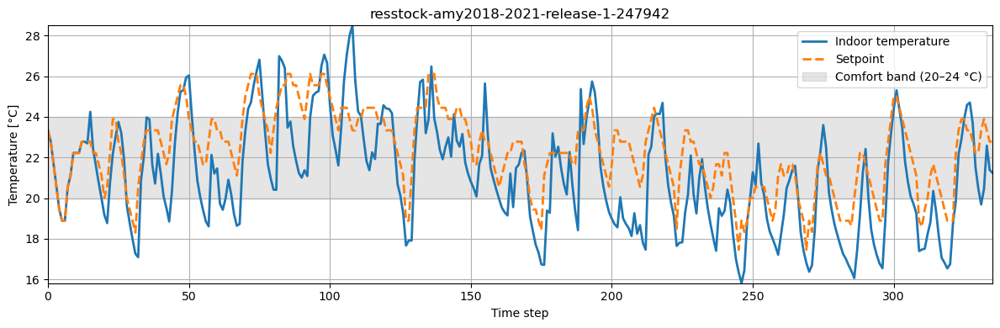

######## BUILDING-LEVEL ########
Building-level KPIs:


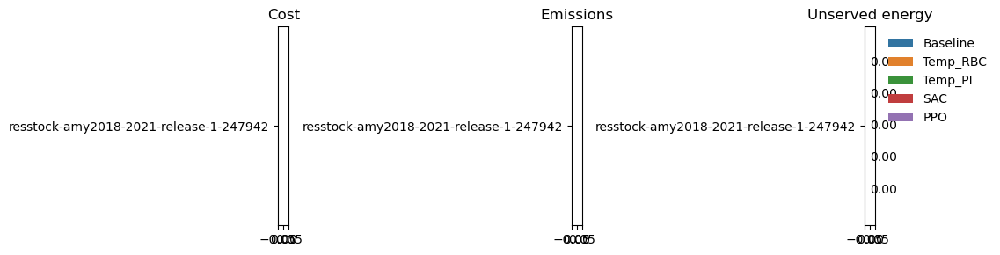

Building-level simulation period load profiles:


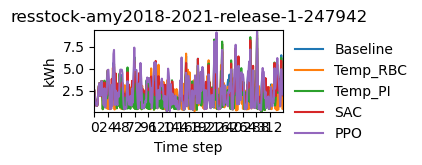

Building-level daily-average load profiles:


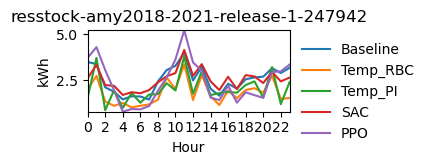

Battery SoC profiles:


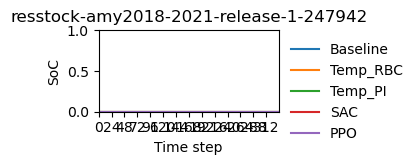

######## DISTRICT-LEVEL ########
District-level KPIs:


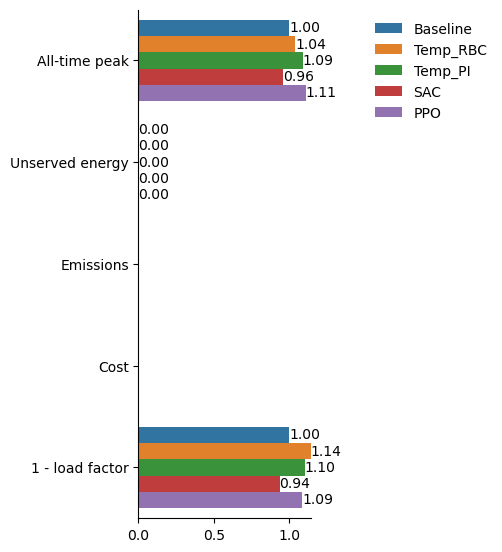

District-level simulation period load profiles:


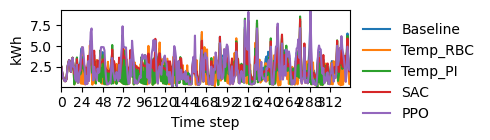

District-level daily-average load profiles:


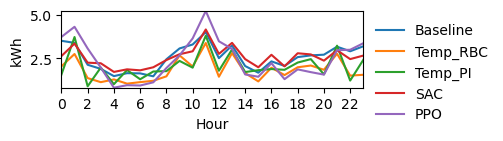

In [76]:
plot_comfort(ppo_env)
plot_simulation_summary({
    'Baseline': baseline_temp,
    'Temp_RBC': env_temp,
    'Temp_PI': env_pi,
    'SAC': sac_env,
    "PPO": ppo_env
})


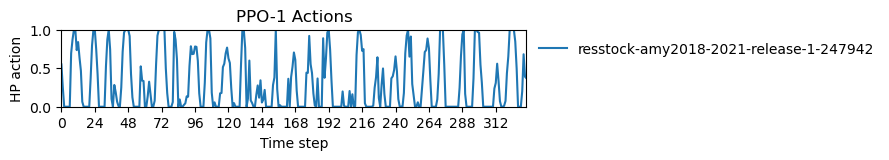

In [77]:
fig = plot_actions(ppo_actions_list, BUILDINGS, 'PPO-1 Actions')
plt.show()

# MPC

In [72]:
model_type = 'continuous' # either 'discrete' or 'continuous'
model = do_mpc.model.Model(model_type)

In [ ]:
import copy
import pickle
import numpy as np
from typing import Callable, Optional, Tuple, List, Any

class BlackBoxMPCController:
    """
    Black-box MPC controller for CityLearn using random shooting.

    - Uses a CLONED CityLearn env to roll out predictions (so LSTM dynamics are used).
    - Minimizes energy + asymmetric comfort slack penalties:
        cost = sum_k [ lambda_u*u^2 + w_cold*s_cold^a + w_hot*s_hot^b ]
    - Comfort bounds are centered around setpoint with comfort_band (from building if available).
        T_heat = T_sp - band
        T_cool = T_sp + band
        constraint: T_heat - s_hot <= T_in <= T_cool + s_cold , s_* >= 0

    Optional occupant override hook:
        delta_band_eff = band + p_override(obs)*override_mag(obs)
      (expected-value version, deterministic)
    """

    def __init__(
        self,
        env,
        horizon: int = 24,
        n_samples: int = 256,
        u_min: float = 0.0,
        u_max: float = 1.0,
        lambda_u: float = 1.0,
        w_cold: float = 1.0,
        w_hot: float = 1.0,
        a: float = 2.0,
        b: float = 2.0,
        seed: int = 0,
        # Optional: occupant model hooks (expected override)
        p_override_fn: Optional[Callable[[List[float], int], float]] = None,
        override_mag_fn: Optional[Callable[[List[float], int], float]] = None,
        # Optional: add action smoothness penalty
        lambda_du: float = 0.0,
    ):
        self.env = env
        self.horizon = int(horizon)
        self.n_samples = int(n_samples)
        self.u_min = float(u_min)
        self.u_max = float(u_max)
        self.lambda_u = float(lambda_u)
        self.w_cold = float(w_cold)
        self.w_hot = float(w_hot)
        self.a = float(a)
        self.b = float(b)
        self.lambda_du = float(lambda_du)

        self.rng = np.random.default_rng(seed)
        self.p_override_fn = p_override_fn
        self.override_mag_fn = override_mag_fn

        # Precompute indices for observations we need
        # Works for central_agent=True: observations is List[List[float]] with one per building
        self._idx_cache = []
        for b_idx, names in enumerate(self.env.observation_names):
            self._idx_cache.append({
                "T_in": self._find_idx(names, "indoor_dry_bulb_temperature"),
                # either setpoint can be used; in your dataset they’re same anyway
                "T_hsp": self._find_idx(names, "indoor_dry_bulb_temperature_heating_set_point"),
                "T_csp": self._find_idx(names, "indoor_dry_bulb_temperature_cooling_set_point"),
            })

        # Track last action for du penalty
        self._u_prev = None

    @staticmethod
    def _find_idx(names: List[str], key: str) -> Optional[int]:
        try:
            return names.index(key)
        except ValueError:
            return None

    def _extract(self, obs_b: List[float], b_idx: int) -> Tuple[float, float]:
        """
        Extract (T_in, T_sp) from ONE building's observation list.
        Falls back if setpoints are missing.
        """
        idxs = self._idx_cache[b_idx]
        T_in = obs_b[idxs["T_in"]] if idxs["T_in"] is not None else None

        # Prefer heating setpoint; fallback to cooling; fallback to 21C
        if idxs["T_hsp"] is not None:
            T_sp = obs_b[idxs["T_hsp"]]
        elif idxs["T_csp"] is not None:
            T_sp = obs_b[idxs["T_csp"]]
        else:
            T_sp = 21.0

        if T_in is None:
            raise RuntimeError("indoor_dry_bulb_temperature not found in observations.")

        return float(T_in), float(T_sp)

    def _comfort_band_eff(self, obs_b: List[float], b_idx: int, band_base: float) -> float:
        """
        Expected comfort band expansion using occupant override model:
            band_eff = band_base + p_override * override_mag
        If no model, returns band_base.
        """
        if self.p_override_fn is None or self.override_mag_fn is None:
            return band_base

        p = float(np.clip(self.p_override_fn(obs_b, b_idx), 0.0, 1.0))
        mag = float(max(self.override_mag_fn(obs_b, b_idx), 0.0))
        return band_base + p * mag

    @staticmethod
    def _clone_env(env):
        """
        Best-effort env clone for black-box rollouts.
        Tries deepcopy first; falls back to pickle.
        """
        try:
            return copy.deepcopy(env)
        except Exception:
            try:
                return pickle.loads(pickle.dumps(env))
            except Exception as e:
                raise RuntimeError(
                    "Env could not be cloned via deepcopy or pickle. "
                    "Black-box MPC via rollout needs a clonable env. "
                    f"Original error: {e}"
                )

    def _slacks(self, T_in: float, T_sp: float, band: float) -> Tuple[float, float]:
        """
        Compute slacks for comfort band:
            lower = T_sp - band
            upper = T_sp + band

        If too cold: T_in < lower => s_cold = lower - T_in
        If too hot : T_in > upper => s_hot  = T_in - upper
        """
        T_sp_eff = T_sp - 1.0
        lower = T_sp_eff - band
        upper = T_sp_eff + band

        s_cold = max(0.0, lower - T_in)
        s_hot  = max(0.0, T_in - upper)
        return s_cold, s_hot

    def _stage_cost(self, u_vec: np.ndarray, s_cold: np.ndarray, s_hot: np.ndarray, du_vec: Optional[np.ndarray] = None) -> float:
        """
        Sum cost across buildings for one stage.
        """
        cost = 0.0
        if self.lambda_u > 0.0:
            cost += self.lambda_u * float(np.sum(u_vec**2))
        cost += self.w_cold * float(np.sum(s_cold**self.a))
        cost += self.w_hot  * float(np.sum(s_hot**self.b))
        if self.lambda_du > 0.0 and du_vec is not None:
            cost += self.lambda_du * float(np.sum(du_vec**2))
        return cost

    def _sample_action_sequences(self, n_buildings: int) -> np.ndarray:
        """
        Returns U of shape (n_samples, horizon, n_buildings) in [u_min, u_ma for b in range(n_buildings):
                    T_in, T_sp = self._extract(obs_roll[b], b)

                    # base band from building if available, else default 2.0
                    try:
                        band_base = float(env_roll.unwrapped.buildings[b].comfort_band)
                    except Exception:
                        band_base = 2.0

                    band_eff = self._comfort_band_eff(obs_roll[b], b, band_base)
                    sc, sh = self._slacks(T_in, T_sp, band_eff)
                    s_cold[b] = sc
                    s_hot[b] = sh

                du = (u_vec - u_prev) if self.lambda_du > 0.0 else None
                total_cost += self._stage_cost(u_vec, s_cold, s_hot, du_vec=du)
                u_prev = u_vec

            if total_cost < best_cost:
                best_cost = total_cost
                best_u0 = U[s, 0, :].copy()

        # Apply first action (receding horizon)
        if best_u0 is None:
            best_u0 = np.clip(self._u_prev, self.u_min, self.u_max)

        self._u_prev = best_u0.copy()
        return [[float(best_u0[b])] for b in range(n_buildings)]x].
        """
        U = self.rng.uniform(self.u_min, self.u_max, size=(self.n_samples, self.horizon, n_buildings))
        return U

    def predict(self, observations: List[List[float]], deterministic: bool = True) -> List[List[float]]:
        """
        CityLearn agent API: returns List[List[float]] actions (per building).
        Assumes HVAC-only action space per building (e.g., heating_device).
        """
        n_buildings = len(observations)
        U = self._sample_action_sequences(n_buildings)

        # previous action (for du penalty)
        if self._u_prev is None:
            self._u_prev = np.zeros(n_buildings, dtype=float)

        best_cost = np.inf
        best_u0 = None

        for s in range(self.n_samples):
            env_roll = self._clone_env(self.env)

            # roll out this candidate sequence
            total_cost = 0.0
            u_prev = self._u_prev.copy()

            # IMPORTANT: the cloned env is already at current time_step if your main env was stepped.
            # We just simulate forward h steps in the clone.
            terminated = False
            truncated = False

            obs_roll = observations  # we start from the current obs
            for k in range(self.horizon):
                if terminated or truncated:
                    break

                u_vec = U[s, k, :]

                # Build CityLearn action format: list of [u] per building
                actions = [[float(u_vec[b])] for b in range(n_buildings)]

                # Step rollout env
                obs_roll, _, terminated, truncated, _ = env_roll.step(actions)

                # Compute comfort slacks after the transition (uses next obs)
                s_cold = np.zeros(n_buildings, dtype=float)
                s_hot  = np.zeros(n_buildings, dtype=float)

                for b in range(n_buildings):
                    T_in, T_sp = self._extract(obs_roll[b], b)

                    # base band from building if available, else default 2.0
                    try:
                        band_base = float(env_roll.unwrapped.buildings[b].comfort_band)
                    except Exception:
                        band_base = 2.0

                    band_eff = self._comfort_band_eff(obs_roll[b], b, band_base)
                    sc, sh = self._slacks(T_in, T_sp, band_eff)
                    s_cold[b] = sc
                    s_hot[b] = sh

                du = (u_vec - u_prev) if self.lambda_du > 0.0 else None
                total_cost += self._stage_cost(u_vec, s_cold, s_hot, du_vec=du)
                u_prev = u_vec

            if total_cost < best_cost:
                best_cost = total_cost
                best_u0 = U[s, 0, :].copy()

        # Apply first action (receding horizon)
        if best_u0 is None:
            best_u0 = np.clip(self._u_prev, self.u_min, self.u_max)

        self._u_prev = best_u0.copy()
        return [[float(best_u0[b])] for b in range(n_buildings)]


In [63]:
mpc_env = make_env(
    # same env factory you already have
    # active_actions=['heating_device']  # ensure this in make_env
)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [66]:
# mpc_agent = BlackBoxMPCController(
#     env=mpc_env,
#     horizon=24,          # 24 hours
#     n_samples=256,       # start here; increase if slow/poor
#     lambda_u=0.01,       # energy-ish penalty (optional)
#     w_cold=10.0,
#     w_hot=5.0,
#     a=2.0,
#     b=2.0,
#     lambda_du=0.1,       # smoothness (optional, helps a lot)
#     seed=RANDOM_SEED
# )

mpc_agent = BlackBoxMPCController(
    env=mpc_env,
    horizon=24,
    n_samples=32,
    lambda_u=0.01,
    w_cold=1.0,
    w_hot=15.0,
    a=2.0,
    b=2.0,
    lambda_du=0.05,
    seed=RANDOM_SEED
)



In [67]:
mpc_env = run_env(mpc_env, mpc_agent)
plot_comfort(mpc_env)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

KeyboardInterrupt: 

######## BUILDING-LEVEL ########
Building-level KPIs:


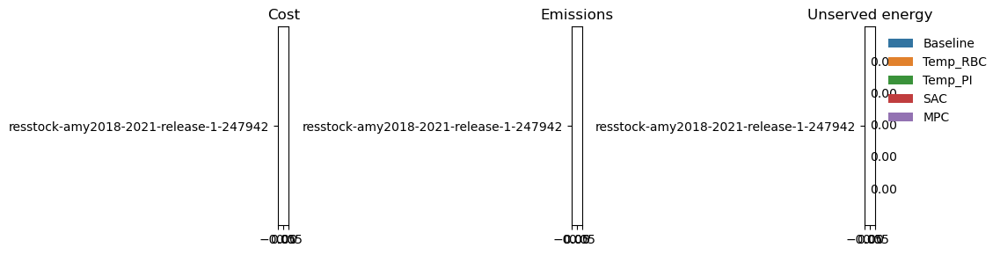

Building-level simulation period load profiles:


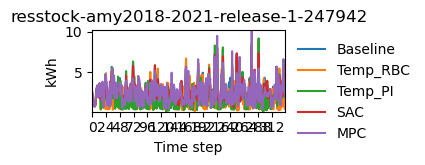

Building-level daily-average load profiles:


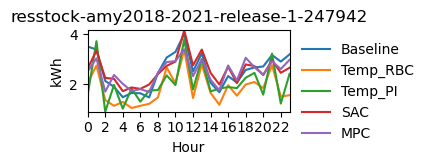

Battery SoC profiles:


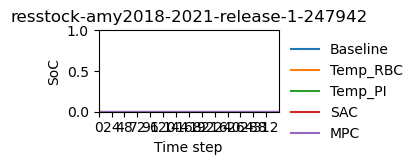

######## DISTRICT-LEVEL ########
District-level KPIs:


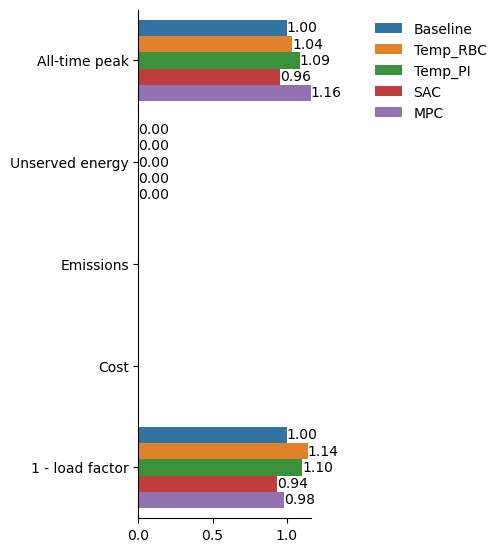

District-level simulation period load profiles:


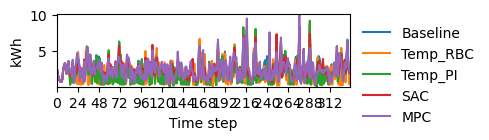

District-level daily-average load profiles:


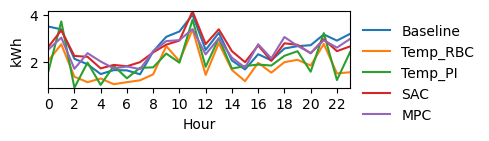

In [93]:
plot_simulation_summary({
    'Baseline': baseline_temp,
    'Temp_RBC': env_temp,
    'Temp_PI': env_pi,
    'SAC': sac_env,
    'MPC': mpc_env
})

In [70]:
import copy
import pickle
import numpy as np
from typing import Callable, Optional, Tuple, List


class BlackBoxMPCControllerCEM:
    """
    Black-box MPC for CityLearn using Cross-Entropy Method (CEM).

    - Uses cloned CityLearn env rollouts (so LSTM dynamics are used).
    - Solves a receding-horizon MPC problem by optimizing action sequences with CEM.
    - Comfort handled via soft constraints (slacks) with asymmetric penalties.

    Cost per step (sum over buildings):
        lambda_u * u^2 + w_cold * s_cold^a + w_hot * s_hot^b + lambda_du * (u - u_prev)^2
    """

    def __init__(
        self,
        env,
        horizon: int = 12,
        # CEM settings
        population: int = 64,          # samples per iteration
        cem_iters: int = 3,            # iterations of CEM updates
        elite_frac: float = 0.2,       # fraction of best samples kept
        # action bounds
        u_min: float = 0.0,
        u_max: float = 1.0,
        # cost weights
        lambda_u: float = 0.0,
        w_cold: float = 1.0,
        w_hot: float = 1.0,
        a: float = 2.0,
        b: float = 2.0,
        lambda_du: float = 0.0,
        # smoothing of CEM distribution updates
        alpha: float = 0.25,           # 0..1, higher = faster updates
        init_sigma: float = 0.35,      # initial std for actions
        min_sigma: float = 0.05,       # floor for std so it doesn't collapse too early
        # Optional occupant hooks
        p_override_fn: Optional[Callable[[List[float], int], float]] = None,
        override_mag_fn: Optional[Callable[[List[float], int], float]] = None,
        seed: int = 0,
        # Optional: evaluate less frequently (e.g. every 2 steps)
        control_interval: int = 1,
    ):
        self.env = env
        self.horizon = int(horizon)

        self.population = int(population)
        self.cem_iters = int(cem_iters)
        self.elite_frac = float(elite_frac)
        self.elite_count = max(2, int(self.population * self.elite_frac))

        self.u_min = float(u_min)
        self.u_max = float(u_max)

        self.lambda_u = float(lambda_u)
        self.w_cold = float(w_cold)
        self.w_hot = float(w_hot)
        self.a = float(a)
        self.b = float(b)
        self.lambda_du = float(lambda_du)

        self.alpha = float(alpha)
        self.init_sigma = float(init_sigma)
        self.min_sigma = float(min_sigma)

        self.p_override_fn = p_override_fn
        self.override_mag_fn = override_mag_fn

        self.rng = np.random.default_rng(seed)

        self.control_interval = max(1, int(control_interval))
        self._t = 0
        self._last_action = None

        # Cache observation indices per building
        self._idx_cache = []
        for b_idx, names in enumerate(self.env.observation_names):
            self._idx_cache.append({
                "T_in": self._find_idx(names, "indoor_dry_bulb_temperature"),
                "T_hsp": self._find_idx(names, "indoor_dry_bulb_temperature_heating_set_point"),
                "T_csp": self._find_idx(names, "indoor_dry_bulb_temperature_cooling_set_point"),
            })

        # Track previous applied action
        self._u_prev = None

        # Warm-start: store previous optimized plan (shape horizon x n_buildings)
        self._U_prev_plan = None

    @staticmethod
    def _find_idx(names: List[str], key: str) -> Optional[int]:
        try:
            return names.index(key)
        except ValueError:
            return None

    def _extract(self, obs_b: List[float], b_idx: int) -> Tuple[float, float]:
        idxs = self._idx_cache[b_idx]
        if idxs["T_in"] is None:
            raise RuntimeError("indoor_dry_bulb_temperature not found in observations.")
        T_in = float(obs_b[idxs["T_in"]])

        # Prefer heating setpoint; fallback to cooling; else default
        if idxs["T_hsp"] is not None:
            T_sp = float(obs_b[idxs["T_hsp"]])
        elif idxs["T_csp"] is not None:
            T_sp = float(obs_b[idxs["T_csp"]])
        else:
            T_sp = 21.0

        return T_in, T_sp

    def _comfort_band_eff(self, obs_b: List[float], b_idx: int, band_base: float) -> float:
        if self.p_override_fn is None or self.override_mag_fn is None:
            return band_base
        p = float(np.clip(self.p_override_fn(obs_b, b_idx), 0.0, 1.0))
        mag = float(max(self.override_mag_fn(obs_b, b_idx), 0.0))
        return band_base + p * mag

    @staticmethod
    def _clone_env(env):
        try:
            return copy.deepcopy(env)
        except Exception:
            try:
                return pickle.loads(pickle.dumps(env))
            except Exception as e:
                raise RuntimeError(
                    "Env could not be cloned via deepcopy or pickle. "
                    f"Original error: {e}"
                )

    @staticmethod
    def _slacks(T_in: float, T_sp: float, band: float) -> Tuple[float, float]:
        lower = T_sp - band
        upper = T_sp + band
        s_cold = max(0.0, lower - T_in)
        s_hot = max(0.0, T_in - upper)
        return s_cold, s_hot

    def _stage_cost(
        self,
        u_vec: np.ndarray,
        s_cold: np.ndarray,
        s_hot: np.ndarray,
        du_vec: Optional[np.ndarray] = None
    ) -> float:
        cost = 0.0
        if self.lambda_u > 0.0:
            cost += self.lambda_u * float(np.sum(u_vec ** 2))
        cost += self.w_cold * float(np.sum(s_cold ** self.a))
        cost += self.w_hot * float(np.sum(s_hot ** self.b))
        if self.lambda_du > 0.0 and du_vec is not None:
            cost += self.lambda_du * float(np.sum(du_vec ** 2))
        return cost

    def _evaluate_sequence(
        self,
        observations: List[List[float]],
        U_seq: np.ndarray,
        u_prev: np.ndarray,
    ) -> float:
        """
        Evaluate one candidate action sequence:
            U_seq shape: (horizon, n_buildings)
        """
        n_buildings = len(observations)
        env_roll = self._clone_env(self.env)

        total_cost = 0.0
        obs_roll = observations
        terminated = False
        truncated = False

        u_last = u_prev.copy()

        for k in range(self.horizon):
            if terminated or truncated:
                break

            u_vec = U_seq[k, :]
            actions = [[float(u_vec[b])] for b in range(n_buildings)]
            obs_roll, _, terminated, truncated, _ = env_roll.step(actions)

            s_cold = np.zeros(n_buildings, dtype=float)
            s_hot = np.zeros(n_buildings, dtype=float)

            for b in range(n_buildings):
                T_in, T_sp = self._extract(obs_roll[b], b)
                try:
                    band_base = float(env_roll.unwrapped.buildings[b].comfort_band)
                except Exception:
                    band_base = 2.0

                band_eff = self._comfort_band_eff(obs_roll[b], b, band_base)
                sc, sh = self._slacks(T_in, T_sp, band_eff)
                s_cold[b] = sc
                s_hot[b] = sh

            du = (u_vec - u_last) if self.lambda_du > 0.0 else None
            total_cost += self._stage_cost(u_vec, s_cold, s_hot, du_vec=du)
            u_last = u_vec

        return float(total_cost)

    def _init_cem_params(self, n_buildings: int) -> Tuple[np.ndarray, np.ndarray]:
        """
        Initialize mean and std for CEM distribution over sequences.
        Shapes: (horizon, n_buildings)
        """
        if self._U_prev_plan is not None and self._U_prev_plan.shape == (self.horizon, n_buildings):
            mu = self._U_prev_plan.copy()
        else:
            # Start from previous action repeated, or mid-range
            if self._u_prev is None:
                base = np.full(n_buildings, (self.u_min + self.u_max) / 2.0, dtype=float)
            else:
                base = self._u_prev.copy()
            mu = np.tile(base[None, :], (self.horizon, 1))

        sigma = np.full((self.horizon, n_buildings), self.init_sigma, dtype=float)
        return mu, sigma

    def _sample_sequences(self, mu: np.ndarray, sigma: np.ndarray) -> np.ndarray:
        """
        Sample action sequences from factorized Gaussian N(mu, sigma^2),
        clamp to [u_min, u_max].
        Returns shape: (population, horizon, n_buildings)
        """
        eps = self.rng.normal(size=(self.population, *mu.shape))
        U = mu[None, :, :] + eps * sigma[None, :, :]
        U = np.clip(U, self.u_min, self.u_max)
        return U

    def _shift_plan(self, plan: np.ndarray) -> np.ndarray:
        """
        Receding-horizon shift: drop first action, append last action.
        """
        if plan.shape[0] != self.horizon:
            return plan
        tail = plan[-1:, :]
        return np.vstack([plan[1:, :], tail])

    def predict(self, observations: List[List[float]], deterministic: bool = True) -> List[List[float]]:
        """
        CityLearn agent API: returns List[List[float]] actions (per building).
        Assumes HVAC-only action per building (e.g., heating_device).
        """

        n_buildings = len(observations)

        # Optionally compute only every control_interval steps
        if self._last_action is not None and (self._t % self.control_interval != 0):
            self._t += 1
            return [[float(self._last_action[b])] for b in range(n_buildings)]

        # initialize previous action
        if self._u_prev is None:
            self._u_prev = np.zeros(n_buildings, dtype=float)

        # Initialize CEM distribution
        mu, sigma = self._init_cem_params(n_buildings)

        best_U = None
        best_cost = np.inf

        for _ in range(self.cem_iters):
            # Sample
            U_pop = self._sample_sequences(mu, sigma)  # (pop, horizon, n_buildings)

            # Evaluate
            costs = np.empty(self.population, dtype=float)
            for i in range(self.population):
                costs[i] = self._evaluate_sequence(observations, U_pop[i], self._u_prev)

            # Track global best
            i_best = int(np.argmin(costs))
            if costs[i_best] < best_cost:
                best_cost = float(costs[i_best])
                best_U = U_pop[i_best].copy()

            # Elite selection
            elite_idx = np.argsort(costs)[:self.elite_count]
            elites = U_pop[elite_idx]  # (elite, horizon, n_buildings)

            # Update distribution (mean/std), with smoothing
            mu_new = np.mean(elites, axis=0)
            sigma_new = np.std(elites, axis=0)

            sigma_new = np.maximum(sigma_new, self.min_sigma)

            mu = (1.0 - self.alpha) * mu + self.alpha * mu_new
            sigma = (1.0 - self.alpha) * sigma + self.alpha * sigma_new

        if best_U is None:
            # Fallback: hold previous action
            u0 = np.clip(self._u_prev, self.u_min, self.u_max)
            best_U = np.tile(u0[None, :], (self.horizon, 1))
        else:
            u0 = best_U[0, :]

        # Apply first action (receding horizon)
        self._u_prev = u0.copy()
        self._last_action = u0.copy()

        # Warm-start plan for next time step by shifting best plan
        self._U_prev_plan = self._shift_plan(best_U)

        self._t += 1
        return [[float(u0[b])] for b in range(n_buildings)]


In [71]:
mpc_env = make_env(active_actions=['heating_device'])
mpc_agent = BlackBoxMPCControllerCEM(
    env=mpc_env,
    horizon=12,
    population=64,
    cem_iters=3,
    elite_frac=0.2,
    lambda_du=0.05,  # smooth
    w_cold=10.0,
    w_hot=5.0,
)
env_mpc = run_env(mpc_env, mpc_agent)
plot_comfort(env_mpc)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

KeyboardInterrupt: 

In [48]:
import gymnasium as gym
import numpy as np

class OccupantThermostatWrapper(gym.Wrapper):
    """
    LoD3 wrapper:
    - Occupant observes T_in
    - Probabilistically overrides thermostat setpoint
    - Modified setpoint is written into CityLearn energy_simulation
    """

    def __init__(self, env, occupants):
        """
        Parameters
        ----------
        env : CityLearnEnv (gymnasium-compatible)
        occupants : list[Occupant]
            One occupant model per building
        """
        super().__init__(env)
        self.occupants = occupants

        assert len(self.occupants) == len(self.env.unwrapped.buildings), \
            "Need exactly one occupant per building"

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)

        # Reset occupants as well
        for occ in self.occupants:
            occ.reset()

        return obs, info

    def step(self, actions):
        # ---- BEFORE stepping env: occupant may override thermostat ----
        buildings = self.env.unwrapped.buildings
        observations = self.env.unwrapped.observations()

        for b_idx, building in enumerate(buildings):
            occ = self.occupants[b_idx]
            t = building.time_step

            # Indoor temperature at current timestep
            T_in = building.energy_simulation.indoor_dry_bulb_temperature[t]

            # Full observation vector for this building
            obs_b = observations[b_idx]

            # Occupant decides setpoint delta
            delta_T = occ.predict((T_in, obs_b))

            if delta_T != 0.0:
                building.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[t] += delta_T
                building.energy_simulation.indoor_dry_bulb_temperature_cooling_set_point[t] += delta_T

        # ---- Step environment normally ----
        return self.env.step(actions)


In [53]:
# Base CityLearn env (LoD2)
base_env = make_env(
    reward_function=ComfortReward,   # optional
    active_actions=["heating_device"]
)
from citylearn.occupant import LogisticRegressionOccupant


# Build occupants (Kathryn-style)
occupants = [
    LogisticRegressionOccupant(
        setpoint_increase_model_filepath=INC_MODEL_PATH,
        setpoint_decrease_model_filepath=DEC_MODEL_PATH,
        delta_output_map=DELTA_MAP,
        parameters=OCC_PARAMS,
    )
    for _ in base_env.unwrapped.buildings
]

# Wrap for LoD3
lod3_env = OccupantThermostatWrapper(base_env, occupants)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

NameError: name 'INC_MODEL_PATH' is not defined

# MPC right way

In [51]:
env = make_env()
from citylearn.dynamics import LSTMDynamics

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [128]:
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from citylearn.dynamics import LSTMDynamics


# =========================
# 1) DATA COLLECTION
# =========================
def collect_training_data(env, n_steps=6000, seed=0):
    """
    Roll out the real env once (offline) to collect training data for the thermal LSTM.
    This is the ONLY place we call env.step() for training data generation.
    """
    rng = np.random.default_rng(seed)
    obs, _ = env.reset(seed=seed)
    b = env.unwrapped.buildings[0]

    for _ in range(n_steps):
        u = float(rng.uniform(0.0, 1.0))
        obs, _, terminated, truncated, _ = env.step([[u]])
        if terminated or truncated:
            break

    T = b.time_step + 1

    data = {
        "Tin": np.asarray(b.energy_simulation.indoor_dry_bulb_temperature[:T], dtype=np.float32),
        "Tout": np.asarray(b.weather.outdoor_dry_bulb_temperature[:T], dtype=np.float32),
        "SolDir": np.asarray(b.weather.direct_solar_irradiance[:T], dtype=np.float32),
        "SolDif": np.asarray(b.weather.diffuse_solar_irradiance[:T], dtype=np.float32),
        "HeatDem": np.asarray(b.energy_simulation.heating_demand[:T], dtype=np.float32),
        # setpoints are useful to compute slacks during MPC (not needed for LSTM input)
        # We won't train the LSTM on setpoint directly unless you want to.
        "TspH": np.asarray(getattr(b.energy_simulation, "indoor_dry_bulb_temperature_heating_set_point")[:T], dtype=np.float32)
                if hasattr(b.energy_simulation, "indoor_dry_bulb_temperature_heating_set_point") else None,
        "TspC": np.asarray(getattr(b.energy_simulation, "indoor_dry_bulb_temperature_cooling_set_point")[:T], dtype=np.float32)
                if hasattr(b.energy_simulation, "indoor_dry_bulb_temperature_cooling_set_point") else None,
    }
    return data


# =========================
# 2) CITYLEARN-STYLE DATASET
# =========================
INPUT_NAMES = [
    "outdoor_dry_bulb_temperature",
    "direct_solar_irradiance",
    "diffuse_solar_irradiance",
    "heating_demand",
    "indoor_dry_bulb_temperature",
]
KEYMAP = {
    "outdoor_dry_bulb_temperature": "Tout",
    "direct_solar_irradiance": "SolDir",
    "diffuse_solar_irradiance": "SolDif",
    "heating_demand": "HeatDem",
    "indoor_dry_bulb_temperature": "Tin",
}

class ThermalDataset(Dataset):
    """
    CityLearn-aligned lookback:
      - indoor temp window: [t-lookback ... t-1]
      - other inputs window: [t-lookback+1 ... t]
    target: indoor temp at t (normalized)
    """
    def __init__(self, data, lookback, mins, maxs):
        self.data = data
        self.lookback = int(lookback)
        self.mins = np.asarray(mins, dtype=np.float32)
        self.maxs = np.asarray(maxs, dtype=np.float32)
        self.T = len(data["Tin"])

    def __len__(self):
        return self.T - self.lookback

    def _norm(self, x, i):
        return (x - self.mins[i]) / (self.maxs[i] - self.mins[i] + 1e-8)

    def __getitem__(self, idx):
        t = idx + self.lookback
        X = np.zeros((self.lookback, len(INPUT_NAMES)), dtype=np.float32)

        for i, name in enumerate(INPUT_NAMES):
            arr = self.data[KEYMAP[name]]
            if name == "indoor_dry_bulb_temperature":
                window = arr[t - self.lookback : t]             # ends at t-1
            else:
                window = arr[t - self.lookback + 1 : t + 1]     # ends at t
            X[:, i] = self._norm(window, i)

        iTin = INPUT_NAMES.index("indoor_dry_bulb_temperature")
        y = self._norm(self.data["Tin"][t], iTin)

        return torch.tensor(X), torch.tensor([y], dtype=torch.float32)


def train_lstm(env, lookback=6, epochs=30, batch_size=64, seed=0):
    data = collect_training_data(env, n_steps=12000, seed=seed)

    mins, maxs = [], []
    for name in INPUT_NAMES:
        arr = data[KEYMAP[name]]
        mins.append(float(arr.min()))
        maxs.append(float(arr.max()))
    mins = np.array(mins, dtype=np.float32)
    maxs = np.array(maxs, dtype=np.float32)

    ds = ThermalDataset(data, lookback=lookback, mins=mins, maxs=maxs)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=True)

    dyn = LSTMDynamics(
        filepath="thermal_lstm_heating.pth",
        input_observation_names=INPUT_NAMES,
        input_normalization_minimum=mins.tolist(),
        input_normalization_maximum=maxs.tolist(),
        hidden_size=32,
        num_layers=1,
        lookback=int(lookback),
        dropout=0.0,
    )

    optimizer = optim.Adam(dyn.parameters(), lr=1e-3)
    loss_fn = nn.MSELoss()

    for e in range(int(epochs)):
        total = 0.0
        for X, y in dl:
            h = dyn.init_hidden(X.shape[0])
            yhat, _ = dyn(X.float(), h)
            loss = loss_fn(yhat, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total += loss.item() * X.shape[0]
        print(f"Epoch {e:02d} | MSE {total/len(ds):.6f}")

    torch.save(dyn.state_dict(), dyn.filepath)
    return dyn




In [52]:
# =========================
# 3) MPC (RANDOM SHOOTING) USING TRAINED LSTM
#    - NO ENV CLONING
#    - PRESERVES YOUR ORIGINAL SLACK LOGIC
# =========================
class LSTMBlackBoxMPC_NoClone_1B:
    def __init__(
        self,
        env,
        dynamics: LSTMDynamics,
        horizon: int = 24,
        n_samples: int = 256,
        u_min: float = 0.0,
        u_max: float = 1.0,
        lambda_u: float = 1.0,
        w_cold: float = 1.0,
        w_hot: float = 1.0,
        a: float = 2.0,
        b: float = 2.0,
        lambda_du: float = 0.0,
        seed: int = 0,
    ):
        self.env = env
        self.bld = env.unwrapped.buildings[0]
        self.dyn = dynamics

        self.T_max = len(self.bld.energy_simulation.hvac_mode)


        self.horizon = int(horizon)
        self.n_samples = int(n_samples)

        self.u_min = float(u_min)
        self.u_max = float(u_max)

        self.lambda_u = float(lambda_u)
        self.w_cold = float(w_cold)
        self.w_hot = float(w_hot)
        self.a = float(a)
        self.b = float(b)
        self.lambda_du = float(lambda_du)

        self.rng = np.random.default_rng(seed)
        self._u_prev = None

        self.names = self.dyn.input_observation_names
        self.mins = np.array(self.dyn.input_normalization_minimum, dtype=np.float32)
        self.maxs = np.array(self.dyn.input_normalization_maximum, dtype=np.float32)
        self.lookback = int(self.dyn.lookback)

        # self.iTin = self.names.index("indoor_dry_bulb_temperature")
        # self.iHeatDem = self.names.index("heating_demand")
        # self.iTout = self.names.index("outdoor_dry_bulb_temperature")

        # --- CityLearn v2 LSTM feature names ---
        self.iTin = self.names.index("average_indoor_air_temperature")
        self.iHeatDem = self.names.index("heating_load")
        self.iTout = self.names.index("outdoor_air_temperature")



        # Initialize dyn buffers if not set
        self._ensure_dyn_buffers_initialized()

    def _norm(self, x, i):
        mn, mx = float(self.mins[i]), float(self.maxs[i])
        return (float(x) - mn) / (mx - mn + 1e-12)

    def _denorm_Tin(self, tin_norm):
        mn, mx = float(self.mins[self.iTin]), float(self.maxs[self.iTin])
        return float(tin_norm) * (mx - mn) + mn

    def _ensure_dyn_buffers_initialized(self):
        """
        Ensure dyn._model_input and dyn._hidden_state exist so we can copy them during MPC rollouts.
        """
        if getattr(self.dyn, "_hidden_state", None) is None:
            self.dyn._hidden_state = self.dyn.init_hidden(batch_size=1)

        if getattr(self.dyn, "_model_input", None) is None:
            self._bootstrap_model_input_from_building()
            return

        # If present but uninitialized (CityLearn sometimes uses [None, ...])
        if len(self.dyn._model_input) == 0 or (self.dyn._model_input[0][0] is None):
            self._bootstrap_model_input_from_building()

    def _bootstrap_model_input_from_building(self):
        """
        Build a normalized model_input buffer of length lookback+1 for each input name.
        Uses current building arrays near current time_step.
        """
        t0 = int(self.bld.time_step)
        self.dyn._model_input = []

        for i, name in enumerate(self.names):
            buf = []
            for k in range(self.lookback + 1):
                t = max(0, t0 - (self.lookback - k))

                if name == "indoor_dry_bulb_temperature":
                    raw = self.bld.energy_simulation.indoor_dry_bulb_temperature[t]
                elif name == "outdoor_dry_bulb_temperature":
                    raw = self.bld.weather.outdoor_dry_bulb_temperature[t]
                elif name == "direct_solar_irradiance":
                    raw = self.bld.weather.direct_solar_irradiance[t]
                elif name == "diffuse_solar_irradiance":
                    raw = self.bld.weather.diffuse_solar_irradiance[t]
                elif name == "heating_demand":
                    raw = self.bld.energy_simulation.heating_demand[t]
                else:
                    # if you add more inputs later, map them here
                    raw = 0.0

                buf.append(self._norm(raw, i))

            self.dyn._model_input.append(buf)

        self.dyn._hidden_state = self.dyn.init_hidden(batch_size=1)

    def _extract_Tsp_from_obs(self, obs_b):
        """
        Keep your original behavior: prefer heating setpoint; fallback cooling; fallback 21.
        Uses observation vector (like your idx-cache method).
        """
        names = self.env.observation_names[0]

        def find_idx(key):
            try:
                return names.index(key)
            except ValueError:
                return None

        i_hsp = find_idx("indoor_dry_bulb_temperature_heating_set_point")
        i_csp = find_idx("indoor_dry_bulb_temperature_cooling_set_point")

        if i_hsp is not None:
            return float(obs_b[i_hsp])
        if i_csp is not None:
            return float(obs_b[i_csp])
        return 21.0

    def _comfort_band_base(self):
        try:
            return float(self.bld.comfort_band)
        except Exception:
            return 2.0

    def _slacks(self, T_in: float, T_sp: float, band: float):
        """
        EXACTLY your original slack logic, including T_sp_eff = T_sp - 1.0.
        """
        # T_sp_eff = T_sp - 1.0
        T_sp_eff = T_sp
        lower = T_sp_eff - band
        upper = T_sp_eff + band
        s_cold = max(0.0, lower - T_in)
        s_hot = max(0.0, T_in - upper)
        return s_cold, s_hot

    def _stage_cost(self, u: float, s_cold: float, s_hot: float, du: float | None):
        cost = 0.0
        if self.lambda_u > 0.0:
            cost += self.lambda_u * (u * u)
        cost += self.w_cold * (s_cold ** self.a)
        cost += self.w_hot * (s_hot ** self.b)
        if self.lambda_du > 0.0 and du is not None:
            cost += self.lambda_du * (du * du)
        return float(cost)

    def _heating_demand_from_u(self, t: int, u: float) -> float:
        """
        Convert action u (0..1) to heating_demand using the building device model
        (consistent with CityLearn’s update_heating_demand intent).
        """
        # Only allow heating when hvac mode indicates heating/auto (CityLearn convention)
        if self.bld.energy_simulation.hvac_mode[t] not in [2, 3]:
            return 0.0

        electric_power = u * self.bld.heating_device.nominal_power

        try:
            # HeatPump-like signature
            return float(self.bld.heating_device.get_max_output_power(
                self.bld.weather.outdoor_dry_bulb_temperature[t],
                heating=True,
                max_electric_power=electric_power
            ))
        except TypeError:
            # non-HeatPump fallback signature
            return float(self.bld.heating_device.get_max_output_power(max_electric_power=electric_power))

    def _sample_action_sequences(self) -> np.ndarray:
        return self.rng.uniform(self.u_min, self.u_max, size=(self.n_samples, self.horizon))

    def _rollout_sequence_cost(self, u_seq: np.ndarray, obs0):
        """
        Roll out temperatures with ONLY the trained LSTM and local copies of:
          - dyn._model_input
          - dyn._hidden_state

        No env cloning. No env.step() inside MPC.
        """
        t0 = int(self.bld.time_step)

        # copy small dynamics state
        model_input = copy.deepcopy(self.dyn._model_input)
        h = (self.dyn._hidden_state[0].detach().clone(), self.dyn._hidden_state[1].detach().clone())

        band = self._comfort_band_base()
        T_sp0 = self._extract_Tsp_from_obs(obs0)

        total_cost = 0.0

        # previous action for du penalty
        u_prev = float(self._u_prev) if self._u_prev is not None else 0.0

        for k in range(self.horizon):
            t = t0 + k
            if t >= self.T_max:
                break  # end of episode, stop rollout

            u = float(np.asarray(u_seq[k]).item())
            


            # convert action -> heating demand
            heat_dem = self._heating_demand_from_u(t, u)

            # update model_input buffers with normalized values at this (virtual) timestep
            for i, name in enumerate(self.names):
                if name == "heating_demand":
                    x = self._norm(heat_dem, i)
                elif name == "outdoor_dry_bulb_temperature":
                    x = self._norm(self.bld.weather.outdoor_dry_bulb_temperature[t], i)
                elif name == "direct_solar_irradiance":
                    x = self._norm(self.bld.weather.direct_solar_irradiance[t], i)
                elif name == "diffuse_solar_irradiance":
                    x = self._norm(self.bld.weather.diffuse_solar_irradiance[t], i)
                elif name == "indoor_dry_bulb_temperature":
                    # placeholder; overwritten after prediction (same approach as CityLearn)
                    x = model_input[i][-1]
                else:
                    x = model_input[i][-1]

                model_input[i] = model_input[i][-self.lookback:] + [float(x)]

            # construct (1, lookback, n_feat) using CityLearn’s shift rule
            X_cols = []
            for i, name in enumerate(self.names):
                if name == "indoor_dry_bulb_temperature":
                    X_cols.append(model_input[i][:-1])   # uses past Tin
                else:
                    X_cols.append(model_input[i][1:])    # uses "current" exogenous
            X = torch.tensor(np.array(X_cols, dtype=np.float32).T)[None, :, :]  # (1, lookback, n_feat)

            # predict Tin (normalized)
            y_norm, h = self.dyn(X.float(), h)
            Tin = self._denorm_Tin(float(y_norm.item()))

            # update indoor temp in buffer at "current time step"
            model_input[self.iTin][-1] = float(y_norm.item())

            # slacks (both cold and hot) EXACTLY as your logic
            s_cold, s_hot = self._slacks(Tin, T_sp0, band)

            du = (u - u_prev) if self.lambda_du > 0.0 else None
            total_cost += self._stage_cost(u, s_cold, s_hot, du)
            u_prev = u

        return float(total_cost)

    def predict(self, observations, deterministic: bool = True):
        """
        CityLearn agent API: return [[u]] for 1 building.
        """
        obs0 = observations[0]

        if self._u_prev is None:
            self._u_prev = 0.0

        U = self._sample_action_sequences()

        best_cost = np.inf
        best_u0 = float(self._u_prev)

        for s in range(self.n_samples):
            c = self._rollout_sequence_cost(U[s], obs0)
            if c < best_cost:
                best_cost = c
                best_u0 = float(np.asarray(U[s, 0]).item())

        # receding horizon
        self._u_prev = best_u0
        return [[float(best_u0)]]
        # return [[0.0, float(best_u0)]]



In [53]:
import torch
import pandas as pd
from pathlib import Path
from citylearn.dynamics import LSTMDynamics

# =========================================================
# Resolve project root (notebook-safe)
# =========================================================
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "simulation").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "simulation" / "data"
LSTM_DIR = DATA_DIR / "lstm_pth"

# =========================================================
# Building
# =========================================================
BUILDING_ID = 247942
MODEL_PATH = LSTM_DIR / "model_pth_VT, Chittenden County_247942.pth"

# =========================================================
# TRUE CityLearn v2 LSTM input order (12 features)
# =========================================================
INPUT_NAMES = [
    "direct_solar_radiation",
    "diffuse_solar_radiation",
    "outdoor_air_temperature",
    "occupant_count",
    "heating_load",
    "sin_month",
    "cos_month",
    "sin_hour",
    "cos_hour",
    "sin_DoW",
    "cos_DoW",
    "average_indoor_air_temperature",
]

# =========================================================
# Load per-building normalization
# =========================================================
min_df = pd.read_csv(DATA_DIR / "min.csv", index_col=0)
max_df = pd.read_csv(DATA_DIR / "max.csv", index_col=0)

min_row = min_df.loc[BUILDING_ID]
max_row = max_df.loc[BUILDING_ID]

min_vals = [min_row[c] for c in INPUT_NAMES]
max_vals = [max_row[c] for c in INPUT_NAMES]

# =========================================================
# LSTM architecture (MATCH CHECKPOINT)
# =========================================================
hidden_size = 24     # ← CRITICAL
num_layers = 2       # ← CRITICAL
lookback = 6
dropout = 0.0

# =========================================================
# Build model
# =========================================================
dyn = LSTMDynamics(
    filepath=str(MODEL_PATH),
    input_observation_names=INPUT_NAMES,
    input_normalization_minimum=min_vals,
    input_normalization_maximum=max_vals,
    hidden_size=hidden_size,
    num_layers=num_layers,
    lookback=lookback,
    dropout=dropout,
)

# =========================================================
# Load weights (correctly)
# =========================================================
ckpt = torch.load(MODEL_PATH, map_location="cpu")
dyn.load_state_dict(ckpt["model_state_dict"])
dyn.eval()

# =========================================================
# Sanity check
# =========================================================
print("LSTM loaded successfully.")
print("Inputs:", dyn.input_observation_names)
print("Hidden size:", hidden_size, "Layers:", num_layers)


LSTM loaded successfully.
Inputs: ['direct_solar_radiation', 'diffuse_solar_radiation', 'outdoor_air_temperature', 'occupant_count', 'heating_load', 'sin_month', 'cos_month', 'sin_hour', 'cos_hour', 'sin_DoW', 'cos_DoW', 'average_indoor_air_temperature']
Hidden size: 24 Layers: 2


/tmp/ipykernel_20290/3182091070.py:77: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(MODEL_PATH, map_location="cpu")


In [54]:
with open(DATA_DIR / "min.csv", "r") as f:
    for i in range(5):
        print(repr(f.readline()))


',direct_solar_radiation,diffuse_solar_radiation,outdoor_air_temperature,occupant_count,heating_load,sin_month,cos_month,sin_hour,cos_hour,sin_DoW,cos_DoW,average_indoor_air_temperature\n'
'199613,0.0,0.0,-32.53,0.0,0.0,0.5,6.123234e-17,-1.0,-1.0,-0.9749279,-0.90096885,-14.997778\n'
'20199,0.0,0.0,-32.53,0.0,0.0,0.5,6.123234e-17,-1.0,-1.0,-0.9749279,-0.90096885,-12.011532\n'
'247942,0.0,0.0,-32.53,0.0,0.0,0.5,6.123234e-17,-1.0,-1.0,-0.9749279,-0.90096885,-7.0025077\n'
'4421,0.0,0.0,-32.53,0.0,0.0,0.5,6.123234e-17,-1.0,-1.0,-0.9749279,-0.90096885,-13.692898\n'


In [55]:
import json
from pathlib import Path

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "simulation").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

cfg_path = PROJECT_ROOT / "simulation" / "data" / "lstm_pth" / "best_config.json"

with open(cfg_path, "r") as f:
    cfg = json.load(f)

cfg.keys()


dict_keys(['4421', '20199', '75252', '79194', '199613', '245723', '247942', '373117', '376570', '387179', '391597', '411001', '425540', '430942', '450491', '481052', '498771', '508889', '525859', '546814'])

In [65]:
# env = your CityLearn 1-building env

# dyn = train_lstm(env, lookback=6, epochs=30, batch_size=64, seed=0)

mpc = LSTMBlackBoxMPC_NoClone_1B(
    env=env,
    dynamics=dyn,
    horizon=6,
    n_samples=128,
    u_min=0.0,
    u_max=1.0,
    lambda_u=50,
    w_cold=10.0,
    w_hot=400.0,
    a=2.0,
    b=2.3,
    lambda_du=5000,
    seed=0
)

obs, _ = env.reset()
done = False
while not done:
    action = mpc.predict(obs)
    obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated


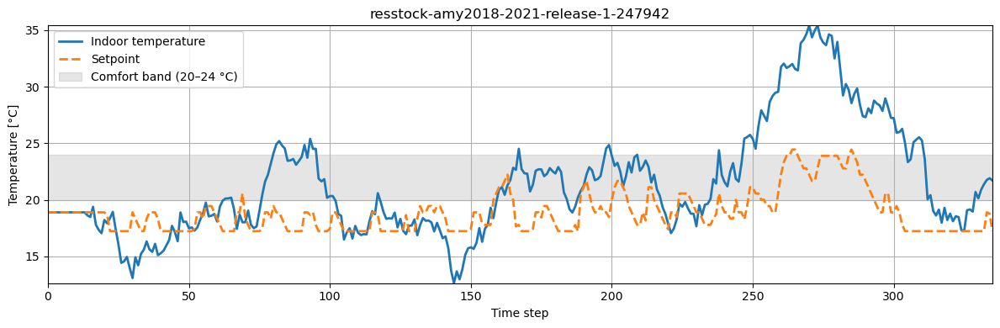

In [66]:
plot_comfort(env)

In [67]:
env = make_env(reward_function=ComfortReward)
print(env.observation_names)


[['month', 'hour', 'outdoor_dry_bulb_temperature', 'direct_solar_irradiance', 'outdoor_dry_bulb_temperature_predicted_1', 'outdoor_dry_bulb_temperature_predicted_2', 'outdoor_dry_bulb_temperature_predicted_3', 'direct_solar_irradiance_predicted_1', 'direct_solar_irradiance_predicted_2', 'direct_solar_irradiance_predicted_3', 'indoor_dry_bulb_temperature', 'non_shiftable_load', 'dhw_demand', 'cooling_demand', 'heating_demand', 'solar_generation', 'indoor_dry_bulb_temperature_cooling_set_point', 'indoor_dry_bulb_temperature_heating_set_point', 'comfort_band', 'indoor_dry_bulb_temperature_cooling_delta', 'indoor_dry_bulb_temperature_heating_delta', 'hvac_mode', 'electrical_storage_soc', 'net_electricity_consumption', 'cooling_electricity_consumption', 'heating_electricity_consumption', 'dhw_electricity_consumption', 'electrical_storage_electricity_consumption']]


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [87]:
import copy
import numpy as np
import torch
from citylearn.dynamics import LSTMDynamics


class SimpleMPC:
    """
    Pure tracking MPC using pretrained CityLearn LSTM.
    Cost = sum_k |Tin_k - Tsp|
    """

    def __init__(
        self,
        env,
        dynamics: LSTMDynamics,
        horizon: int = 6,
        n_samples: int = 128,
        u_min: float = 0.0,
        u_max: float = 1.0,
        seed: int = 0,
    ):
        self.env = env
        self.bld = env.unwrapped.buildings[0]
        self.dyn = dynamics

        self.horizon = int(horizon)
        self.n_samples = int(n_samples)
        self.u_min = float(u_min)
        self.u_max = float(u_max)

        self.rng = np.random.default_rng(seed)
        self._u_prev = 0.0

        # ---- LSTM metadata (CityLearn v2) ----
        self.names = self.dyn.input_observation_names
        self.mins = np.asarray(self.dyn.input_normalization_minimum, dtype=np.float32)
        self.maxs = np.asarray(self.dyn.input_normalization_maximum, dtype=np.float32)
        self.lookback = int(self.dyn.lookback)

        self.iTin = self.names.index("average_indoor_air_temperature")
        self.iHeat = self.names.index("heating_load")
        self.iTout = self.names.index("outdoor_air_temperature")

        self._ensure_buffers()

    # --------------------------------------------------
    # utilities
    # --------------------------------------------------
    def _norm(self, x, i):
        return (float(x) - self.mins[i]) / (self.maxs[i] - self.mins[i] + 1e-12)

    def _denorm(self, x, i):
        return float(x) * (self.maxs[i] - self.mins[i]) + self.mins[i]

    def _ensure_buffers(self):
        if getattr(self.dyn, "_model_input", None) is None:
            self._bootstrap_buffers()
        if getattr(self.dyn, "_hidden_state", None) is None:
            self.dyn._hidden_state = self.dyn.init_hidden(batch_size=1)

    def _bootstrap_buffers(self):
        t0 = int(self.bld.time_step)
        self.dyn._model_input = []

        for i, name in enumerate(self.names):
            buf = []
            for k in range(self.lookback + 1):
                t = max(0, t0 - (self.lookback - k))

                if name == "average_indoor_air_temperature":
                    raw = self.bld.energy_simulation.indoor_dry_bulb_temperature[t]
                elif name == "heating_load":
                    raw = self.bld.energy_simulation.heating_demand[t]
                elif name == "outdoor_air_temperature":
                    raw = self.bld.weather.outdoor_dry_bulb_temperature[t]
                else:
                    raw = 0.0

                buf.append(self._norm(raw, i))

            self.dyn._model_input.append(buf)

        self.dyn._hidden_state = self.dyn.init_hidden(batch_size=1)

    # --------------------------------------------------
    # MPC core
    # --------------------------------------------------
    def _extract_setpoint(self, obs_b):
        names = self.env.observation_names[0]
        if "indoor_dry_bulb_temperature_heating_set_point" in names:
            return float(obs_b[names.index(
                "indoor_dry_bulb_temperature_heating_set_point"
            )])
        if "indoor_dry_bulb_temperature_cooling_set_point" in names:
            return float(obs_b[names.index(
                "indoor_dry_bulb_temperature_cooling_set_point"
            )])
        return 21.0

    def _sample_u_sequences(self):
        return self.rng.uniform(
            self.u_min, self.u_max, size=(self.n_samples, self.horizon)
        )

    def _rollout_cost(self, u_seq, obs0):
        model_input = copy.deepcopy(self.dyn._model_input)
        h = (
            self.dyn._hidden_state[0].detach().clone(),
            self.dyn._hidden_state[1].detach().clone(),
        )

        Tsp = self._extract_setpoint(obs0)
        cost = 0.0
        t0 = int(self.bld.time_step)

        for k in range(self.horizon):

            # >>> DIAGNOSTIC: TRUE vs PRED Tin in lookback <<<
            # n_pred = min(k, self.lookback)
            # n_true = self.lookback - n_pred
            # print(
            #     f"[rollout k={k:02d}] Tin lookback = {n_true} TRUE + {n_pred} PRED"
            # )

            t = t0 + k
            if t >= len(self.bld.weather.outdoor_dry_bulb_temperature):
                break

            u = float(u_seq[k])

            # heating load from action (UNCHANGED LOGIC)
            if self.bld.energy_simulation.hvac_mode[t] in [2, 3]:
                heat = u * self.bld.heating_device.nominal_power
            else:
                heat = 0.0

            # >>> DIAGNOSTIC: HEATING LOAD COMPARISON <<<
            try:
                heat_true = self.bld.energy_simulation.heating_demand[t]
            except Exception:
                heat_true = np.nan

            print(
                f"[rollout k={k:02d}] "
                f"u={u:6.3f} | "
                f"heat_MPC={heat:9.2f} W | "
                f"heat_TRUE={heat_true:9.2f} W"
            )

            # update buffers (UNCHANGED)
            for i, name in enumerate(self.names):
                if name == "average_indoor_air_temperature":
                    x = model_input[i][-1]
                elif name == "heating_load":
                    x = self._norm(heat, i)
                elif name == "outdoor_air_temperature":
                    x = self._norm(
                        self.bld.weather.outdoor_dry_bulb_temperature[t], i
                    )
                else:
                    x = model_input[i][-1]

                model_input[i] = model_input[i][-self.lookback:] + [x]

            # build LSTM input (UNCHANGED)
            X_cols = []
            for i, name in enumerate(self.names):
                if name == "average_indoor_air_temperature":
                    X_cols.append(model_input[i][:-1])
                else:
                    X_cols.append(model_input[i][1:])

            X = torch.tensor(
                np.array(X_cols).T, dtype=torch.float32
            )[None, :, :]

            with torch.no_grad():
                y_norm, h = self.dyn(X, h)

            Tin = self._denorm(float(y_norm.item()), self.iTin)
            model_input[self.iTin][-1] = float(y_norm.item())

            cost += abs(Tin - Tsp)

        return cost

    def predict(self, observations):
        obs0 = observations[0]
        U = self._sample_u_sequences()

        best_cost = np.inf
        best_u = self._u_prev

        for s in range(self.n_samples):
            c = self._rollout_cost(U[s], obs0)
            if c < best_cost:
                best_cost = c
                best_u = float(U[s, 0])

        self._u_prev = best_u
        return [[best_u]]


In [88]:
mpc = SimpleMPC(
    env=env,
    dynamics=dyn,
    horizon=6,        # KEEP THIS SMALL
    n_samples=128,
    u_min=0.0,
    u_max=1.0,
    seed=0,
)

obs, _ = env.reset()
done = False

while not done:
    action = mpc.predict(obs)
    obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated


[rollout k=00] u= 0.637 | heat_MPC=     2.82 W | heat_TRUE=     3.53 W
[rollout k=01] u= 0.270 | heat_MPC=     1.19 W | heat_TRUE=     2.20 W
[rollout k=02] u= 0.041 | heat_MPC=     0.18 W | heat_TRUE=     1.44 W
[rollout k=03] u= 0.017 | heat_MPC=     0.07 W | heat_TRUE=     0.93 W
[rollout k=04] u= 0.813 | heat_MPC=     3.59 W | heat_TRUE=     0.63 W
[rollout k=05] u= 0.913 | heat_MPC=     4.03 W | heat_TRUE=     0.62 W
[rollout k=00] u= 0.607 | heat_MPC=     2.68 W | heat_TRUE=     3.53 W
[rollout k=01] u= 0.729 | heat_MPC=     3.22 W | heat_TRUE=     2.20 W
[rollout k=02] u= 0.544 | heat_MPC=     2.40 W | heat_TRUE=     1.44 W
[rollout k=03] u= 0.935 | heat_MPC=     4.13 W | heat_TRUE=     0.93 W
[rollout k=04] u= 0.816 | heat_MPC=     3.61 W | heat_TRUE=     0.63 W
[rollout k=05] u= 0.003 | heat_MPC=     0.01 W | heat_TRUE=     0.62 W
[rollout k=00] u= 0.857 | heat_MPC=     3.79 W | heat_TRUE=     3.53 W
[rollout k=01] u= 0.034 | heat_MPC=     0.15 W | heat_TRUE=     2.20 W
[rollo

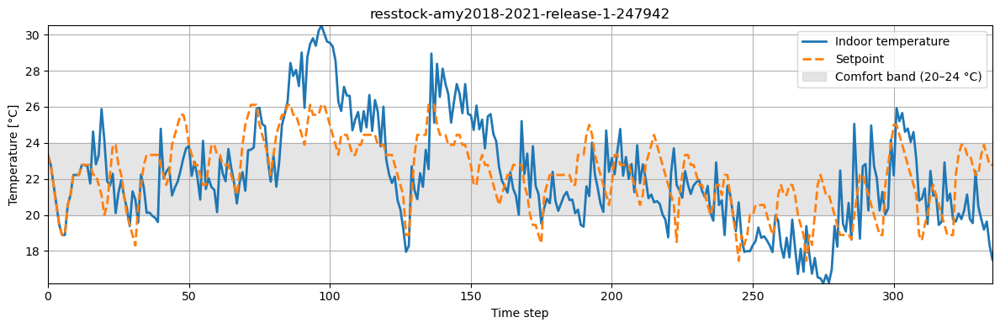

In [89]:
plot_comfort(env)

In [ ]:
import copy
import numpy as np
import torch
from citylearn.dynamics import LSTMDynamics


class SimpleMPC:
    """
    COP-aware tracking MPC using pretrained CityLearn LSTM.
    Cost = sum_k |Tin_k - Tsp|

    Key fix vs before:
      - Action u is interpreted as a normalized *electric power* command:
            P_elec = u * nominal_power_elec
      - The LSTM "heating_load" input is a *thermal* load (W_th), so we convert:
            Q_th = COP(Tout) * P_elec
      - This matches CityLearn-style heat pump physics and the paper’s equations.
    """

    def __init__(
        self,
        env,
        dynamics: LSTMDynamics,
        horizon: int = 6,
        n_samples: int = 128,
        u_min: float = 0.0,
        u_max: float = 1.0,
        seed: int = 0,
        debug: bool = False,
        debug_rollout_every: int = 1_000_000,  # set to 1 to print every rollout
        debug_k_max: int = 6,
    ):
        self.env = env
        self.bld = env.unwrapped.buildings[0]
        self.dyn = dynamics

        self.horizon = int(horizon)
        self.n_samples = int(n_samples)
        self.u_min = float(u_min)
        self.u_max = float(u_max)

        self.rng = np.random.default_rng(seed)
        self._u_prev = 0.0

        # debug controls
        self.debug = bool(debug)
        self.debug_rollout_every = int(debug_rollout_every)
        self.debug_k_max = int(debug_k_max)
        self._rollout_counter = 0

        # ---- LSTM metadata (CityLearn v2) ----
        self.names = self.dyn.input_observation_names
        self.mins = np.asarray(self.dyn.input_normalization_minimum, dtype=np.float32)
        self.maxs = np.asarray(self.dyn.input_normalization_maximum, dtype=np.float32)
        self.lookback = int(self.dyn.lookback)

        self.iTin = self.names.index("average_indoor_air_temperature")
        self.iHeat = self.names.index("heating_load")
        self.iTout = self.names.index("outdoor_air_temperature")

        self._ensure_buffers()

    # --------------------------------------------------
    # utilities
    # --------------------------------------------------
    def _norm(self, x, i):
        return (float(x) - self.mins[i]) / (self.maxs[i] - self.mins[i] + 1e-12)

    def _denorm(self, x, i):
        return float(x) * (self.maxs[i] - self.mins[i]) + self.mins[i]

    def _ensure_buffers(self):
        if getattr(self.dyn, "_model_input", None) is None:
            self._bootstrap_buffers()
        if getattr(self.dyn, "_hidden_state", None) is None:
            self.dyn._hidden_state = self.dyn.init_hidden(batch_size=1)

    def _bootstrap_buffers(self):
        t0 = int(self.bld.time_step)
        self.dyn._model_input = []

        for i, name in enumerate(self.names):
            buf = []
            for k in range(self.lookback + 1):
                t = max(0, t0 - (self.lookback - k))

                if name == "average_indoor_air_temperature":
                    raw = self.bld.energy_simulation.indoor_dry_bulb_temperature[t]
                elif name == "heating_load":
                    # dataset thermal demand (W_th) is consistent with LSTM training
                    raw = self.bld.energy_simulation.heating_demand[t]
                elif name == "outdoor_air_temperature":
                    raw = self.bld.weather.outdoor_dry_bulb_temperature[t]
                else:
                    raw = 0.0

                buf.append(self._norm(raw, i))

            self.dyn._model_input.append(buf)

        self.dyn._hidden_state = self.dyn.init_hidden(batch_size=1)

    # --------------------------------------------------
    # MPC core
    # --------------------------------------------------
    def _extract_setpoint(self, obs_b):
        names = self.env.observation_names[0]
        if "indoor_dry_bulb_temperature_heating_set_point" in names:
            return float(obs_b[names.index("indoor_dry_bulb_temperature_heating_set_point")])
        if "indoor_dry_bulb_temperature_cooling_set_point" in names:
            return float(obs_b[names.index("indoor_dry_bulb_temperature_cooling_set_point")])
        return 21.0

    def _sample_u_sequences(self):
        return self.rng.uniform(self.u_min, self.u_max, size=(self.n_samples, self.horizon))

    # -----------------------------
    # COP-aware heat pump mapping
    # -----------------------------
    def _safe_get_cop(self, t: int) -> float:
        """
        Best-effort COP getter that works across minor CityLearn API differences.
        Returns a positive COP (>= 1e-3).
        """
        Tout = float(self.bld.weather.outdoor_dry_bulb_temperature[t])

        hp = getattr(self.bld, "heating_device", None)
        if hp is None:
            return 1.0  # fallback (should not happen for your case)

        # Try common method signatures
        for kwargs in (
            {"outdoor_dry_bulb_temperature": Tout, "heating": True},
            {"outdoor_temperature": Tout, "heating": True},
            {"outdoor_dry_bulb_temperature": Tout},
            {"outdoor_temperature": Tout},
        ):
            try:
                cop = hp.get_cop(**kwargs)
                cop = float(cop)
                if np.isfinite(cop) and cop > 0.0:
                    return max(cop, 1e-3)
            except Exception:
                pass

        # Try attribute-style (rare)
        for attr in ("cop", "COP", "cop_heating"):
            if hasattr(hp, attr):
                try:
                    cop = float(getattr(hp, attr))
                    if np.isfinite(cop) and cop > 0.0:
                        return max(cop, 1e-3)
                except Exception:
                    pass

        # Last resort
        return 1.0

    # def _heat_from_action(self, u: float, t: int) -> tuple[float, float, float]:
    #     """
    #     Convert action u -> electric power -> thermal heating_load for LSTM.

    #     Returns:
    #       Q_th  : thermal heat delivered (W_th)  [fed to LSTM as heating_load]
    #       P_elec: electric power input (W_elec)
    #       COP   : coefficient of performance
    #     """
    #     # Only produce heat when heating HVAC mode is active (keeping your old gating)
    #     if self.bld.energy_simulation.hvac_mode[t] not in [2, 3]:
    #         return 0.0, 0.0, 0.0

    #     P_nom = float(self.bld.heating_device.nominal_power)  # electric nominal power
    #     P_elec = float(np.clip(u, self.u_min, self.u_max)) * P_nom

    #     COP = self._safe_get_cop(t)
    #     Q_th = COP * P_elec
    #     return Q_th, P_elec, COP
    
    def _heat_from_action(self, u: float, t: int) -> tuple[float, float, float]:
        if self.bld.energy_simulation.hvac_mode[t] not in [2, 3]:
            return 0.0, 0.0, 0.0

        # Treat nominal_power as THERMAL capacity (fits your magnitudes)
        Q_nom_th = float(self.bld.heating_device.nominal_power)
        Q_th = float(np.clip(u, self.u_min, self.u_max)) * Q_nom_th

        COP = self._safe_get_cop(t)
        P_elec = Q_th / max(COP, 1e-3)  # electric draw (for diagnostics)
        return Q_th, P_elec, COP


    def _rollout_cost(self, u_seq, obs0):
        self._rollout_counter += 1
        do_print = self.debug and (self._rollout_counter % self.debug_rollout_every == 0)

        model_input = copy.deepcopy(self.dyn._model_input)
        h = (
            self.dyn._hidden_state[0].detach().clone(),
            self.dyn._hidden_state[1].detach().clone(),
        )

        Tsp = self._extract_setpoint(obs0)
        cost = 0.0
        t0 = int(self.bld.time_step)

        for k in range(self.horizon):
            t = t0 + k
            if t >= len(self.bld.weather.outdoor_dry_bulb_temperature):
                break

            u = float(u_seq[k])

            # --- COP-aware mapping: u -> P_elec -> Q_th (heating_load) ---
            heat_th, p_elec, cop = self._heat_from_action(u, t)

            # Optional truth for diagnostics (thermal)
            try:
                heat_true = float(self.bld.energy_simulation.heating_demand[t])
            except Exception:
                heat_true = np.nan

            if do_print and k < self.debug_k_max:
                n_pred = min(k, self.lookback)
                n_true = self.lookback - n_pred
                print(f"[rollout k={k:02d}] Tin lookback = {n_true} TRUE + {n_pred} PRED")
                print(
                    f"[rollout k={k:02d}] "
                    f"u={u:6.3f} | "
                    f"P_elec={p_elec:9.2f} W_e | "
                    f"COP={cop:5.2f} | "
                    f"heat_MPC(Q_th)={heat_th:9.2f} W_th | "
                    f"heat_TRUE(Q_th)={heat_true:9.2f} W_th"
                )

            # update buffers
            for i, name in enumerate(self.names):
                if name == "average_indoor_air_temperature":
                    # last predicted Tin (normalized) is carried forward
                    x = model_input[i][-1]
                elif name == "heating_load":
                    # feed THERMAL heating_load to LSTM (this is the whole point)
                    x = self._norm(heat_th, i)
                elif name == "outdoor_air_temperature":
                    x = self._norm(self.bld.weather.outdoor_dry_bulb_temperature[t], i)
                else:
                    x = model_input[i][-1]

                model_input[i] = model_input[i][-self.lookback:] + [x]

            # build LSTM input (CityLearn shift rule)
            X_cols = []
            for i, name in enumerate(self.names):
                if name == "average_indoor_air_temperature":
                    X_cols.append(model_input[i][:-1])
                else:
                    X_cols.append(model_input[i][1:])

            X = torch.tensor(np.array(X_cols).T, dtype=torch.float32)[None, :, :]

            with torch.no_grad():
                y_norm, h = self.dyn(X, h)

            Tin = self._denorm(float(y_norm.item()), self.iTin)
            model_input[self.iTin][-1] = float(y_norm.item())

            cost += abs(Tin - Tsp)
                        # energy regularization (prevents "slam u")
            lam = 0.05  # start small; tune
            cost += lam * (u * u)


        return cost

    def predict(self, observations):
        obs0 = observations[0]
        U = self._sample_u_sequences()

        best_cost = np.inf
        best_u = self._u_prev

        for s in range(self.n_samples):
            c = self._rollout_cost(U[s], obs0)
            if c < best_cost:
                best_cost = c
                best_u = float(U[s, 0])

        self._u_prev = best_u
        return [[best_u]]


# -------------------------
# HOW TO RUN
# -------------------------
mpc = SimpleMPC(
    env=env,
    dynamics=dyn,
    horizon=12,
    n_samples=128,
    u_min=0.0,
    u_max=1.0,
    seed=0,
    debug=True,
    debug_rollout_every=200,
    debug_k_max=6,
)

obs, _ = env.reset()
done = False
while not done:
    action = mpc.predict(obs)
    obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated


[rollout k=00] Tin lookback = 6 TRUE + 0 PRED
[rollout k=00] u= 0.076 | P_elec=     0.34 W_e | COP= 1.70 | heat_MPC(Q_th)=     0.57 W_th | heat_TRUE(Q_th)=     2.20 W_th
[rollout k=01] Tin lookback = 5 TRUE + 1 PRED
[rollout k=01] u= 0.299 | P_elec=     1.32 W_e | COP= 1.67 | heat_MPC(Q_th)=     2.21 W_th | heat_TRUE(Q_th)=     1.44 W_th
[rollout k=02] Tin lookback = 4 TRUE + 2 PRED
[rollout k=02] u= 0.396 | P_elec=     1.75 W_e | COP= 1.67 | heat_MPC(Q_th)=     2.92 W_th | heat_TRUE(Q_th)=     0.93 W_th
[rollout k=03] Tin lookback = 3 TRUE + 3 PRED
[rollout k=03] u= 0.379 | P_elec=     1.67 W_e | COP= 1.66 | heat_MPC(Q_th)=     2.78 W_th | heat_TRUE(Q_th)=     0.63 W_th
[rollout k=04] Tin lookback = 2 TRUE + 4 PRED
[rollout k=04] u= 0.771 | P_elec=     3.41 W_e | COP= 1.64 | heat_MPC(Q_th)=     5.58 W_th | heat_TRUE(Q_th)=     0.62 W_th
[rollout k=05] Tin lookback = 1 TRUE + 5 PRED
[rollout k=05] u= 0.895 | P_elec=     3.95 W_e | COP= 1.67 | heat_MPC(Q_th)=     6.61 W_th | heat_TRUE(Q

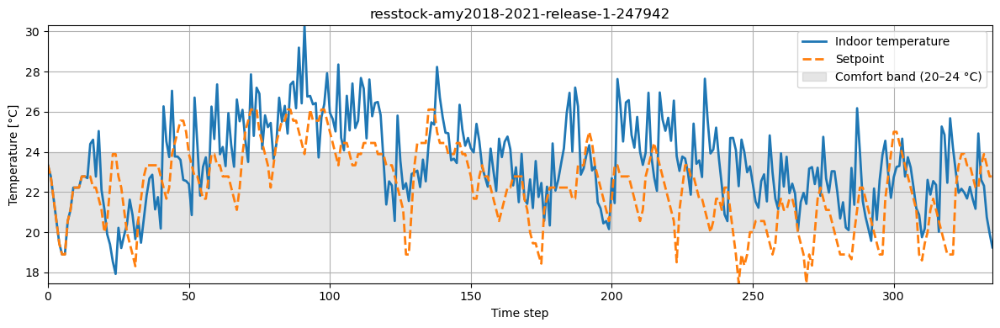

In [93]:
plot_comfort(env)

In [84]:
import copy
import numpy as np
import torch
from citylearn.dynamics import LSTMDynamics


class SimpleMPC:
    """
    Path A (open-loop w.r.t HVAC):
    - During MPC rollout, the LSTM is fed the *TRUE* heating_demand from the env dataset
      (b.energy_simulation.heating_demand[t]) instead of u * nominal_power.

    Cost = sum_k |Tin_k - Tsp|

    NOTE: This makes the rollout dynamics (almost) independent of u, by design.
    This is for diagnosing model quality/mismatch, not for a physically correct controller.
    """

    def __init__(
        self,
        env,
        dynamics: LSTMDynamics,
        horizon: int = 6,
        n_samples: int = 128,
        u_min: float = 0.0,
        u_max: float = 1.0,
        seed: int = 0,
        debug: bool = False,
        debug_rollout_every: int = 1_000_000,  # set to 1 to print every rollout; default effectively "off"
        debug_k_max: int = 6,                  # print only k < debug_k_max
    ):
        self.env = env
        self.bld = env.unwrapped.buildings[0]
        self.dyn = dynamics

        self.horizon = int(horizon)
        self.n_samples = int(n_samples)
        self.u_min = float(u_min)
        self.u_max = float(u_max)

        self.rng = np.random.default_rng(seed)
        self._u_prev = 0.0

        # debug controls
        self.debug = bool(debug)
        self.debug_rollout_every = int(debug_rollout_every)
        self.debug_k_max = int(debug_k_max)
        self._rollout_counter = 0

        # ---- LSTM metadata (CityLearn v2) ----
        self.names = self.dyn.input_observation_names
        self.mins = np.asarray(self.dyn.input_normalization_minimum, dtype=np.float32)
        self.maxs = np.asarray(self.dyn.input_normalization_maximum, dtype=np.float32)
        self.lookback = int(self.dyn.lookback)

        self.iTin = self.names.index("average_indoor_air_temperature")
        self.iHeat = self.names.index("heating_load")
        self.iTout = self.names.index("outdoor_air_temperature")

        self._ensure_buffers()

    # --------------------------------------------------
    # utilities
    # --------------------------------------------------
    def _norm(self, x, i):
        return (float(x) - self.mins[i]) / (self.maxs[i] - self.mins[i] + 1e-12)

    def _denorm(self, x, i):
        return float(x) * (self.maxs[i] - self.mins[i]) + self.mins[i]

    def _ensure_buffers(self):
        if getattr(self.dyn, "_model_input", None) is None:
            self._bootstrap_buffers()
        if getattr(self.dyn, "_hidden_state", None) is None:
            self.dyn._hidden_state = self.dyn.init_hidden(batch_size=1)

    def _bootstrap_buffers(self):
        t0 = int(self.bld.time_step)
        self.dyn._model_input = []

        for i, name in enumerate(self.names):
            buf = []
            for k in range(self.lookback + 1):
                t = max(0, t0 - (self.lookback - k))

                if name == "average_indoor_air_temperature":
                    raw = self.bld.energy_simulation.indoor_dry_bulb_temperature[t]
                elif name == "heating_load":
                    raw = self.bld.energy_simulation.heating_demand[t]
                elif name == "outdoor_air_temperature":
                    raw = self.bld.weather.outdoor_dry_bulb_temperature[t]
                else:
                    raw = 0.0

                buf.append(self._norm(raw, i))

            self.dyn._model_input.append(buf)

        self.dyn._hidden_state = self.dyn.init_hidden(batch_size=1)

    # --------------------------------------------------
    # MPC core
    # --------------------------------------------------
    def _extract_setpoint(self, obs_b):
        names = self.env.observation_names[0]
        if "indoor_dry_bulb_temperature_heating_set_point" in names:
            return float(obs_b[names.index("indoor_dry_bulb_temperature_heating_set_point")])
        if "indoor_dry_bulb_temperature_cooling_set_point" in names:
            return float(obs_b[names.index("indoor_dry_bulb_temperature_cooling_set_point")])
        return 21.0

    def _sample_u_sequences(self):
        return self.rng.uniform(self.u_min, self.u_max, size=(self.n_samples, self.horizon))

    def _rollout_cost(self, u_seq, obs0):
        self._rollout_counter += 1
        do_print = self.debug and (self._rollout_counter % self.debug_rollout_every == 0)

        model_input = copy.deepcopy(self.dyn._model_input)
        h = (
            self.dyn._hidden_state[0].detach().clone(),
            self.dyn._hidden_state[1].detach().clone(),
        )

        Tsp = self._extract_setpoint(obs0)
        cost = 0.0
        t0 = int(self.bld.time_step)

        for k in range(self.horizon):
            t = t0 + k
            if t >= len(self.bld.weather.outdoor_dry_bulb_temperature):
                break

            u = float(u_seq[k])

            # ------------------------------------------------------------------
            # PATH A CHANGE:
            #   Use TRUE heating demand from dataset/env for the LSTM input.
            #   (Action u does NOT affect the heating_load feature in rollout.)
            # ------------------------------------------------------------------
            heat_true = float(self.bld.energy_simulation.heating_demand[t])
            heat_used = heat_true  # <-- this is what gets fed into the LSTM

            # Keep the old "heat_MPC" computation ONLY for diagnostics/printing
            if self.bld.energy_simulation.hvac_mode[t] in [2, 3]:
                heat_mpc = u * self.bld.heating_device.nominal_power
            else:
                heat_mpc = 0.0

            if do_print and k < self.debug_k_max:
                n_pred = min(k, self.lookback)
                n_true = self.lookback - n_pred
                print(f"[rollout k={k:02d}] Tin lookback = {n_true} TRUE + {n_pred} PRED")
                print(
                    f"[rollout k={k:02d}] "
                    f"u={u:6.3f} | "
                    f"heat_USED(TRUE)={heat_used:9.2f} W | "
                    f"heat_MPC(ignored)={heat_mpc:9.2f} W"
                )

            # update buffers (UNCHANGED structure)
            for i, name in enumerate(self.names):
                if name == "average_indoor_air_temperature":
                    x = model_input[i][-1]
                elif name == "heating_load":
                    x = self._norm(heat_used, i)  # <-- feed TRUE heat
                elif name == "outdoor_air_temperature":
                    x = self._norm(self.bld.weather.outdoor_dry_bulb_temperature[t], i)
                else:
                    x = model_input[i][-1]

                model_input[i] = model_input[i][-self.lookback:] + [x]

            # build LSTM input (CityLearn shift rule; unchanged)
            X_cols = []
            for i, name in enumerate(self.names):
                if name == "average_indoor_air_temperature":
                    X_cols.append(model_input[i][:-1])
                else:
                    X_cols.append(model_input[i][1:])

            X = torch.tensor(np.array(X_cols).T, dtype=torch.float32)[None, :, :]

            with torch.no_grad():
                y_norm, h = self.dyn(X, h)

            Tin = self._denorm(float(y_norm.item()), self.iTin)
            model_input[self.iTin][-1] = float(y_norm.item())

            cost += abs(Tin - Tsp)

        return cost

    def predict(self, observations):
        obs0 = observations[0]
        U = self._sample_u_sequences()

        best_cost = np.inf
        best_u = self._u_prev

        for s in range(self.n_samples):
            c = self._rollout_cost(U[s], obs0)
            if c < best_cost:
                best_cost = c
                best_u = float(U[s, 0])

        self._u_prev = best_u
        return [[best_u]]


# -------------------------
# HOW TO RUN
# -------------------------
mpc = SimpleMPC(
    env=env,
    dynamics=dyn,
    horizon=12,
    n_samples=128,
    u_min=0.0,
    u_max=1.0,
    seed=0,
    debug=True,
    debug_rollout_every=200,  # print diagnostics once every 200 rollouts (avoid spam)
    debug_k_max=6
)

obs, _ = env.reset()
done = False
while not done:
    action = mpc.predict(obs)
    obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated


[rollout k=00] Tin lookback = 6 TRUE + 0 PRED
[rollout k=00] u= 0.076 | heat_USED(TRUE)=     2.20 W | heat_MPC(ignored)=     0.34 W
[rollout k=01] Tin lookback = 5 TRUE + 1 PRED
[rollout k=01] u= 0.299 | heat_USED(TRUE)=     1.44 W | heat_MPC(ignored)=     1.32 W
[rollout k=02] Tin lookback = 4 TRUE + 2 PRED
[rollout k=02] u= 0.396 | heat_USED(TRUE)=     0.93 W | heat_MPC(ignored)=     1.75 W
[rollout k=03] Tin lookback = 3 TRUE + 3 PRED
[rollout k=03] u= 0.379 | heat_USED(TRUE)=     0.63 W | heat_MPC(ignored)=     1.67 W
[rollout k=04] Tin lookback = 2 TRUE + 4 PRED
[rollout k=04] u= 0.771 | heat_USED(TRUE)=     0.62 W | heat_MPC(ignored)=     3.41 W
[rollout k=05] Tin lookback = 1 TRUE + 5 PRED
[rollout k=05] u= 0.895 | heat_USED(TRUE)=     1.08 W | heat_MPC(ignored)=     3.95 W
[rollout k=00] Tin lookback = 6 TRUE + 0 PRED
[rollout k=00] u= 0.056 | heat_USED(TRUE)=     0.93 W | heat_MPC(ignored)=     0.25 W
[rollout k=01] Tin lookback = 5 TRUE + 1 PRED
[rollout k=01] u= 0.217 | heat

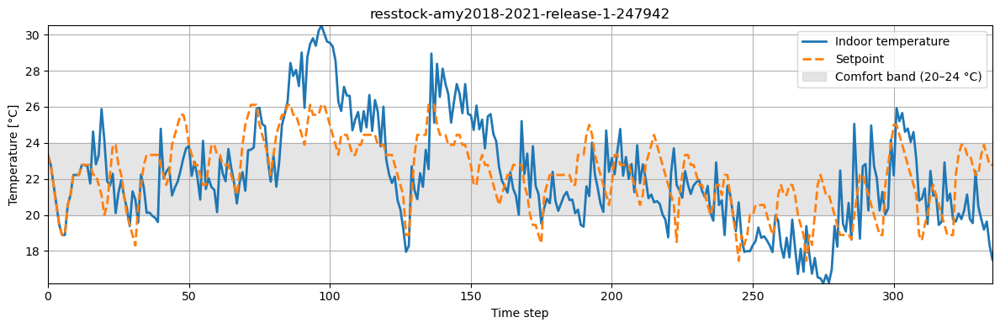

In [91]:
plot_comfort(env)

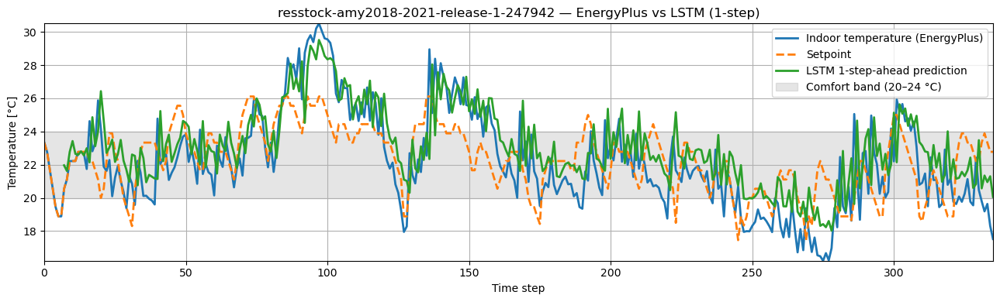

In [71]:
plot_comfort_with_lstm_1step(env, dyn, building_idx=0)

In [134]:
def plot_energyplus_vs_lstm_debug(env, dyn, horizon=500):
    obs, _ = env.reset()
    b = env.unwrapped.buildings[0]

    names = dyn.input_observation_names
    mins = np.array(dyn.input_normalization_minimum, dtype=np.float32)
    maxs = np.array(dyn.input_normalization_maximum, dtype=np.float32)
    lookback = int(dyn.lookback)

    iTin = names.index("average_indoor_air_temperature")

    def norm(x, i):
        return (float(x) - float(mins[i])) / (float(maxs[i]) - float(mins[i]) + 1e-8)

    def denorm_tin(y_norm):
        mn, mx = float(mins[iTin]), float(maxs[iTin])
        return float(y_norm) * (mx - mn) + mn

    # ---------------- bootstrap ----------------
    t0 = int(b.time_step)
    model_input = []

    for i, name in enumerate(names):
        buf = []
        for k in range(lookback + 1):
            t = max(0, t0 - (lookback - k))

            if name == "average_indoor_air_temperature":
                raw = b.energy_simulation.indoor_dry_bulb_temperature[t]
            elif name == "outdoor_air_temperature":
                raw = b.weather.outdoor_dry_bulb_temperature[t]
            elif name == "direct_solar_radiation":
                raw = b.weather.direct_solar_irradiance[t]
            elif name == "diffuse_solar_radiation":
                raw = b.weather.diffuse_solar_irradiance[t]
            elif name == "heating_load":
                raw = b.energy_simulation.heating_demand[t]
            else:
                raw = 0.0  # occupant + time encodings frozen

            buf.append(norm(raw, i))

        model_input.append(buf)

    h = dyn.init_hidden(batch_size=1)

    Tin_true, Tin_pred = [], []
    Tin_true_norm, Tin_pred_norm = [], []

    # ---------------- rollout ----------------
    for k in range(min(horizon, len(b.weather.outdoor_dry_bulb_temperature) - t0 - 1)):
        t = t0 + k

        for i, name in enumerate(names):
            if name == "heating_load":
                x = norm(b.energy_simulation.heating_demand[t], i)
            elif name == "outdoor_air_temperature":
                x = norm(b.weather.outdoor_dry_bulb_temperature[t], i)
            elif name == "direct_solar_radiation":
                x = norm(b.weather.direct_solar_irradiance[t], i)
            elif name == "diffuse_solar_radiation":
                x = norm(b.weather.diffuse_solar_irradiance[t], i)
            elif name == "average_indoor_air_temperature":
                x = model_input[i][-1]
            else:
                x = model_input[i][-1]

            model_input[i] = model_input[i][-lookback:] + [float(x)]

        X_cols = []
        for i, name in enumerate(names):
            if name == "average_indoor_air_temperature":
                X_cols.append(model_input[i][:-1])
            else:
                X_cols.append(model_input[i][1:])

        X = torch.tensor(np.array(X_cols, dtype=np.float32).T)[None, :, :]

        with torch.no_grad():
            y_norm, h = dyn(X.float(), h)

        Tin_p = denorm_tin(float(y_norm.item()))
        Tin_t = float(b.energy_simulation.indoor_dry_bulb_temperature[t])

        Tin_true.append(Tin_t)
        Tin_pred.append(Tin_p)
        Tin_true_norm.append(norm(Tin_t, iTin))
        Tin_pred_norm.append(float(y_norm.item()))

        model_input[iTin][-1] = float(y_norm.item())

    # ---------------- plots ----------------
    plt.figure(figsize=(12,4))
    plt.plot(Tin_true_norm, label="EnergyPlus Tin (norm)", linewidth=2)
    plt.plot(Tin_pred_norm, "--", label="LSTM Tin pred (norm)", linewidth=2)
    plt.legend(); plt.grid(True); plt.tight_layout()
    plt.show()

    plt.figure(figsize=(12,4))
    plt.plot(Tin_true, label="EnergyPlus Tin (°C)", linewidth=2)
    plt.plot(Tin_pred, "--", label="LSTM Tin pred (°C)", linewidth=2)
    plt.legend(); plt.grid(True); plt.tight_layout()
    plt.show()


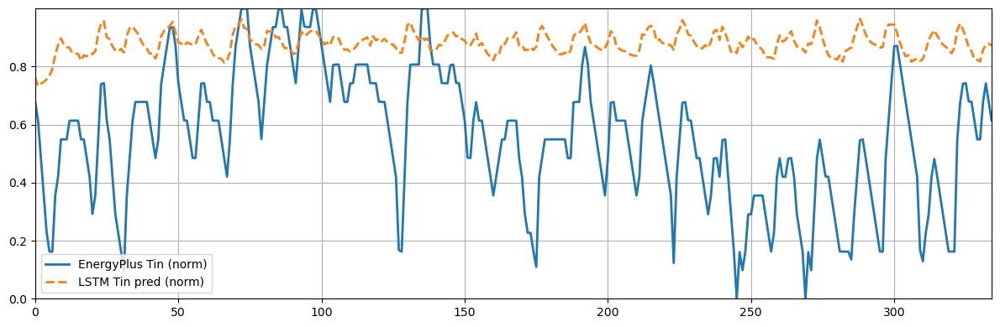

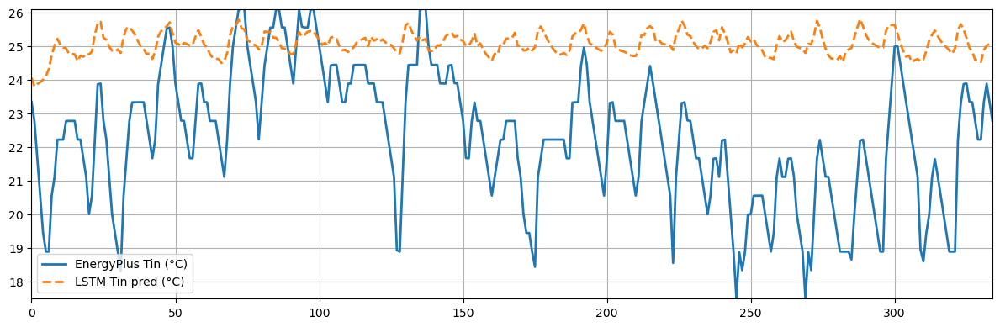

In [ ]:
def override_tin_bounds(dyn, env):
    b = env.unwrapped.buildings[0]

    iTin = dyn.input_observation_names.index(
        "average_indoor_air_temperature"
    )

    mins = list(dyn.input_normalization_minimum)
    maxs = list(dyn.input_normalization_maximum)

    mins[iTin] = float(np.min(b.energy_simulation.indoor_dry_bulb_temperature))
    maxs[iTin] = float(np.max(b.energy_simulation.indoor_dry_bulb_temperature))

    dyn.input_normalization_minimum = mins
    dyn.input_normalization_maximum = maxs

# use it
override_tin_bounds(dyn, env)
plot_energyplus_vs_lstm_debug(env, dyn, horizon=500)

In [141]:
import numpy as np
import torch
import matplotlib.pyplot as plt

def get_dyn_from_env(env, building_index=0):
    b = env.unwrapped.buildings[building_index]
    # σε πολλά forks είναι .dynamics_model ή .dynamics
    for attr in ["dynamics_model", "dynamics", "_dynamics", "lstm_dynamics"]:
        if hasattr(b, attr):
            return b, getattr(b, attr)
    # fallback: ψάχνουμε κάτι που είναι torch.nn.Module και μοιάζει dynamics
    for attr in dir(b):
        obj = getattr(b, attr)
        if isinstance(obj, torch.nn.Module) and "dyn" in attr.lower():
            return b, obj
    raise RuntimeError("Δεν βρέθηκε dynamics module στο building.")

def denorm_from_dyn(dyn, name, y_norm):
    names = list(dyn.input_observation_names)
    mins = np.array(dyn.input_normalization_minimum, dtype=np.float32)
    maxs = np.array(dyn.input_normalization_maximum, dtype=np.float32)
    i = names.index(name)
    return float(y_norm) * (float(maxs[i]) - float(mins[i])) + float(mins[i])

def compare_citylearn_vs_loaded_one_step(env, dyn_loaded, horizon=300, seed=0, building_index=0):
    device = next(dyn_loaded.parameters()).device if any(True for _ in dyn_loaded.parameters()) else torch.device("cpu")
    dyn_loaded.eval()

    # reset env
    obs, info = env.reset(seed=seed)

    b, dyn_city = get_dyn_from_env(env, building_index=building_index)
    dyn_city.eval()

    captured = {"X": None, "h": None, "y": None}

    # Hook: πιάνει (X, h) και output y από το CityLearn dynamics forward
    def hook_fn(module, inputs, output):
        # forward signature συνήθως: (X, h) -> (y, h_next) ή y
        # inputs = (X, h)
        X = inputs[0]
        h = inputs[1] if len(inputs) > 1 else None

        if isinstance(output, tuple) and len(output) == 2:
            y, h_next = output
            captured["y"] = y.detach().cpu()
            captured["X"] = X.detach().cpu()
            captured["h"] = h.detach().cpu() if torch.is_tensor(h) else None
        else:
            captured["y"] = output.detach().cpu()
            captured["X"] = X.detach().cpu()
            captured["h"] = h.detach().cpu() if torch.is_tensor(h) else None

    handle = dyn_city.register_forward_hook(hook_fn)

    y_city_norm_list = []
    y_loaded_norm_list = []
    tin_next_list = []

    # rollout
    for k in range(horizon):
        a = [space.sample() for space in env.action_space]


        captured["X"] = captured["h"] = captured["y"] = None
        step_out = env.step(a)

        # συμβατό με gymnasium / gym
        if len(step_out) == 5:
            obs, reward, terminated, truncated, info = step_out
            done = terminated or truncated
        else:
            obs, reward, done, info = step_out

        # Μετά το step πρέπει να έχει καλεστεί το dynamics και να έχουμε X/y
        if captured["X"] is None or captured["y"] is None:
            handle.remove()
            raise RuntimeError("Δεν πιάστηκε forward από το CityLearn dynamics. Το hook δεν ενεργοποιήθηκε.")

        X = captured["X"].to(device)
        h = captured["h"]
        y_city = captured["y"].to(device)

        # τρέχεις το δικό σου loaded model στο *ίδιο ακριβώς* X και h
        with torch.no_grad():
            if h is not None:
                y_loaded, _ = dyn_loaded(X.float(), h.to(device))
            else:
                out = dyn_loaded(X.float())
                y_loaded = out[0] if isinstance(out, tuple) else out

        # y είναι normalised Tin_{t+1}
        y_city_norm = float(y_city.squeeze().detach().cpu().item())
        y_loaded_norm = float(y_loaded.squeeze().detach().cpu().item())

        y_city_norm_list.append(y_city_norm)
        y_loaded_norm_list.append(y_loaded_norm)

        # “realized” Tin μετά το step από το env (CityLearn runtime)
        # indoor_dry_bulb_temperature είναι read-only αλλά ενημερώνεται
        tin_next_list.append(float(b.indoor_dry_bulb_temperature))

        if done:
            break

    handle.remove()

    # denorm σε °C για να έχουν νόημα τα plots
    y_city_c = [denorm_from_dyn(dyn_city, "average_indoor_air_temperature", v) for v in y_city_norm_list]
    y_loaded_c = [denorm_from_dyn(dyn_city, "average_indoor_air_temperature", v) for v in y_loaded_norm_list]

    # metrics
    diff_models = np.abs(np.array(y_city_c) - np.array(y_loaded_c))
    err_to_env = np.abs(np.array(tin_next_list) - np.array(y_city_c))

    print(f"MAE(model_loaded vs citylearn_model) [°C]: {diff_models.mean():.4f}")
    print(f"MAX(model_loaded vs citylearn_model) [°C]: {diff_models.max():.4f}")
    print(f"MAE(citylearn_pred vs env Tin_next) [°C]: {err_to_env.mean():.4f}")

    # plots
    plt.figure(figsize=(14,4))
    plt.plot(tin_next_list, label="Env Tin_next (CityLearn realized)")
    plt.plot(y_city_c, "--", label="CityLearn LSTM pred (Tin_next)")
    plt.plot(y_loaded_c, ":", label="Loaded LSTM pred (Tin_next)")
    plt.grid(True); plt.legend(); plt.tight_layout()
    plt.show()

    plt.figure(figsize=(14,4))
    plt.plot(diff_models, label="|Loaded - CityLearn| (°C)")
    plt.grid(True); plt.legend(); plt.tight_layout()
    plt.show()

    return {
        "tin_next": tin_next_list,
        "citylearn_pred_c": y_city_c,
        "loaded_pred_c": y_loaded_c,
    }


In [142]:
# env = CityLearnEnv(schema=SCHEMA_PATH)  (το έχεις ήδη)
# dyn_loaded = ...  (το δικό σου loaded LSTM module)
res = compare_citylearn_vs_loaded_one_step(env, dyn, horizon=300, seed=0)


RuntimeError: Δεν πιάστηκε forward από το CityLearn dynamics. Το hook δεν ενεργοποιήθηκε.

In [143]:
b = env.unwrapped.buildings[0]

print("Building type:", type(b))

for attr in dir(b):
    obj = getattr(b, attr)
    if isinstance(obj, torch.nn.Module):
        print("NN module attr:", attr, "->", type(obj))


Building type: <class 'citylearn.building.LSTMDynamicsBuilding'>
NN module attr: dynamics -> <class 'citylearn.dynamics.LSTMDynamics'>


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (5,) + inhomogeneous part.

In [146]:
import torch
ckpt = torch.load(MODEL_PATH, map_location="cpu")

print(type(ckpt))
print(ckpt.keys())
print("n_params in ckpt model:", len(ckpt["model_state_dict"]))
print("example keys:", list(ckpt["model_state_dict"].keys())[:5])


<class 'dict'>
dict_keys(['model_state_dict', 'optimizer_state_dict', 'epoch', 'train_loss', 'val_loss'])
n_params in ckpt model: 10
example keys: ['l_lstm.weight_ih_l0', 'l_lstm.weight_hh_l0', 'l_lstm.bias_ih_l0', 'l_lstm.bias_hh_l0', 'l_lstm.weight_ih_l1']


/tmp/ipykernel_8686/2419388991.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(MODEL_PATH, map_location="cpu")


In [144]:
for attr in dir(b):
    obj = getattr(b, attr)
    if isinstance(obj, torch.nn.Module):
        print(attr, type(obj))


dynamics <class 'citylearn.dynamics.LSTMDynamics'>


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (5,) + inhomogeneous part.

In [147]:
b = env.unwrapped.buildings[0]

# βρες το πραγματικό nn.Module του CityLearn
dyn_city = None
for attr in dir(b):
    obj = getattr(b, attr)
    if isinstance(obj, torch.nn.Module):
        dyn_city = obj
        print("FOUND:", attr, type(obj))

sd_city = dyn_city.state_dict()
sd_ckpt = ckpt["model_state_dict"]

print("same keys:", set(sd_city.keys()) == set(sd_ckpt.keys()))

max_diff = 0.0
for k in sd_city:
    if k in sd_ckpt:
        diff = (sd_city[k] - sd_ckpt[k]).abs().max().item()
        max_diff = max(max_diff, diff)

print("max weight diff:", max_diff)


FOUND: dynamics <class 'citylearn.dynamics.LSTMDynamics'>


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (5,) + inhomogeneous part.

In [148]:
b = env.unwrapped.buildings[0]

arrays = [
    b.cooling_storage_electricity_consumption,
    b.heating_storage_electricity_consumption,
    b.dhw_storage_electricity_consumption,
    b.electrical_storage_electricity_consumption,
]

for i, a in enumerate(arrays):
    print(i, type(a), np.shape(a))


0 <class 'numpy.ndarray'> (2,)
1 <class 'numpy.ndarray'> (2,)
2 <class 'numpy.ndarray'> (2,)
3 <class 'numpy.ndarray'> (2,)


In [150]:
sd_city = dyn_city.state_dict()
sd_ckpt = ckpt["model_state_dict"]

print(set(sd_city.keys()) == set(sd_ckpt.keys()))

max_diff = max(
    (sd_city[k] - sd_ckpt[k]).abs().max().item()
    for k in sd_city if k in sd_ckpt
)

print(max_diff)


True


RuntimeError: The size of tensor a (13) must match the size of tensor b (12) at non-singleton dimension 1

In [151]:
print(dyn_city)


LSTMDynamics(
  (l_lstm): LSTM(13, 8, num_layers=2, batch_first=True)
  (l_linear): Linear(in_features=8, out_features=1, bias=True)
  (dropout): Dropout(p=0.0, inplace=False)
)


In [153]:
print(ckpt["model_state_dict"].keys())


odict_keys(['l_lstm.weight_ih_l0', 'l_lstm.weight_hh_l0', 'l_lstm.bias_ih_l0', 'l_lstm.bias_hh_l0', 'l_lstm.weight_ih_l1', 'l_lstm.weight_hh_l1', 'l_lstm.bias_ih_l1', 'l_lstm.bias_hh_l1', 'l_linear.weight', 'l_linear.bias'])


In [154]:
for k in sd_city:
    if k in sd_ckpt:
        print(k, sd_city[k].shape, sd_ckpt[k].shape)


l_lstm.weight_ih_l0 torch.Size([32, 13]) torch.Size([96, 12])
l_lstm.weight_hh_l0 torch.Size([32, 8]) torch.Size([96, 24])
l_lstm.bias_ih_l0 torch.Size([32]) torch.Size([96])
l_lstm.bias_hh_l0 torch.Size([32]) torch.Size([96])
l_lstm.weight_ih_l1 torch.Size([32, 8]) torch.Size([96, 24])
l_lstm.weight_hh_l1 torch.Size([32, 8]) torch.Size([96, 24])
l_lstm.bias_ih_l1 torch.Size([32]) torch.Size([96])
l_lstm.bias_hh_l1 torch.Size([32]) torch.Size([96])
l_linear.weight torch.Size([1, 8]) torch.Size([1, 24])
l_linear.bias torch.Size([1]) torch.Size([1])


In [155]:
print(b.__dict__.keys())


dict_keys(['dynamics', 'ignore_dynamics', '_Building__name', '_Building__dhw_storage', '_Building__cooling_storage', '_Building__heating_storage', '_Building__electrical_storage', '_Building__dhw_device', '_Building__cooling_device', '_Building__heating_device', '_Building__non_shiftable_load_device', '_Building__pv', '_Environment__seconds_per_time_step', '_Environment__uid', '_Environment__random_seed', '_Environment__time_step', '_Environment__episode_tracker', '_Environment__time_step_ratio', '_Building__stochastic_power_outage_model', '_Building__electric_vehicle_chargers', '_Building__energy_simulation', '_Building__weather', '_Building__carbon_intensity', '_Building__pricing', '_Building__district_load_target', '_Building__observation_metadata', '_Building__action_metadata', '_Building__observation_space_limit_delta', '_Building__maximum_temperature_delta', '_Building__demand_observation_limit_factor', '_Building__simulate_power_outage', '_Building__stochastic_power_outage', 'no

In [164]:
print("dyn filepath:", getattr(dyn, "filepath", None))
print("dyn inputs:", dyn.input_observation_names)
print("dyn lookback:", dyn.lookback)


dyn filepath: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/simulation/data/lstm_pth/model_pth_VT, Chittenden County_247942.pth
dyn inputs: ['direct_solar_radiation', 'diffuse_solar_radiation', 'outdoor_air_temperature', 'occupant_count', 'heating_load', 'sin_month', 'cos_month', 'sin_hour', 'cos_hour', 'sin_DoW', 'cos_DoW', 'average_indoor_air_temperature']
dyn lookback: 6


In [158]:
import numpy as np
import torch

def one_step_rmse_teacher_forced(env, dyn, n_steps=500, action=None):
    """
    1-step-ahead RMSE with teacher forcing:
      - uses true Tin history (EnergyPlus) in the input window
      - uses true exogenous inputs from env observations
      - predicts Tin_{t+1} and compares to true Tin_{t+1}

    This is the cleanest "is the LSTM working?" metric.
    """
    if action is None:
        # default: all zeros actions, correct dimension
        action = [0.0] * env.action_space[0].shape[0]

    obs, _ = env.reset()
    b = env.unwrapped.buildings[0]

    names = dyn.input_observation_names
    mins = np.asarray(dyn.input_normalization_minimum, dtype=np.float32)
    maxs = np.asarray(dyn.input_normalization_maximum, dtype=np.float32)
    lookback = int(dyn.lookback)

    # CityLearn v2 LSTM naming
    iTin = names.index("average_indoor_air_temperature")

    def norm(x, i):
        return (float(x) - float(mins[i])) / (float(maxs[i]) - float(mins[i]) + 1e-8)

    def denorm(y, i):
        return float(y) * (float(maxs[i]) - float(mins[i])) + float(mins[i])

    # map LSTM feature names -> indices in env observation vector
    obs_names = env.observation_names[0]

    # These env keys are what we *try* to pull from obs.
    # If your env uses slightly different names, print obs_names and adjust mapping.
    OBS_KEYMAP = {
        "direct_solar_radiation": "direct_solar_irradiance",
        "diffuse_solar_radiation": "diffuse_solar_irradiance",
        "outdoor_air_temperature": "outdoor_dry_bulb_temperature",
        "occupant_count": "occupant_count",
        "heating_load": "heating_demand",
        "sin_month": "sin_month",
        "cos_month": "cos_month",
        "sin_hour": "sin_hour",
        "cos_hour": "cos_hour",
        "sin_DoW": "sin_day_of_week",
        "cos_DoW": "cos_day_of_week",
        # indoor temp is teacher-forced from EnergyPlus arrays, not obs
        "average_indoor_air_temperature": None,
    }

    def obs_idx(key):
        if key is None:
            return None
        try:
            return obs_names.index(key)
        except ValueError:
            return None

    obs_indices = {feat: obs_idx(OBS_KEYMAP.get(feat, feat)) for feat in names}

    # buffers: (lookback+1) per feature like CityLearn dynamics uses
    t0 = int(b.time_step)
    model_input = []
    for i, feat in enumerate(names):
        buf = []
        for k in range(lookback + 1):
            t = max(0, t0 - (lookback - k))

            if feat == "average_indoor_air_temperature":
                raw = float(b.energy_simulation.indoor_dry_bulb_temperature[t])
            else:
                j = obs_indices.get(feat, None)
                if j is None:
                    # if feature isn't in obs, freeze at 0
                    raw = 0.0
                else:
                    raw = float(obs[0][j])

            buf.append(norm(raw, i))
        model_input.append(buf)

    h = dyn.init_hidden(batch_size=1)

    preds = []
    trues = []

    # We need t and t+1 -> step n_steps times but record prediction for next step
    for _ in range(n_steps):
        t = int(b.time_step)

        # update feature buffers for current time t
        for i, feat in enumerate(names):
            if feat == "average_indoor_air_temperature":
                # teacher forcing: use true Tin at time t
                raw = float(b.energy_simulation.indoor_dry_bulb_temperature[t])
                x = norm(raw, i)
            else:
                j = obs_indices.get(feat, None)
                raw = 0.0 if j is None else float(obs[0][j])
                x = norm(raw, i)

            model_input[i] = model_input[i][-lookback:] + [float(x)]

        # build X using CityLearn shift rule
        X_cols = []
        for i, feat in enumerate(names):
            if feat == "average_indoor_air_temperature":
                X_cols.append(model_input[i][:-1])
            else:
                X_cols.append(model_input[i][1:])
        X = torch.tensor(np.array(X_cols, dtype=np.float32).T)[None, :, :]

        with torch.no_grad():
            y_norm, h = dyn(X.float(), h)

        # predicted Tin_{t+1}
        Tin_pred = denorm(float(y_norm.item()), iTin)

        # advance env one step to get true Tin_{t+1}
        obs, _, terminated, truncated, _ = env.step([action])
        done = terminated or truncated

        t_next = int(b.time_step)
        Tin_true = float(b.energy_simulation.indoor_dry_bulb_temperature[t_next])

        preds.append(Tin_pred)
        trues.append(Tin_true)

        if done:
            break

    preds = np.asarray(preds)
    trues = np.asarray(trues)
    rmse = float(np.sqrt(np.mean((preds - trues) ** 2)))
    mae = float(np.mean(np.abs(preds - trues)))

    return rmse, mae, preds, trues


In [159]:
rmse, mae, preds, trues = one_step_rmse_teacher_forced(env, dyn, n_steps=500)
print("1-step RMSE [°C]:", rmse)
print("1-step MAE  [°C]:", mae)


1-step RMSE [°C]: 6.156291758791007
1-step MAE  [°C]: 5.742740769597043


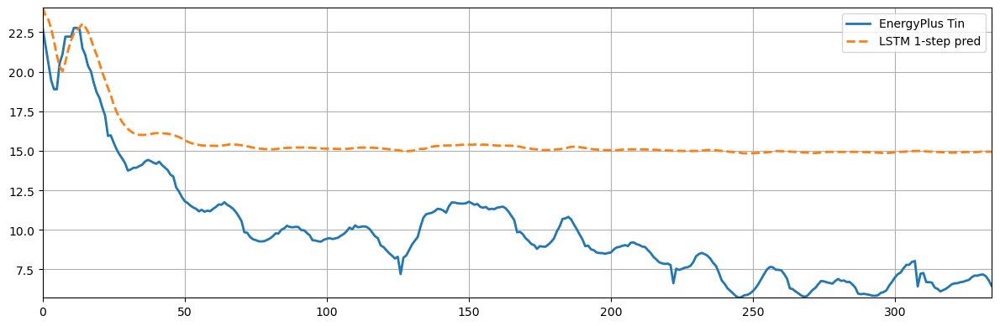

In [173]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))
plt.plot(trues, label="EnergyPlus Tin", linewidth=2)
plt.plot(preds, "--", label="LSTM 1-step pred", linewidth=2)
plt.legend(); plt.grid(True); plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import torch

def proper_one_step_rmse(env, dyn, n_steps=500):
    obs, _ = env.reset()
    b = env.unwrapped.buildings[0]

    names = dyn.input_observation_names
    mins = np.asarray(dyn.input_normalization_minimum, dtype=np.float32)
    maxs = np.asarray(dyn.input_normalization_maximum, dtype=np.float32)
    lookback = int(dyn.lookback)

    # index of Tin in LSTM
    iTin = names.index("average_indoor_air_temperature")

    def norm(x, i):
        return (float(x) - mins[i]) / (maxs[i] - mins[i] + 1e-8)

    def denorm(y, i):
        return y * (maxs[i] - mins[i]) + mins[i]

    # map LSTM feature -> env observation index
    obs_names = env.observation_names[0]

    OBS_MAP = {
        "direct_solar_radiation": "direct_solar_irradiance",
        "diffuse_solar_radiation": "diffuse_solar_irradiance",
        "outdoor_air_temperature": "outdoor_dry_bulb_temperature",
        "sin_month": "sin_month",
        "cos_month": "cos_month",
        "sin_hour": "sin_hour",
        "cos_hour": "cos_hour",
        "sin_DoW": "sin_day_of_week",
        "cos_DoW": "cos_day_of_week",
    }

    obs_idx = {}
    for k, v in OBS_MAP.items():
        obs_idx[k] = obs_names.index(v)

    # bootstrap input buffers (CityLearn-style)
    t0 = int(b.time_step)
    model_input = []

    for i, feat in enumerate(names):
        buf = []
        for k in range(lookback + 1):
            t = max(0, t0 - (lookback - k))

            if feat == "average_indoor_air_temperature":
                raw = b.energy_simulation.indoor_dry_bulb_temperature[t]
            elif feat == "heating_load":
                raw = b.energy_simulation.heating_demand[t]
            elif feat == "occupant_count":
                raw = b.energy_simulation.occupant_count[t]
            elif feat in obs_idx:
                raw = obs[0][obs_idx[feat]]
            else:
                raw = 0.0

            buf.append(norm(raw, i))
        model_input.append(buf)

    h = dyn.init_hidden(batch_size=1)4.0

    preds, trues = [], []

    for _ in range(n_steps):
        t = int(b.time_step)

        # update buffers with TRUE values at time t
        for i, feat in enumerate(names):
            if feat == "average_indoor_air_temperature":
                raw = b.energy_simulation.indoor_dry_bulb_temperature[t]
            elif feat == "heating_load":
                raw = b.energy_simulation.heating_demand[t]
            elif feat == "occupant_count":
                raw = b.energy_simulation.occupant_count[t]
            elif feat in obs_idx:
                raw = obs[0][obs_idx[feat]]
            else:
                raw = 0.0

            model_input[i] = model_input[i][-lookback:] + [norm(raw, i)]

        # build input tensor
        X_cols = []
        for i, feat in enumerate(names):
            if feat == "average_indoor_air_temperature":
                X_cols.append(model_input[i][:-1])
            else:
                X_cols.append(model_input[i][1:])
        X = torch.tensor(np.array(X_cols).T, dtype=torch.float32)[None, :, :]

        with torch.no_grad():
            y_norm, h = dyn(X, h)

        Tin_pred = denorm(float(y_norm.item()), iTin)

        # advance env ONE step
        obs, _, terminated, truncated, _ = env.step([[0.0, 0.0]])
        if terminated or truncated:
            break

        Tin_true = b.energy_simulation.indoor_dry_bulb_temperature[int(b.time_step)]

        preds.append(Tin_pred)
        trues.append(Tin_true)

    preds = np.asarray(preds)
    trues = np.asarray(trues)

    rmse = np.sqrt(np.mean((preds - trues) ** 2))
    mae = np.mean(np.abs(preds - trues))

    return rmse, mae, preds, trues


In [165]:
print("LSTM inputs:", dyn.input_observation_names)
print("Lookback:", dyn.lookback)
print("Pred range:", preds.min(), preds.max())
print("True range:", trues.min(), trues.max())


LSTM inputs: ['direct_solar_radiation', 'diffuse_solar_radiation', 'outdoor_air_temperature', 'occupant_count', 'heating_load', 'sin_month', 'cos_month', 'sin_hour', 'cos_hour', 'sin_DoW', 'cos_DoW', 'average_indoor_air_temperature']
Lookback: 6
Pred range: 14.8324901536281 24.06027359658242
True range: 5.699467658996582 22.783422470092773


In [109]:
iTin = dyn.input_observation_names.index("indoor_dry_bulb_temperature")
print("Tin min/max used by dyn:", dyn.input_normalization_minimum[iTin], dyn.input_normalization_maximum[iTin])

b = env.unwrapped.buildings[0]
print("Actual Tin min/max in env:", 
      float(np.min(b.energy_simulation.indoor_dry_bulb_temperature)),
      float(np.max(b.energy_simulation.indoor_dry_bulb_temperature)))

ValueError: 'indoor_dry_bulb_temperature' is not in list

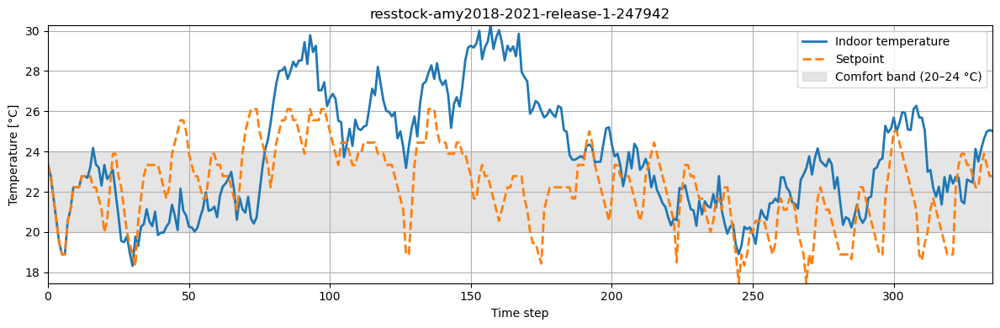

In [212]:
plot_comfort(env)

In [213]:
import numpy as np

def comfort_rmse(env):
    b = env.unwrapped.buildings[0]
    Tin = np.array(b.energy_simulation.indoor_dry_bulb_temperature)

    obs_names = env.observation_names[0]
    i_hsp = obs_names.index("indoor_dry_bulb_temperature_heating_set_point")

    Tsp = np.array([
        env.unwrapped.buildings[0]
           .energy_simulation.indoor_dry_bulb_temperature_heating_set_point[t]
        for t in range(len(Tin))
    ])

    return np.sqrt(np.mean((Tin - Tsp) ** 2))


In [222]:
def evaluate_mpc_params(env_factory, dyn, params, seed=0):
    env = env_factory(seed=seed)

    mpc = LSTMBlackBoxMPC_NoClone_1B(
        env=env,
        dynamics=dyn,
        horizon=6,
        n_samples=128,
        u_min=0.0,
        u_max=1.0,
        lambda_u=params["lambda_u"],
        w_cold=params["w_cold"],
        w_hot=params["w_hot"],
        a=params["a"],
        b=params["b"],
        lambda_du=params["lambda_du"],
        seed=seed
    )

    obs, _ = env.reset()
    done = False

    while not done:
        action = mpc.predict(obs)
        obs, _, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

    rmse = comfort_rmse(env)
    return rmse


In [223]:
param_grid = {
    "lambda_u":[1, 10, 100, 500, 1000],
    "w_cold": [1, 10, 20, 50, 100, 200],
    "w_hot": [1, 10, 200, 400, 800],
    "a": [2.0],
    "b": [2.0, 2.3, 2.7, 3.0, 3.5],
    "lambda_du": [1, 10, 100, 500, 1000, 5000, 10000],
}


In [ ]:
import itertools

best_rmse = np.inf
best_params = None
results = []

keys = list(param_grid.keys())

for values in itertools.product(*param_grid.values()):
    params = dict(zip(keys, values))

    rmse = evaluate_mpc_params(
        env_factory=make_env,   # YOUR env constructor
        dyn=dyn,
        params=params,
        seed=0
    )

    results.append((rmse, params))

    print(f"RMSE={rmse:.3f} | {params}")

    if rmse < best_rmse:
        best_rmse = rmse
        best_params = params


In [ ]:
print("\n🏆 BEST PARAMETERS 🏆")
print(best_params)
print(f"Best RMSE = {best_rmse:.3f} °C")


In [41]:
env = make_env()
dyn = train_lstm(env)

mpc_sgd = SGDHeatingMPC_NoClone_1B(
    env=env,
    dynamics=dyn,
    horizon=24,
    sgd_iters=40,
    lr=0.05,
    lambda_u=0.2,
    w_cold=1.0,
    w_hot=10.0,
    lambda_du=1.0,
    device="cpu",
)

obs, _ = env.reset()
mpc_sgd.reset()

done = False
while not done:
    action = mpc_sgd.predict(obs)
    obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated


NameError: name 'SCHEMA_PATH' is not defined

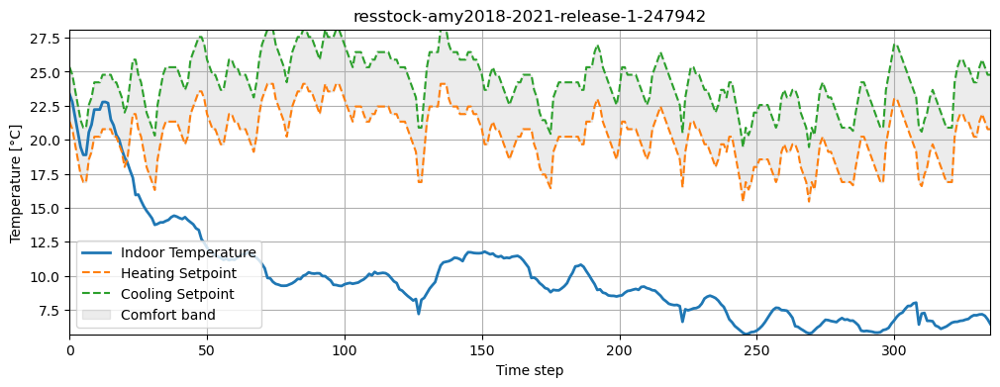

In [59]:
plot_comfort(env)

In [60]:
data = collect_training_data(env)
print("heat_dem mean", data["HeatDem"].mean(), "max", data["HeatDem"].max())
print("fraction zero", np.mean(data["HeatDem"] < 1e-6))


heat_dem mean 4.627873 max 9.771716
fraction zero 0.0


In [63]:
def test_lstm_heating_response(
    dyn,
    model_input,
    hidden_state,
    heat_low,
    heat_high,
    steps=24,
):
    """
    Compare LSTM open-loop response for low vs high heating_demand.
    Uses CityLearn's exact input construction rules.
    """

    names = dyn.input_observation_names
    iHeat = names.index("heating_demand")
    iTin = names.index("indoor_dry_bulb_temperature")

    def rollout(demand_norm):
        buf = copy.deepcopy(model_input)
        h = (hidden_state[0].clone(), hidden_state[1].clone())
        temps = []

        for _ in range(steps):
            # overwrite current heating_demand (normalized!)
            buf[iHeat][-1] = demand_norm

            # build X EXACTLY like CityLearn
            X_cols = []
            for i, name in enumerate(names):
                if name == "indoor_dry_bulb_temperature":
                    X_cols.append(buf[i][:-1])
                else:
                    X_cols.append(buf[i][1:])
            X = torch.tensor(np.array(X_cols), dtype=torch.float32).T.unsqueeze(0)

            # forward
            y_norm, h = dyn(X, h)
            temps.append(y_norm.item())

            # update indoor temperature in buffer
            buf[iTin][-1] = y_norm.item()

        return np.array(temps)

    low = rollout(heat_low)
    high = rollout(heat_high)
    return low, high


In [64]:
iHeat = dyn.input_observation_names.index("heating_demand")
heat_min = dyn.input_normalization_minimum[iHeat]
heat_max = dyn.input_normalization_maximum[iHeat]

heat_low  = (0.0 - heat_min) / (heat_max - heat_min + 1e-8)
heat_high = (0.9 * heat_max - heat_min) / (heat_max - heat_min + 1e-8)


In [65]:
low, high = test_lstm_heating_response(
    dyn,
    dyn._model_input,
    dyn._hidden_state,
    heat_low=heat_low,
    heat_high=heat_high,
)


In [66]:
low

array([0.38428745, 0.38164616, 0.37459731, 0.37355745, 0.37349027,
       0.37349445, 0.37349617, 0.37349638, 0.37349635, 0.37349638,
       0.37349638, 0.37349635, 0.37349641, 0.37349641, 0.37349641,
       0.37349641, 0.37349641, 0.37349641, 0.37349641, 0.37349641,
       0.37349641, 0.37349641, 0.37349641, 0.37349641])

In [67]:
high

array([0.44577378, 0.46187478, 0.4552713 , 0.45374614, 0.45357376,
       0.45356953, 0.45357215, 0.45357275, 0.45357287, 0.45357287,
       0.45357281, 0.45357281, 0.45357281, 0.45357281, 0.45357281,
       0.45357281, 0.45357281, 0.45357281, 0.45357281, 0.45357281,
       0.45357281, 0.45357281, 0.45357281, 0.45357281])